## Activities of Daily Living(ADL) Decline Prediction 
**Research question:** Among adults aged 65+ with no ADL limitation at baseline (ADL = 0), can baseline characteristics predict a NEW
ADL limitation (follow-up ADL >= `ADL_CUTOFF`) at the next available SHARE wave?

This project investigates whether baseline demographic, health,
physical, mental-health, socioeconomic, and cognitive characteristics
can predict the development of a new Activities of Daily Living (ADL)
limitation at the next available SHARE survey wave among adults aged
65+ who have no ADL limitation at baseline.

The analysis includes:
- longitudinal SHARE wave matching
- ADL outcome construction
- exploratory data analysis
- feature correlation and missingness analysis
- principal component analysis (PCA)
- Logistic Regression
- PCA + Logistic Regression
- Random Forest
- model evaluation and comparison
- threshold selection using a validation period
- final evaluation on later SHARE waves

The primary prediction outcome is:
    0 = no new ADL decline
    1 = new ADL decline

The primary predictive models use the selected baseline features,
while activity, social help, and smoking are considered in extended
or sensitivity analyses.


In [ ]:

import warnings, os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder, SplineTransformer
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss,
                             precision_recall_curve, roc_curve, precision_score,
                             recall_score, f1_score)
from sklearn.calibration import calibration_curve
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)

# ----------------------------- CONFIG ---------------------------------------
DATA_PATH   = os.environ.get("EASYSHARE_PATH")
ADL_CUTOFF  = int(os.environ.get("ADL_CUTOFF", 1))   # MAIN DESIGN (team decision): follow-up ADL > 0, i.e. >= 1. Use 2 only for sensitivity
WAVE_PAIRS  = [(1, 2), (4, 5), (5, 6), (6, 7), (7, 8), (8, 9)]   # wave 3 (SHARELIFE) has no ADL
DEV_BASE, VAL_BASE, TEST_BASE = [1, 4, 5], [6], [7, 8]          # baseline waves per period
RANDOM_STATE = 42
FAST = bool(int(os.environ.get("EASYSHARE_FAST", "0")))        # 1 = quick smoke run
N_BOOT = 20 if FAST else 200
HC002_MODE = os.environ.get("HC002_MODE", "raw")      # doctor visits: "raw" (documented results) or "log" (log1p of values capped at the 99.5th percentile; see see the doctor-visit sensitivity analysis)
MISSING_CODES = [-3, -4, -7, -9, -10, -11, -12, -13, -14, -15, -16]

### Loading the data 

In [2]:
df_raw = pd.read_stata(DATA_PATH, convert_categoricals=False)
print(df_raw.shape)

(488400, 108)


### Checking the missing values in the raw data

Before finalising the predictor variables, we check the raw data for negative values. 

SHARE data has negative numeric codes for different types of missing, non-response, or non-applicable observations. 
We have restricted this analysis to the baseline-eligible population such as Age >= 65 and ADL(Activities of Daily Living) = 0 at the baseline.

We are looking for variables that are useful to predict new ADL decline in the next SHARE wave. For this candidate variable, we calculate the percentage of eligible
rows containing a negative code, separately by survey wave.

In [3]:
audit_vars = [
    v for v in [
        "female",
        "sphus",
        "chronic_mod",
        "maxgrip",
        "eurod",
        "bmi",
        "thinc_m"
    ]
    if v in df_raw
]

# Define the baseline-eligible population:
# adults aged 65+ with ADL = 0.
elig_raw = df_raw[
    (df_raw["age"] >= 65) &
    (df_raw["adla"] == 0)
]

# Identify the percentage of eligible observations
# containing negative special codes, by wave.
audit = (
    elig_raw
    .assign(
        **{
            v: (elig_raw[v] < 0)
            for v in audit_vars
        }
    )
    .groupby("wave")[audit_vars]
    .mean()
    .mul(100)
    .round(1)
)

print(
    "% of baseline-eligible rows (age >= 65, ADL = 0) "
    "with a negative code, by wave"
)
print("------------------------------------------------------------------------------------------")
print(audit)

print("\nRaw summary statistics:")
print("------------------------------------------------------------------------------------------")
print(
    elig_raw[audit_vars]
    .describe()
    .loc[["count", "mean", "std", "min", "max"]]
    .round(2)
)

% of baseline-eligible rows (age >= 65, ADL = 0) with a negative code, by wave
------------------------------------------------------------------------------------------
      female  sphus  chronic_mod  maxgrip  eurod  bmi  thinc_m
wave                                                          
1        0.0    0.2          0.1      7.2    1.9  1.8      7.4
2        0.0    0.1          0.1      8.7    2.2  3.2      0.0
4        0.0    0.1          0.1      7.6    2.2  4.6      0.0
5        0.0    0.1          0.1      8.0    2.2  2.5      0.0
6        0.0    0.0          0.0      7.4    3.4  2.4      0.0
7        0.0    0.1          0.2      8.7   76.2  3.5     75.6
8        0.0    0.1          0.1      7.1    2.3  2.8      0.0
9        0.0    0.1          0.1      8.7    2.4  3.0      0.0

Raw summary statistics:
------------------------------------------------------------------------------------------
          female      sphus  chronic_mod    maxgrip      eurod        bmi     thinc_

**Result:** 

The analysis of raw data shows that several candidate variables contain negative
special codes in the raw data. The most notable pattern occurs in
Wave 7, where 76.2% of eligible observations have negative codes
for EURO-D and 75.6% have negative codes for household income.

The raw summary statistics also show impossible or suspicious values,
such as a minimum of -15 for several variables and values such as
99 for maximum grip strength and approximately 99 for BMI.

These findings confirm that the raw numeric values cannot be used
directly for statistical analysis. Special codes must first be
converted to missing values, followed by appropriate validity-range
checks before the variables are used for correlation, PCA, or
predictive modeling.

## Cleaning and feature engineering

The raw dataset contains special negative codes for missing,
non-response, or non-applicable values. It also contains some values
that require plausibility checks before statistical analysis.

The cleaning function performs the following steps:

1. Converts special negative codes to missing values (NaN).
2. Excludes identifier/time variables from the negative-code masking step.
3. Applies plausibility limits to selected variables such as BMI.
4. Creates cleaned ADL and cognitive-recall variables.
5. Converts selected categorical variables into binary indicators.
6. Creates physical activity, education, income, household, and grip-strength
   derived variables.
7. Applies an income transformation to account for household size and
   right-skewness.
8. Creates a household cluster key for later grouped analyses.
9. Preserves the original variables while adding cleaned/derived variables.

The purpose of this step is to ensure that special codes and implausible
values do not enter the correlation analysis, PCA, or machine-learning
models as if they were valid measurements.

In [4]:
def clean_easyshare(df, mask_codes=True):
    """
        Clean raw variables and create analysis-ready features.
    
        The function handles special missing-value codes, applies
        plausibility checks, cleans ADL and recall variables, recodes selected
        categorical variables, and creates derived variables for the ADL
        prediction analysis.
    
        Args:
            df: Raw easySHARE dataset.
            mask_codes: If True, replace values listed in MISSING_CODES with
                missing values.
    
        Returns:
            A copy of the input DataFrame containing the original variables
            together with cleaned and derived analysis variables.
        """

    out = df.copy()
    if mask_codes:
        skip = {"wave", "int_year", "int_month", "wavepart"}
        num = [c for c in out.select_dtypes(include=[np.number]).columns if c not in skip]
        out[num] = out[num].mask(out[num].isin(MISSING_CODES))
        left = (out[num] < 0).sum()
        left = left[left > 0]
        if len(left):
            print("Negative values left after masking (check manually):\n", left)
        # plausibility limits (values that survive the missing-code masking but are impossible)
        if "bmi" in out:
            out["bmi"] = out["bmi"].where(out["bmi"].between(12, 60))          # raw data contain BMI up to 99
        if "thinc_m" in out:
            out["thinc_m"] = out["thinc_m"].clip(upper=out["thinc_m"].quantile(0.999))   # raw max is ~9.6 million

    new = {}                                          # all derived columns are collected and added ONCE (no fragmentation)
    new["adla_clean"] = out["adla"].where(out["adla"].between(0, 5))
    new["recall_imm"] = out["recall_1"].where(out["recall_1"].between(0, 10))
    new["recall_del"] = out["recall_2"].where(out["recall_2"].between(0, 10))
    new["current_smoker"] = out["smoking"].map({1: 1, 5: 0})
    new["received_help"] = out["sp002_mod"].map({1: 1, 5: 0})
    new["given_help"] = out["sp008_"].map({1: 1, 5: 0})
    new["living_with_partner"] = out["partnerinhh"].map({1: 1, 3: 0})
    new["hospital_stay"] = out["hc012_"].map({1: 1, 5: 0})
    new["activity_low"] = out["br015_"].where(out["br015_"].between(1, 4))     # 1 = >1x/week ... 4 = hardly ever
    new["isced"] = out["isced1997_r"].where(out["isced1997_r"].between(0, 6))

    # income: household net income is right-skewed and household-level -> equivalise + log
    hh = out["hhsize"].where(out["hhsize"] > 0)
    new["log_income_eq"] = np.log1p(out["thinc_m"].clip(lower=0) / np.sqrt(hh))
    # wave-specific income percentile -> one column
    inc = pd.Series(np.nan, index=out.index)
    for w in sorted(out["wave"].unique()):
        col = f"income_pct_w{int(w)}"
        if col in out.columns:
            m = out["wave"] == w
            inc[m] = out.loc[m, col]
    new["income_pct"] = inc

    # sex-specific low grip (EWGSOP2 cut-offs: <27 kg men, <16 kg women)
    ok = out["maxgrip"].notna() & out["female"].notna()
    new["grip_low"] = pd.Series(np.where(ok, np.where(out["female"] == 1, out["maxgrip"] < 16, out["maxgrip"] < 27), np.nan), index=out.index)

    if "hc002_mod" in out:                                       # doctor visits are extremely right-skewed (a few values near 100)
        cap = out["hc002_mod"].quantile(0.995)
        new["hc002_log"] = np.log1p(out["hc002_mod"].clip(lower=0, upper=cap))

    new["hh_key"] = out["mergeid"].astype(str).str[:9]       # household cluster (couples share it)
    out = pd.concat([out, pd.DataFrame(new)], axis=1)
    out["country"] = pd.Categorical(out["country"])
    return out.copy()


df = clean_easyshare(df_raw, mask_codes=True)
cmp = pd.DataFrame({
    "raw_mean": elig_raw[audit_vars].mean(), "raw_sd": elig_raw[audit_vars].std(),
    "clean_mean": df.loc[elig_raw.index, audit_vars].mean(), "clean_sd": df.loc[elig_raw.index, audit_vars].std(),
    "clean_%missing": df.loc[elig_raw.index, audit_vars].isna().mean() * 100}).round(2)
print(cmp)
if "hc002_mod" in df:
    print("\nDoctor visits (hc002_mod), baseline-eligible rows - quantiles (extreme right tail):")
    print(df.loc[elig_raw.index, "hc002_mod"].quantile([.5, .9, .99, .995, 1]).round(1).to_string())

             raw_mean    raw_sd  clean_mean  clean_sd  clean_%missing
female           0.55      0.50        0.55      0.50            0.00
sphus            3.22      1.07        3.23      0.99            0.07
chronic_mod      1.38      1.32        1.40      1.23            0.11
maxgrip         27.48     16.17       31.17     10.67            7.99
eurod            0.28      5.13        2.29      2.14           15.50
bmi             25.63      7.89       26.80      4.31            3.05
thinc_m      23171.79  45906.95    26526.77  28712.57           13.76

Doctor visits (hc002_mod), baseline-eligible rows - quantiles (extreme right tail):
0.500     4.0
0.900    14.0
0.990    40.0
0.995    52.0
1.000    98.0


**Result:** 

After masking SHARE special codes and applying plausibility checks,
the distributions of the candidate variables became substantially
more plausible. 

EURO-D had a mean of 2.29 (SD = 2.14), grip strength
had a mean of 31.2 kg, and BMI had a mean of 26.8 (SD = 4.3).

The cleaning step also showed that
grip strength had 8.0% missingness, EURO-D 15.5%, BMI 3.1%, and
household income 13.8%.

Missing observations were retained rather than removed. Missing
predictor values were handled within the model pipelines using
appropriate imputation or model-supported missing-value handling.

Doctor visits showed a strongly right-skewed distribution, with a
median of 4 visits, a 99.5th percentile of 52, and a maximum of 98.
The effect of upper-tail capping and log transformation is evaluated
separately.

## Creating Additional EDA Recoded Variables

Additional variables are created for exploratory data analysis (EDA).
These transformations make selected candidate variables easier to interpret
or place them in a consistent direction.

The resulting dataset is then restricted to participants aged 65+ for
the subsequent exploratory analysis.

In [5]:
def add_eda_recodes(d):
    """Create recoded variables for exploratory data analysis.

    The function creates additional variables that standardize the
    direction or coding of selected easySHARE variables for exploratory
    analysis. It preserves the original variables and appends the
    recoded variables to the DataFrame.

    Args:
        d: DataFrame containing cleaned easySHARE variables.

    Returns:
        A copy of the input DataFrame with additional EDA recoded
        variables.
    """

    def has(*c):
        """Check whether all given columns exist in the data.

        Args:
            *c: Column names.

        Returns:
            True if every column is present, otherwise False.
        """
        return all(x in d.columns for x in c)

    new = {}
    if has("recall_1"):    new["recall_1_worse"] = 10 - d["recall_1"]
    if has("recall_2"):    new["recall_2_worse"] = 10 - d["recall_2"]
    if has("numeracy_1"):  new["numeracy_1_worse"] = 6 - d["numeracy_1"]
    yes_no = {"ever_smoked": "ever_smoked_binary", "int_partner": "partner_interview_available",
              "mother_alive": "mother_alive_binary", "father_alive": "father_alive_binary",
              "ch007_hh": "child_in_household", "ch007_km": "child_within_1km", "vaccinated": "vaccinated_binary",
              "ep036_mod": "early_retirement_preference", "dn004_mod": "born_in_interview_country"}
    for src, dst in yes_no.items():
        if src in d.columns: new[dst] = d[src].map({1: 1, 5: 0})
    if has("hc029_"):          new["nursing_home_stay"] = d["hc029_"].map({1: 1, 3: 1, 5: 0})
    if has("childhood_health"): new["childhood_health_ordered"] = d["childhood_health"].where(d["childhood_health"].between(1, 5))
    if has("isced1997_r"):     new["isced1997_ordered"] = d["isced1997_r"].where(d["isced1997_r"].between(0, 6))
    return pd.concat([d, pd.DataFrame(new, index=d.index)], axis=1).copy()

df = add_eda_recodes(df)
df_65 = df[df["age"] >= 65].copy()
print("Age >= 65 observations:", len(df_65), "| unique respondents:", df_65["mergeid"].nunique())

Age >= 65 observations: 274751 | unique respondents: 99787


## Variable Classification Before Correlation Analysis

Classification is necessary because different variable types
require different statistical methods.

The classification separates:

- identifiers and metadata, which should not be used as predictors.
- original variables that have been replaced by cleaned or recoded versions.
- binary categorical variables.
- ordinal categorical variables.
- count or score variables.
- continuous variables.
- nominal categorical variables.
- variables requiring additional review.

The classification is used to guide the correlation analysis and to
avoid including identifiers, metadata, or duplicated/replaced variables
as candidate predictors.

In [6]:
# ---- variable classification (before correlation analysis) ----
metadata_vars = {"mergeid", "hhid", "coupleid", "hh_key", "wave", "wavepart", "int_version", "int_year", "int_month",
                 "dn002_mod", "dn003_mod"}
original_replaced = {  # raw variables replaced by recoded versions
    "recall_1", "recall_2", "numeracy_1", "numeracy_2", "smoking", "partnerinhh", "isced1997_r", "sp002_mod", "sp008_",
    "ever_smoked", "int_partner", "mother_alive", "father_alive", "ch007_hh", "ch007_km", "vaccinated", "hc012_",
    "hc029_", "ep036_mod", "dn004_mod", "childhood_health", "bmi2", "adlwa", "iadla", "iadlza", "mobilityind",
    "lgmuscle", "grossmotor", "finemotor"}
binary_vars = {"female", "gender_partner", "current_smoker", "ever_smoked_binary", "received_help", "given_help",
               "living_with_partner", "partner_interview_available", "mother_alive_binary", "father_alive_binary",
               "child_in_household", "child_within_1km", "vaccinated_binary", "hospital_stay", "nursing_home_stay",
               "early_retirement_preference", "born_in_interview_country", "grip_low"} | {f"euro{i}" for i in range(1, 13)}
ordinal_vars = {"sphus", "br010_mod", "br015_", "activity_low", "co007_", "isced1997_ordered", "childhood_health_ordered",
                "books_age10", "maths_age10", "language_age10", "ep026_mod", "ep011_mod", "bfi10_extra_mod",
                "bfi10_agree_mod", "bfi10_consc_mod", "bfi10_neuro_mod", "bfi10_open_mod", "orienti", "isced"}
count_vars = {"chronic_mod", "hhsize", "siblings_alive", "ch001_", "ch021_mod", "hc002_mod", "eurod", "casp",
              "recall_1_worse", "recall_2_worse", "recall_imm", "recall_del", "numeracy_1_worse", "adla", "adla_clean"}
continuous_vars = {"hc002_log", "age", "age_partner", "bmi", "maxgrip", "eduyears_mod", "thinc_m", "log_income_eq", "ep013_mod"}
nominal_vars = {"mar_stat", "q34_re", "iv009_mod", "ep005_", "ep009_mod", "sp003_1_mod", "sp003_2_mod", "sp003_3_mod",
                "sp009_1_mod", "sp009_2_mod", "sp009_3_mod", "country", "country_mod", "birth_country", "citizenship", "language"}

def classify(v):
    """Classifying a variable according to its analytical role and data type.

    Args:
        v: Variable name to classify.

    Returns:
        A string describing the analytical classification of the variable.
    """
    if v in metadata_vars: return "Identifier / metadata"
    if v == "numeracy_2": return "Needs coding verification"
    if v in original_replaced: return "Original (replaced by recode / functional index)"
    if v.startswith("income_pct"): return "Wave-specific income percentile"
    for name, s in [("Binary categorical", binary_vars), ("Ordinal categorical", ordinal_vars), ("Count / score", count_vars),
                    ("Continuous", continuous_vars), ("Nominal categorical", nominal_vars)]:
        if v in s: return name
    return "Needs review"

var_class = pd.DataFrame({"Variable": df_65.columns, "Type": [classify(v) for v in df_65.columns],
                          "Data type": [str(df_65[v].dtype) for v in df_65.columns],
                          "Unique values": [df_65[v].nunique(dropna=True) for v in df_65.columns],
                          "Missing (%)": [round(df_65[v].isna().mean() * 100, 2) for v in df_65.columns]})
var_class = var_class.sort_values(["Type", "Variable"]).reset_index(drop=True)
OUT = os.environ.get("EASYSHARE_OUT", "easyshare_outputs"); os.makedirs(OUT, exist_ok=True)
var_class.to_csv(f"{OUT}/ADL_variable_classification_age65.csv", index=False)
print(var_class["Type"].value_counts())
print("\nStill needing review:", var_class.loc[var_class["Type"] == "Needs review", "Variable"].tolist())

Type
Binary categorical                                  30
Original (replaced by recode / functional index)    28
Ordinal categorical                                 19
Nominal categorical                                 16
Count / score                                       15
Identifier / metadata                               11
Continuous                                           9
Wave-specific income percentile                      9
Needs coding verification                            1
Name: count, dtype: int64

Still needing review: []


**Result:** 

The variables were classified by analytical type to determine the appropriate methods for correlation and exploratory analysis.
Identifiers, replaced variables, categorical, ordinal, count, continuous, and nominal variables were separated, with unclear variables flagged for review.

## Exploratory Spearman Correlation Analysis

We identify candidate numerical variables that are suitable for
Spearman correlation analysis with ADL.

Variables that are identifiers, metadata, nominal categories, original
variables replaced by recoded versions, ADL outcomes, or derived
duplicates are excluded.

Spearman correlation is calculated separately for each available wave
and across all waves among adults aged 65+.

The analysis measures the strength and direction of the monotonic
association between each candidate variable and ADL. This is an
exploratory analysis and does not imply causation.

Variables are ranked according to the absolute correlation observed
across all waves. The corresponding sample-size matrix is also saved
because missingness can cause the number of observations used for each
correlation to differ.

Number of candidate variables: 53


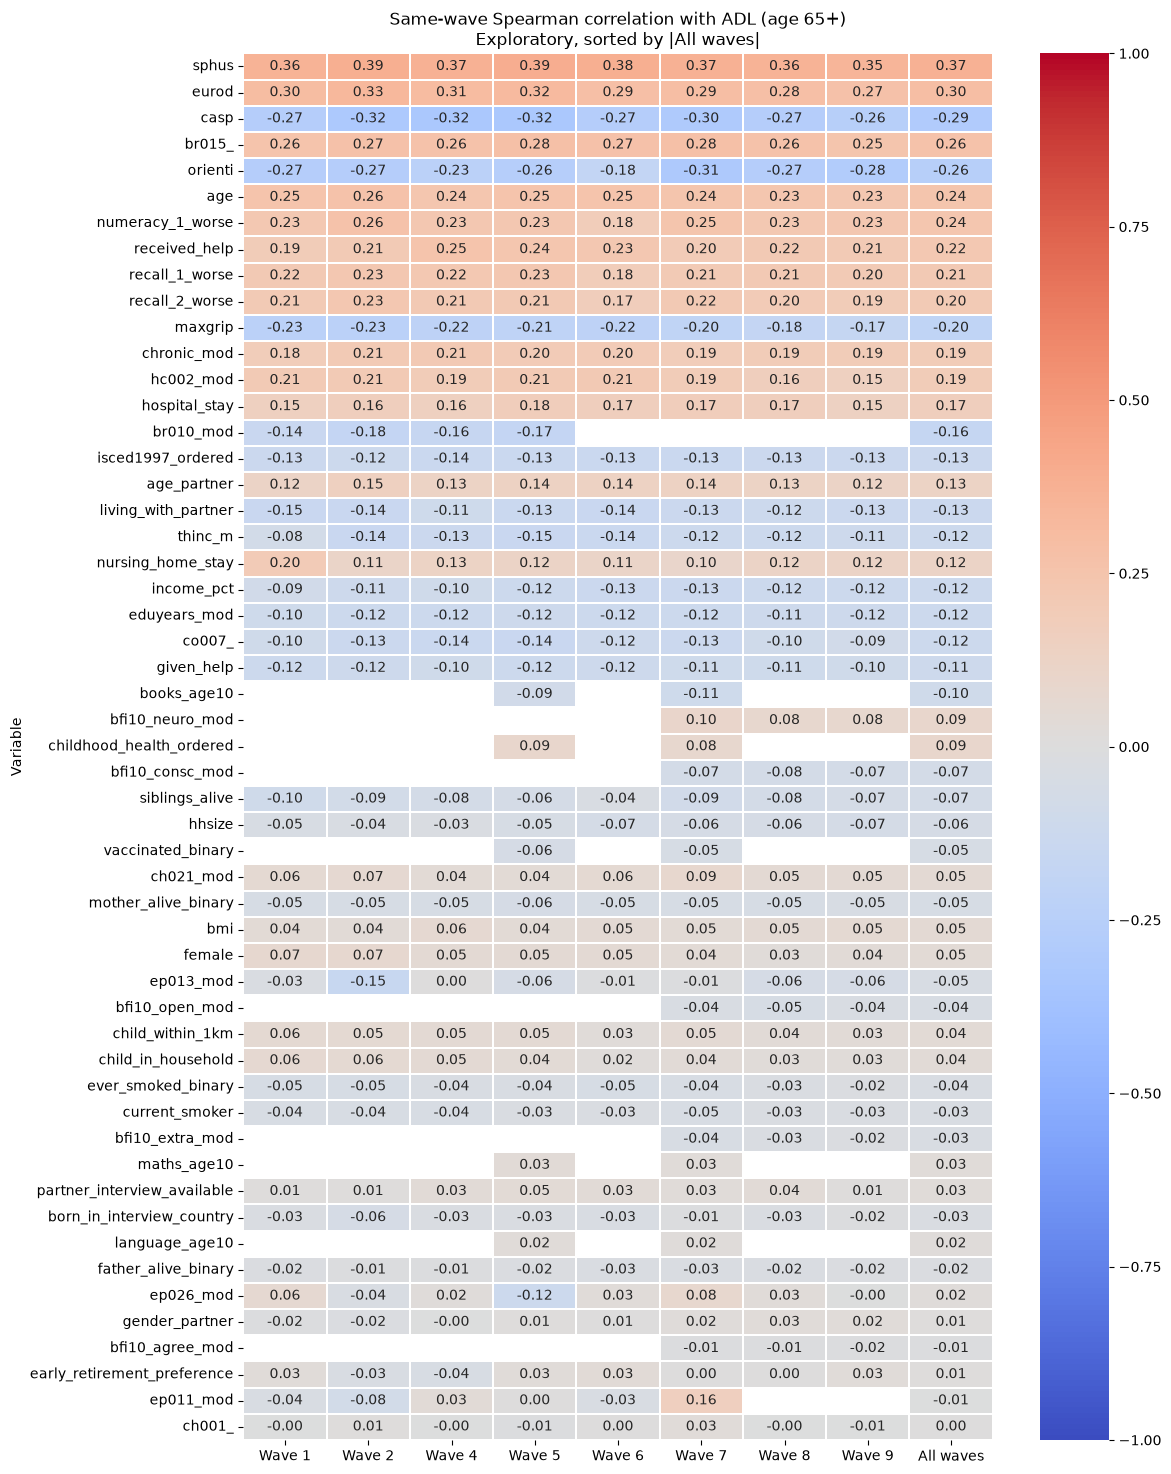

In [7]:
# ---- candidate variables (numeric, Spearman-suitable) ----
exclude_vars = (metadata_vars | original_replaced | nominal_vars | {"adla", "adla_clean", "adlwa", "numeracy_2", "grip_low"}
                | {f"income_pct_w{w}" for w in range(1, 10)} | {f"euro{i}" for i in range(1, 13)}
                | {"log_income_eq", "recall_imm", "recall_del", "isced", "activity_low", "hc002_log"})   # euro1-12 are the items of eurod; others are derived duplicates
candidate_variables = [c for c in df_65.select_dtypes(include=np.number).columns if c not in exclude_vars]
print("Number of candidate variables:", len(candidate_variables))

def calculate_corr(data, variable):
    """Calculating the Spearman correlation between a variable and ADL.

    Args:
        data: DataFrame containing the candidate variable and cleaned ADL.
        variable: Name of the candidate variable to correlate with ADL.

    Returns:
        A tuple containing the Spearman correlation coefficient and
        the number of complete observations used in the calculation.
    """
    t = pd.DataFrame({"x": data[variable], "adla": data["adla_clean"]}).dropna()
    if len(t) < 30 or t["adla"].nunique() <= 1 or t["x"].nunique() <= 1:
        return np.nan, len(t)
    return spearmanr(t["x"], t["adla"])[0], len(t)

from scipy.stats import spearmanr
EDA_WAVES = [1, 2, 4, 5, 6, 7, 8, 9]
corr_matrix, n_matrix = {}, {}
for v in candidate_variables:
    c_row, n_row = {}, {}
    for w in EDA_WAVES:
        c_row[f"Wave {w}"], n_row[f"Wave {w}"] = calculate_corr(df_65[df_65["wave"] == w], v)
    c_row["All waves"], n_row["All waves"] = calculate_corr(df_65, v)
    corr_matrix[v], n_matrix[v] = c_row, n_row
corr_matrix = pd.DataFrame.from_dict(corr_matrix, orient="index")
n_matrix = pd.DataFrame.from_dict(n_matrix, orient="index")
corr_matrix = corr_matrix.loc[corr_matrix["All waves"].abs().sort_values(ascending=False).index]
n_matrix = n_matrix.reindex(corr_matrix.index)                   # same order as the correlation table
corr_matrix.index.name = n_matrix.index.name = "Variable"
corr_matrix.round(3).to_csv(f"{OUT}/ADL_correlation_matrix_age65.csv")
n_matrix.astype(int).to_csv(f"{OUT}/ADL_correlation_sample_sizes_age65.csv")

fig_h = max(6, 0.28 * len(corr_matrix))
plt.figure(figsize=(12, fig_h))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, linewidths=.3, linecolor="white")
plt.title("Same-wave Spearman correlation with ADL (age 65+)\nExploratory, sorted by |All waves|")
plt.tight_layout(); plt.savefig(f"{OUT}/ADL_ALL_variables_age65_heatmap.png", dpi=200); plt.show()

**Result:** 

- positive value → higher variable values are associated with higher ADL

- negative value → higher variable values are associated with lower ADL

- value near 0 → weak monotonic association

## Research Candidate Predictors: Correlation with ADL

From the broader set of numerically suitable variables, we define a
focused group of research-relevant candidate predictors based on their
conceptual relevance to ageing, health, physical function, cognition,
socioeconomic status, and social characteristics.

The selected variables are evaluated using the previously calculated
same-wave Spearman correlations with ADL among adults aged 65+.

The resulting heatmap is sorted by the absolute correlation with ADL
across all waves to make the strongest associations easier to identify.

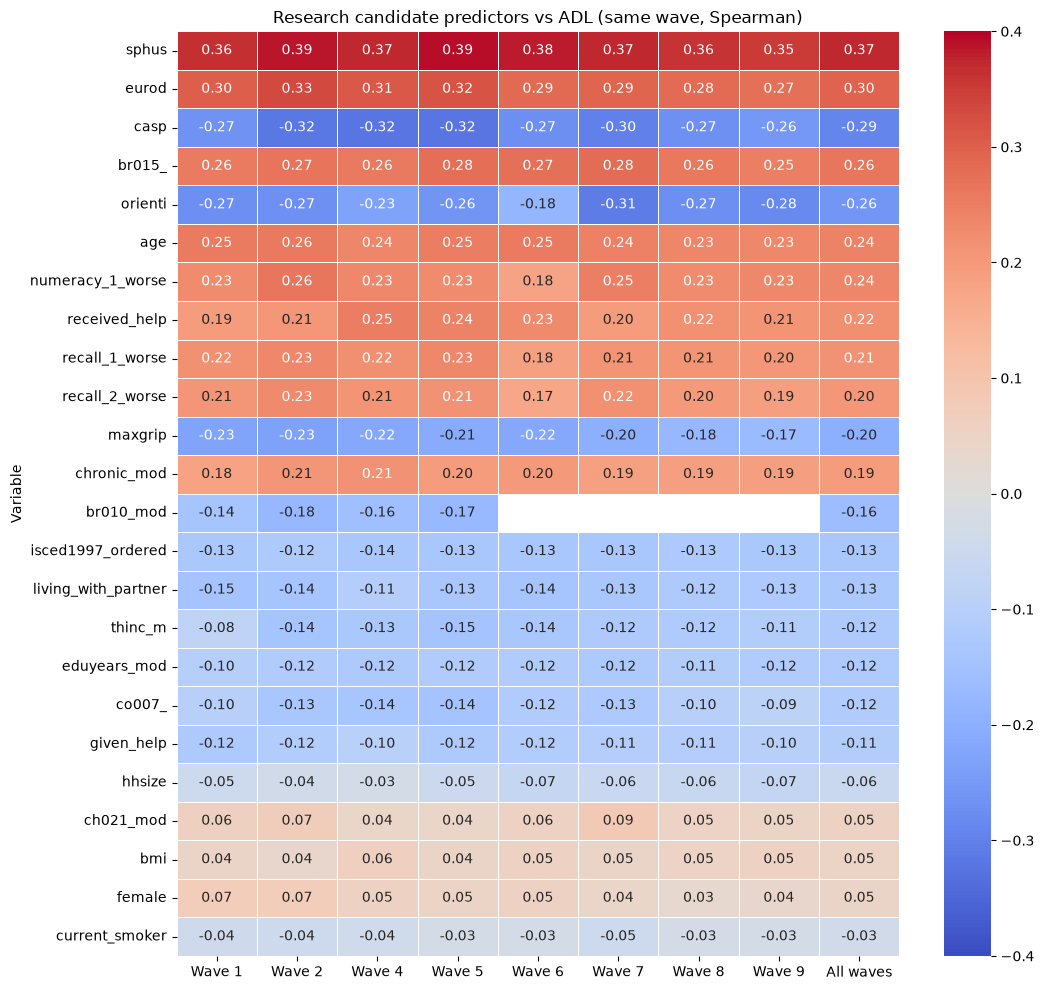

Reminder: this is a same-wave association. Part B uses baseline -> next wave among people with ADL = 0.


In [8]:
selected_predictors = ["age", "female", "sphus", "chronic_mod", "maxgrip", "bmi", "eurod", "casp", "br015_",
                       "current_smoker", "br010_mod", "recall_1_worse", "recall_2_worse", "orienti", "numeracy_1_worse",
                       "isced1997_ordered", "eduyears_mod", "thinc_m", "co007_", "living_with_partner", "hhsize",
                       "ch021_mod", "received_help", "given_help"]
selected_predictors = [v for v in selected_predictors if v in corr_matrix.index]
heatmap2 = corr_matrix.loc[selected_predictors]
heatmap2 = heatmap2.loc[heatmap2["All waves"].abs().sort_values(ascending=False).index]
heatmap2.round(3).to_csv(f"{OUT}/ADL_research_candidate_heatmap_age65.csv")
plt.figure(figsize=(11, 10))
sns.heatmap(heatmap2, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-0.4, vmax=0.4, linewidths=.5, linecolor="white")
plt.title("Research candidate predictors vs ADL (same wave, Spearman)")
plt.tight_layout(); plt.savefig(f"{OUT}/ADL_research_candidate_heatmap_age65.png", dpi=200); plt.show()
print("Reminder: this is a same-wave association. Part B uses baseline -> next wave among people with ADL = 0.")

**Result:** 

- Positive correlation → higher values of the variable are associated with higher ADL scores in the same wave.
- Negative correlation → higher values are associated with lower ADL scores.
- Near 0 → little monotonic association.
- The “All waves” column summarizes the association across all available waves.

## Construct the Longitudinal Prediction Dataset

The prediction task requires information from two different SHARE waves.

For each selected baseline → follow-up wave pair, we are

1. Selecting participants aged 65+ who have ADL = 0 at baseline.
2. Keeping the selected baseline predictor variables.
3. Matching participants to their next available wave using `mergeid`.
4. Requiring a valid follow-up ADL measurement.
5. Calculating the follow-up interval in years.
6. Creating the binary outcome indicating whether a new ADL limitation
   developed at follow-up.
7. Creating optional trend variables describing changes in selected
   health characteristics between the previous regular wave and the
   baseline wave.

This creates the longitudinal prediction structure such that

**Baseline characteristics → Future ADL outcome**

The baseline predictors are measured before the outcome, which is
essential for a valid prediction analysis.

Wave 3 is excluded from the regular transition structure because it
does not provide the ADL information required for this prediction
design.

## Baseline -> follow-up pairs (+ attrition)

In [9]:
BASE_COLS = ["mergeid", "hh_key", "wave", "int_year", "country", "age", "female", "sphus", "chronic_mod",
             "maxgrip", "eurod", "bmi", "thinc_m", "log_income_eq", "income_pct", "recall_imm", "recall_del",
             "casp", "current_smoker", "activity_low", "received_help", "given_help", "living_with_partner",
             "hhsize", "eduyears_mod", "isced", "hc002_mod", "hc002_log", "hospital_stay", "grip_low",
             "mobilityind", "lgmuscle", "iadla", "iadlza", "adla_clean"]
missing_cols = [c for c in BASE_COLS if c not in df.columns]
if missing_cols:
    print("Not in data, skipped:", missing_cols)
BASE_COLS = list(dict.fromkeys(BASE_COLS + [c for c in candidate_variables if c not in ('adla',)]))
BASE_COLS = [c for c in BASE_COLS if c in df.columns]

# Trend features: change between the PREVIOUS regular wave and the baseline wave (wave 3 = SHARELIFE has no regular data -> 4 follows 2)
PREV_WAVE = {2: 1, 4: 2, 5: 4, 6: 5, 7: 6, 8: 7, 9: 8}
TREND_VARS = [v for v in ["sphus", "maxgrip", "chronic_mod", "eurod", "bmi", "recall_imm", "mobilityind", "lgmuscle"] if v in BASE_COLS]


def build_pairs(data, wave_pairs):
    """Constructing baseline-to-follow-up prediction pairs across SHARE waves.

    For each specified wave pair, the function selects adults aged 65+
    with ADL = 0 at baseline, matches them to the follow-up wave using
    mergeid, and creates variables required for longitudinal prediction.

    Args:
        data: Cleaned easySHARE DataFrame containing longitudinal
            observations.
        wave_pairs: List of tuples containing baseline and follow-up
            SHARE wave numbers.

    Returns:
        A DataFrame containing matched baseline-to-follow-up
        observations, follow-up ADL outcomes, follow-up intervals,
        previous-wave information, and trend variables.
    """
    parts = []
    for b, f in wave_pairs:
        base = data.loc[(data["wave"] == b) & (data["age"] >= 65) & (data["adla_clean"] == 0), BASE_COLS].rename(
            columns={"wave": "baseline_wave", "int_year": "baseline_year", "adla_clean": "adla_baseline"})
        fu = data.loc[(data["wave"] == f) & data["adla_clean"].notna(), ["mergeid", "int_year", "adla_clean"]].rename(
            columns={"int_year": "followup_year", "adla_clean": "adla_followup"})
        assert base["mergeid"].is_unique and fu["mergeid"].is_unique
        m = base.merge(fu, on="mergeid", how="left")
        m["followup_wave"] = f
        pw = PREV_WAVE.get(b)
        if pw is not None:
            pv = data.loc[data["wave"] == pw, ["mergeid", "int_year"] + TREND_VARS].rename(
                columns={**{v: "prev_" + v for v in TREND_VARS}, "int_year": "prev_year"})
            assert pv["mergeid"].is_unique
            m = m.merge(pv, on="mergeid", how="left")
        else:
            for v in TREND_VARS + ["year"]:
                m["prev_" + v] = np.nan
        trend = {"d_" + v: m[v] - m["prev_" + v] for v in TREND_VARS}      # positive = value increased since the previous wave
        trend["prev_gap_years"] = m["baseline_year"] - m["prev_year"]
        m = pd.concat([m, pd.DataFrame(trend, index=m.index)], axis=1)
        parts.append(m)
    out = pd.concat(parts, ignore_index=True)
    out["has_followup"] = out["adla_followup"].notna()
    out["interval_years"] = out["followup_year"] - out["baseline_year"]
    return out


eligible = build_pairs(df, WAVE_PAIRS)
att = eligible.groupby("baseline_wave")["has_followup"].agg(eligible="size", followed="sum")
att["retained_%"] = (att["followed"] / att["eligible"] * 100).round(1)
print("Attrition: baseline-eligible people (age>=65, ADL=0) who have a valid ADL at the next wave")
print(att)

pairs = eligible[eligible["has_followup"]].copy()
pairs["y_ge1"] = (pairs["adla_followup"] >= 1).astype(int)
pairs["y_ge2"] = (pairs["adla_followup"] >= 2).astype(int)
pairs["y"] = (pairs["adla_followup"] >= ADL_CUTOFF).astype(int)
# wave-7 SHARELIFE respondents: regular variables are coded -10 in the raw file (guide, section 4); flag them for the SHARELIFE sensitivity analysis
_sl_ids = set(df_raw.loc[(df_raw["wave"] == 7) & ((df_raw["thinc_m"] == -10) | (df_raw["eurod"] == -10)), "mergeid"])
pairs["sharelife7"] = (pairs["baseline_wave"] == 7) & pairs["mergeid"].isin(_sl_ids)
print(f"Wave-7 SHARELIFE baseline pairs: {int(pairs['sharelife7'].sum()):,} of {int((pairs['baseline_wave'] == 7).sum()):,} wave-7 pairs")
print(f"\nPairs: {len(pairs):,}  | event rate (ADL >= {ADL_CUTOFF}): {pairs['y'].mean():.2%}  | ADL>=2 rate: {pairs['y_ge2'].mean():.2%}")
print(pairs.groupby("baseline_wave")[["y_ge1", "y_ge2"]].mean().mul(100).round(2))
print("\nInterval (years):\n", pairs["interval_years"].value_counts().sort_index())

Attrition: baseline-eligible people (age>=65, ADL=0) who have a valid ADL at the next wave
               eligible  followed  retained_%
baseline_wave                                
1                 11157      7627        68.4
4                 23451     16405        70.0
5                 29232     21542        73.7
6                 32013     25238        78.8
7                 38564     21665        56.2
8                 29891     22678        75.9
Wave-7 SHARELIFE baseline pairs: 15,774 of 21,665 wave-7 pairs

Pairs: 115,155  | event rate (ADL >= 1): 9.63%  | ADL>=2 rate: 3.87%
               y_ge1  y_ge2
baseline_wave              
1               9.70   4.26
4              10.86   4.47
5              10.22   3.97
6               9.33   3.63
7              10.13   4.25
8               8.01   3.12

Interval (years):
 interval_years
1.0     3764
2.0    88616
3.0    22374
4.0      313
5.0       88
Name: count, dtype: int64


**Result:** 

Longitudinal Prediction Dataset

The longitudinal matching step produced 115,155 baseline to follow-up
prediction observations across six valid SHARE wave transitions.

All participants were aged 65+ and had ADL = 0 at baseline. The outcome
was defined as a new ADL limitation at the next available SHARE wave,
with follow-up ADL >= 1 classified as new_adl_decline = 1.

The overall event rate was approximately 9.6%, indicating an imbalanced
binary prediction problem. Decline rates across wave transitions were
relatively consistent, ranging from approximately 8% to 11%.

Follow-up intervals differ between pairs (77 % two years, 19 % three years, 3 % one year), so the outcome should be interpreted as ADL decline by the next available survey wave rather than decline within a fixed period.

Previous-wave information was also used to construct exploratory trend
variables measuring changes in selected health characteristics before
the baseline prediction wave.

## Baseline Predictors and Future ADL Decline

In this part, we now examine whether each candidate baseline variable contains
information about future ADL decline.

Each predictor is measured at the
baseline wave, while the outcome is measured at the subsequent wave.

The analysis is restricted to the development and validation periods
and does not use the final test period. This prevents the final test
set from influencing feature exploration or model development.

For each candidate variable, we calculate:

- the number of complete observations
- the percentage of missing values
- the Spearman correlation with the binary future-decline outcome
- the univariate ROC-AUC
- the direction of the association.

The univariate AUC measures how well each variable alone can distinguish
participants who later develop an ADL limitation from those who do not.
An AUC of 0.50 indicates no discrimination, while values farther from
0.50 indicate stronger discrimination.

Because a variable can have either a positive or negative relationship
with decline, the analysis uses the larger of AUC and 1 − AUC to measure
the strength of discrimination regardless of direction.

This is a univariate exploratory analysis. It does not determine the
final feature set because variables may provide useful information in
combination even when their individual AUC is weak.
This is the correlation analysis that matches the research question. Uses only the training period (baseline waves in `DEV_BASE + VAL_BASE`).

Outcome: follow-up ADL >= 1; training-period pairs only
                              N  Missing_%  Spearman_rho  Univariate_AUC            Direction
Variable                                                                                     
sphus                     70785        0.0         0.202           0.685  higher -> more risk
age                       70812        0.0         0.169           0.662  higher -> more risk
casp                      64785        8.5        -0.164           0.660  higher -> less risk
eurod                     69315        2.1         0.151           0.645  higher -> more risk
br015_                    70703        0.2         0.147           0.633  higher -> more risk
maxgrip                   66294        6.4        -0.129           0.628  higher -> less risk
recall_2_worse            69432        1.9         0.133           0.628  higher -> more risk
recall_1_worse            69473        1.9         0.131           0.625  higher -> more risk
age_

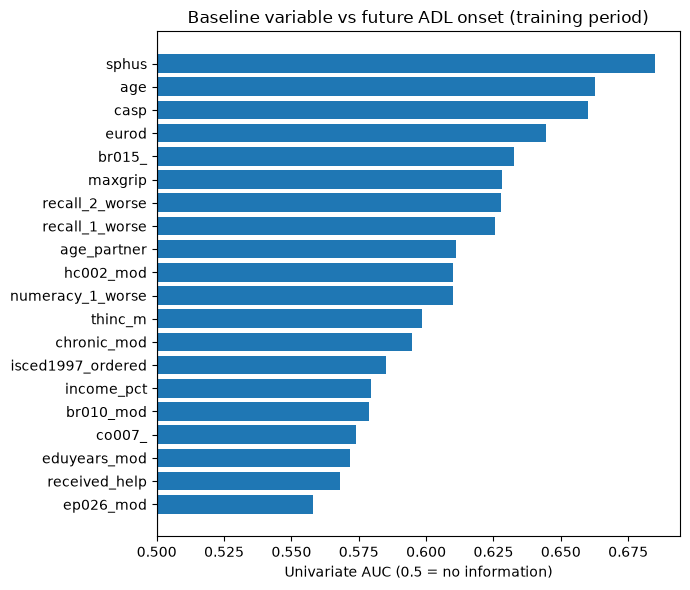

In [10]:
train_pairs = pairs[pairs["baseline_wave"].isin(DEV_BASE + VAL_BASE)]
from sklearn.metrics import roc_auc_score as _auc
rows = []
for v in candidate_variables:
    if v not in train_pairs.columns or v == "adla_clean":
        continue
    t = train_pairs[[v, "y"]].dropna()
    if len(t) < 200 or t[v].nunique() < 2 or t["y"].nunique() < 2:
        continue
    a = _auc(t["y"], t[v])
    rows.append({"Variable": v, "N": len(t), "Missing_%": round(train_pairs[v].isna().mean() * 100, 1),
                 "Spearman_rho": spearmanr(t[v], t["y"])[0], "Univariate_AUC": max(a, 1 - a),
                 "Direction": "higher -> more risk" if a >= .5 else "higher -> less risk"})
future_assoc = pd.DataFrame(rows).sort_values("Univariate_AUC", ascending=False).set_index("Variable")
future_assoc.round(3).to_csv(f"{OUT}/baseline_vs_future_ADL_association.csv")
print(f"Outcome: follow-up ADL >= {ADL_CUTOFF}; training-period pairs only")
print(future_assoc.round(3).head(30).to_string())
top = future_assoc.head(20)[::-1]
plt.figure(figsize=(7, 6)); plt.barh(top.index, top["Univariate_AUC"] - 0.5, left=0.5)
plt.axvline(.5, color="k"); plt.xlabel("Univariate AUC (0.5 = no information)")
plt.title("Baseline variable vs future ADL onset (training period)"); plt.tight_layout()
plt.savefig(f"{OUT}/baseline_vs_future_ADL_auc.png", dpi=200); plt.show()

**Result** Self-rated health (AUC = 0.685) and age (AUC = 0.662) showed the
strongest individual discrimination for future ADL decline. CASP,
depressive symptoms, physical activity, grip strength, and recall also
showed meaningful univariate associations.

Higher age, poorer self-rated health, higher depressive symptoms, and
less frequent activity were associated with greater future decline,
while higher grip strength and better cognitive performance were
associated with lower decline.

These findings were used as exploratory evidence rather than as the
sole basis for feature selection. Missingness, conceptual relevance,
redundancy, and multivariable model performance were also considered.

## Baseline Characteristics by Future ADL Outcome

We compare baseline characteristics between participants who did and did
not develop a new ADL limitation at the subsequent SHARE wave.

For each primary numerical predictor, we calculate the count, mean,
median, and standard deviation separately for:

- y = 0: no new ADL limitation
- y = 1: new ADL limitation

We also calculate point-biserial correlations between each baseline
variable and the binary future ADL outcome. This provides an additional
measure of the direction and strength of the association.

Positive correlations indicate that higher values of the predictor are
associated with greater future ADL decline, while negative correlations
indicate an association with lower future decline.

This analysis is descriptive and does not establish causality. It is
used to understand how baseline characteristics differ between the two
future-outcome groups before multivariable modeling.

In [11]:
from scipy.stats import pointbiserialr
prim = [v for v in ["age", "sphus", "chronic_mod", "maxgrip", "eurod", "bmi", "thinc_m", "log_income_eq", "recall_imm", "recall_del"] if v in pairs.columns]
desc = pairs.groupby("y")[prim].agg(["count", "mean", "median", "std"]).T.round(2)
desc.columns = ["no new ADL (y=0)", "new ADL (y=1)"]
print("Mean / median / SD of the baseline variables by future outcome\n", desc.to_string())
desc.to_csv(f"{OUT}/descriptives_by_outcome.csv")
pb_rows = []
for v in prim:
    t = pairs[[v, "y"]].dropna(); r_, p_ = pointbiserialr(t["y"], t[v])
    pb_rows.append({"variable": v, "N": len(t), "point-biserial r": round(r_, 3), "p-value": ("<1e-300" if p_ == 0 else f"{p_:.2e}")})
pb_tab = pd.DataFrame(pb_rows); print("\nPoint-biserial correlation with the future outcome\n", pb_tab.to_string(index=False))
pb_tab.to_csv(f"{OUT}/point_biserial_primary_variables.csv", index=False)

Mean / median / SD of the baseline variables by future outcome
                       no new ADL (y=0)  new ADL (y=1)
age           count          104067.00       11088.00
              mean               73.34          77.32
              median             72.30          77.10
              std                 6.04           7.15
sphus         count          104032.00       11077.00
              mean                3.12           3.77
              median              3.00           4.00
              std                 0.97           0.91
chronic_mod   count          103994.00       11076.00
              mean                1.34           1.80
              median              1.00           2.00
              std                 1.20           1.36
maxgrip       count           98246.00        9671.00
              mean               31.89          27.35
              median             30.00          26.00
              std                10.62          10.44
eurod         coun

**Result**:

Baseline Characteristics by Future ADL Outcome

Participants who subsequently developed a new ADL limitation showed
less favorable baseline health characteristics than those who remained
free of ADL limitation. Older age and poorer self-rated health were
positively associated with future ADL decline, while higher grip
strength and better recall performance were associated with lower
future decline.

The point-biserial associations were strongest for age (r = 0.188),
self-rated health (r = 0.193), grip strength (r = -0.121), recall
performance (r ≈ -0.138), and chronic disease burden (r = 0.111).
BMI showed almost no simple association with future decline (r ≈ 0.058),
while income showed a weak negative association (r ≈ -0.049).

These descriptive differences support the use of age, self-rated health,
physical function, cognitive performance, and chronic disease burden as
candidate predictors. However, these are unadjusted associations and
do not establish causality or determine the final multivariable feature
importance.

## Exploratory Data Visualizations

This section visualizes the main characteristics of the dataset and the
relationships identified during exploratory analysis.

The visualizations cover:

1. Sample structure across survey waves and countries.
2. Special missing-value codes in the raw data.
3. Raw versus cleaned distributions of selected variables.
4. ADL distribution among adults aged 65+ and the baseline ADL = 0 pool.
5. Follow-up retention, future ADL decline, and follow-up intervals.
6. Future ADL decline rates across important demographic and health groups.
7. Baseline feature distributions by future ADL outcome.
8. Missingness among candidate model features after cleaning.
9. Correlations among the primary numerical predictors.

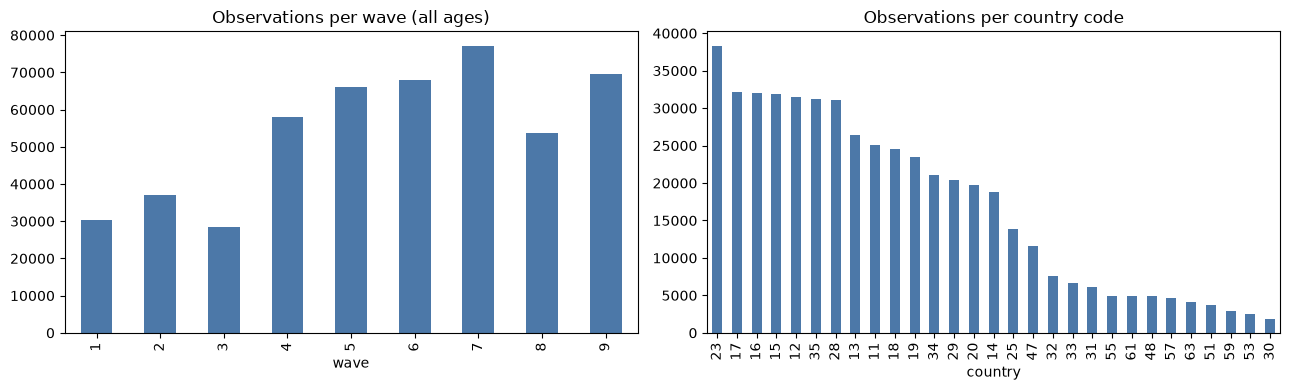

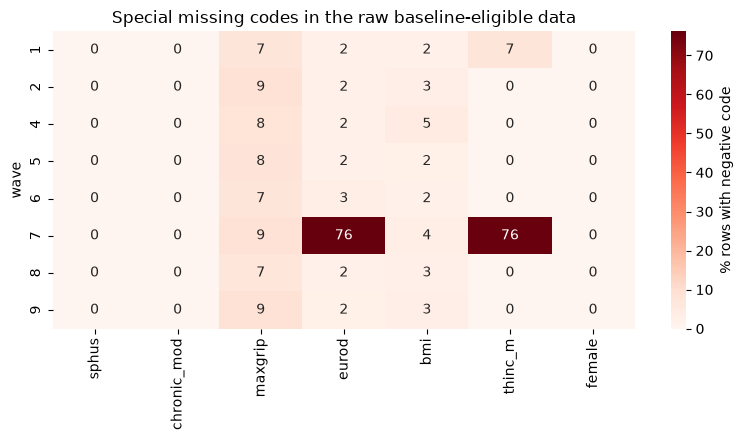

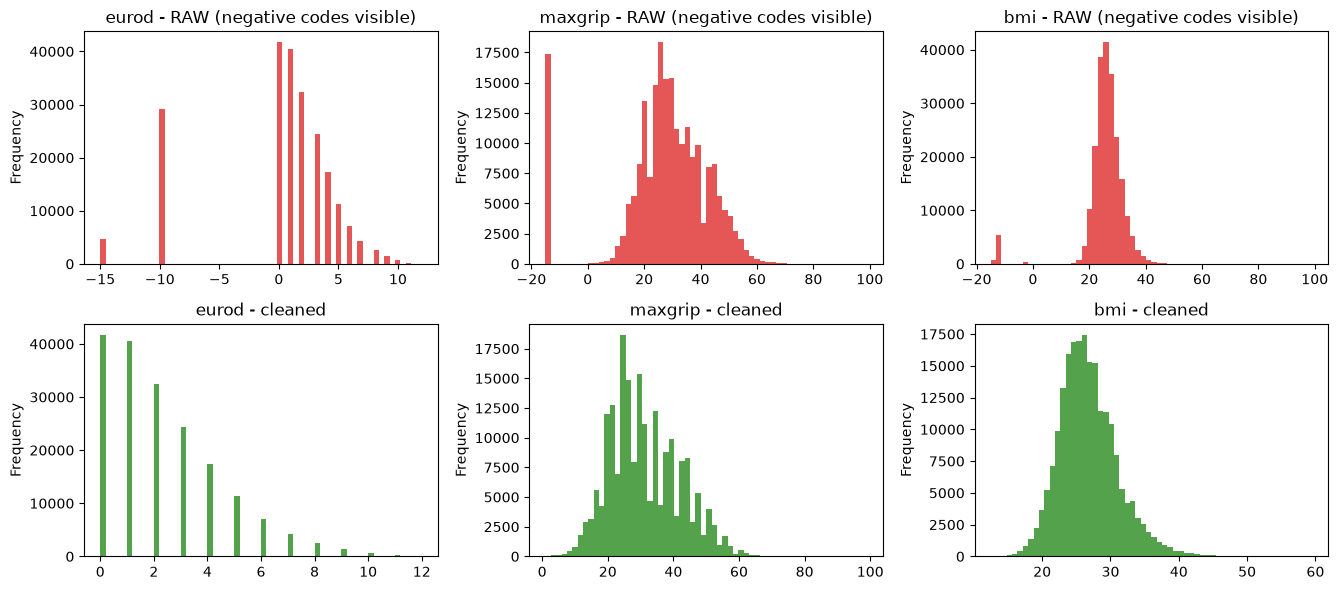

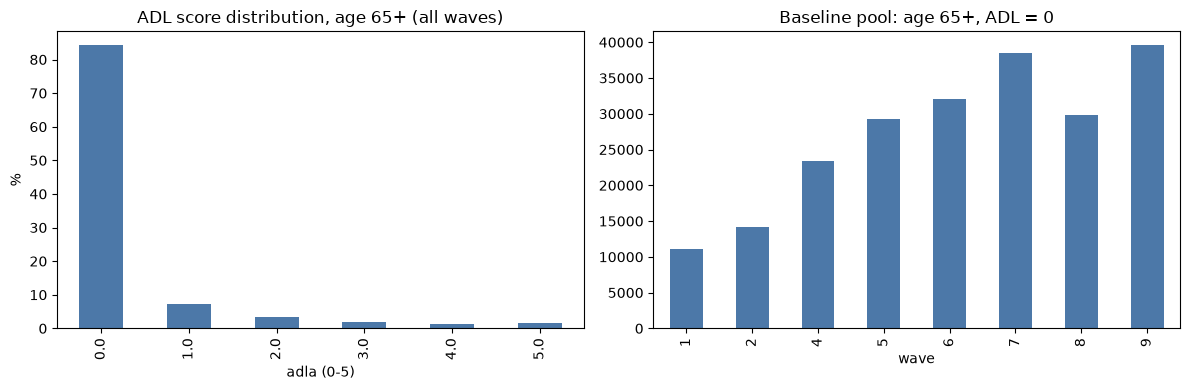

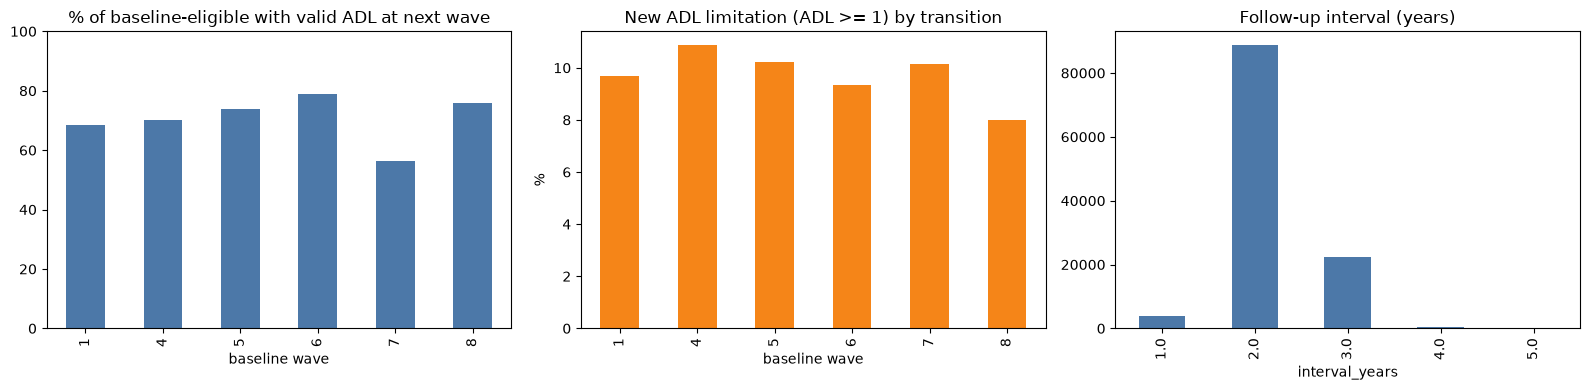

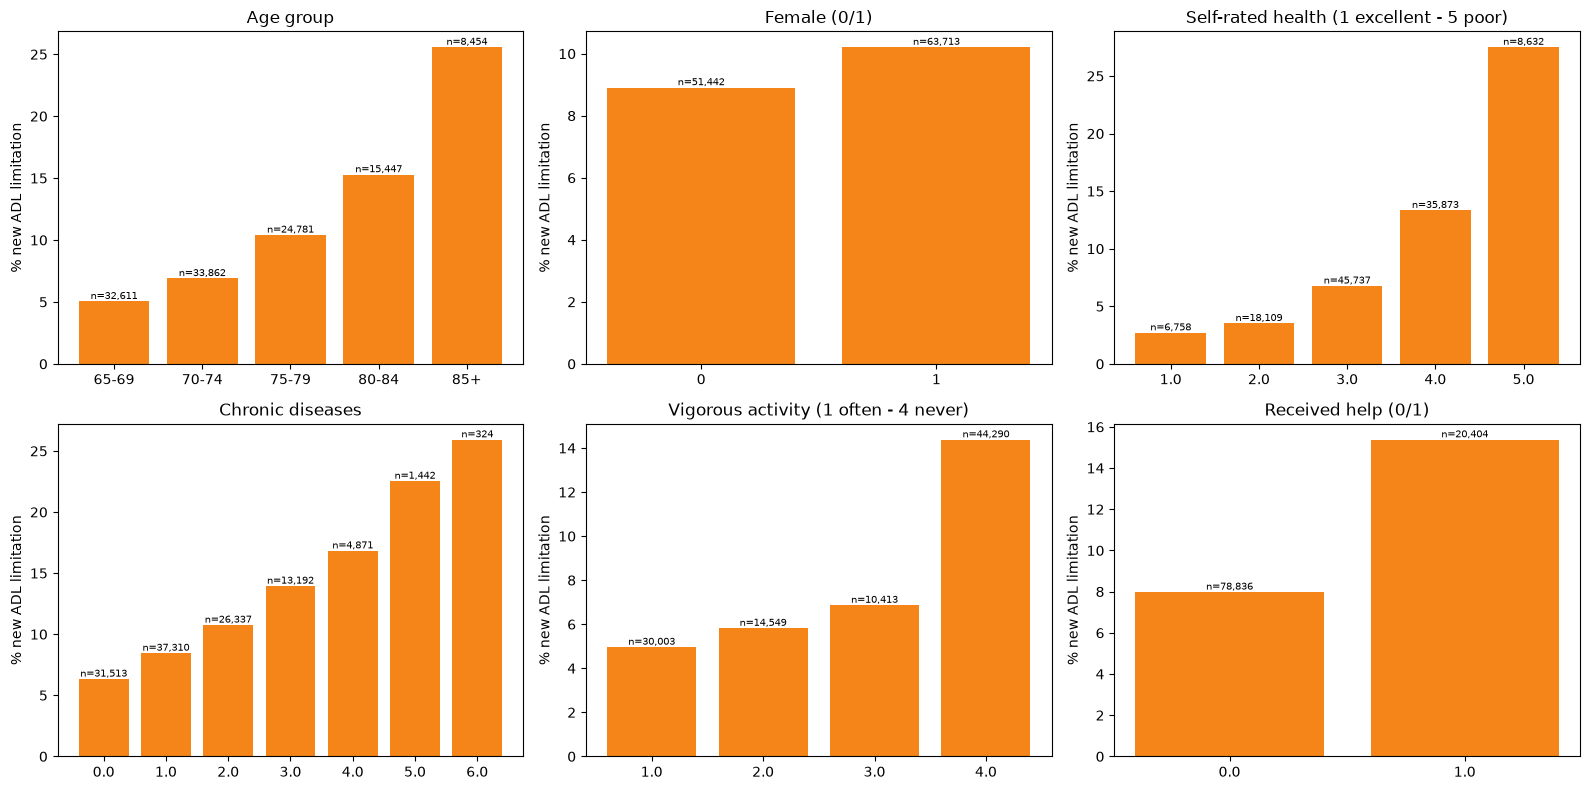

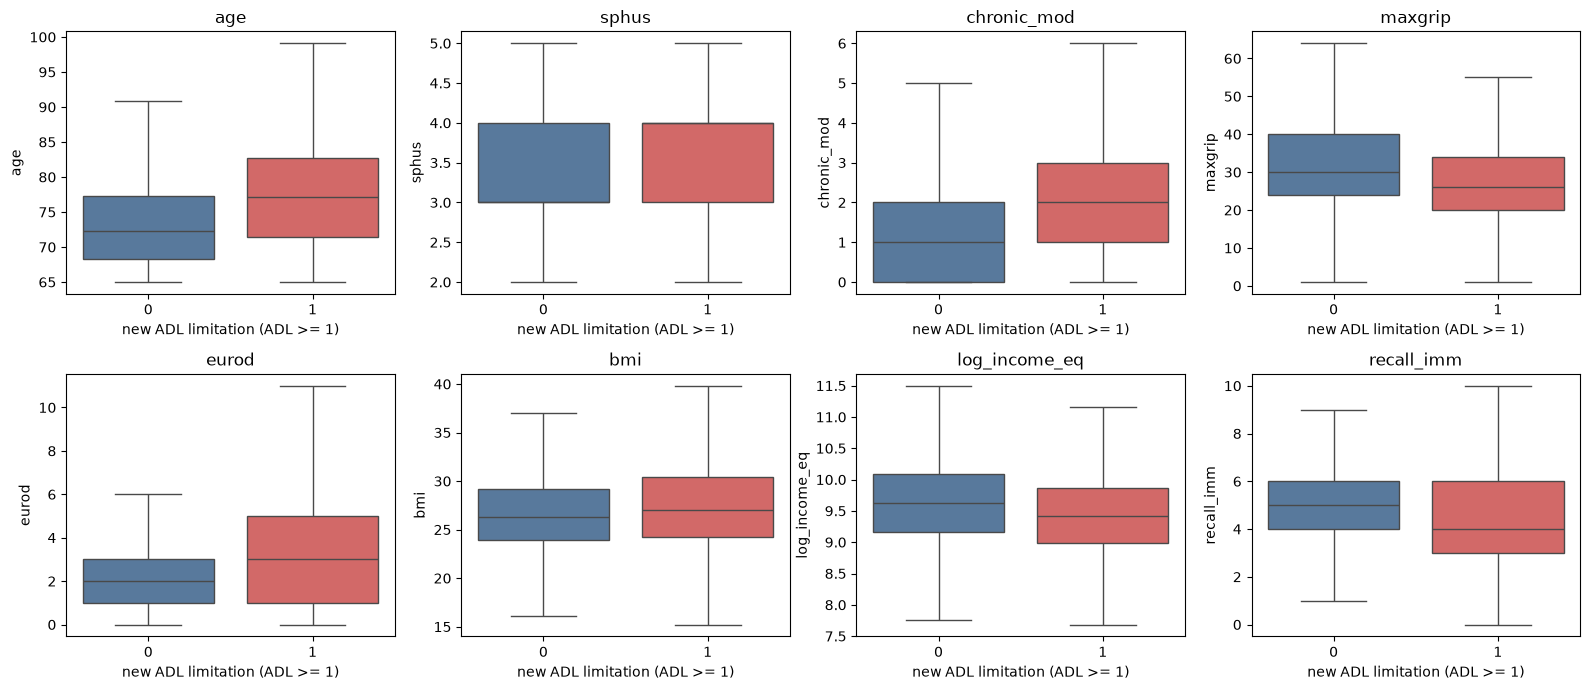

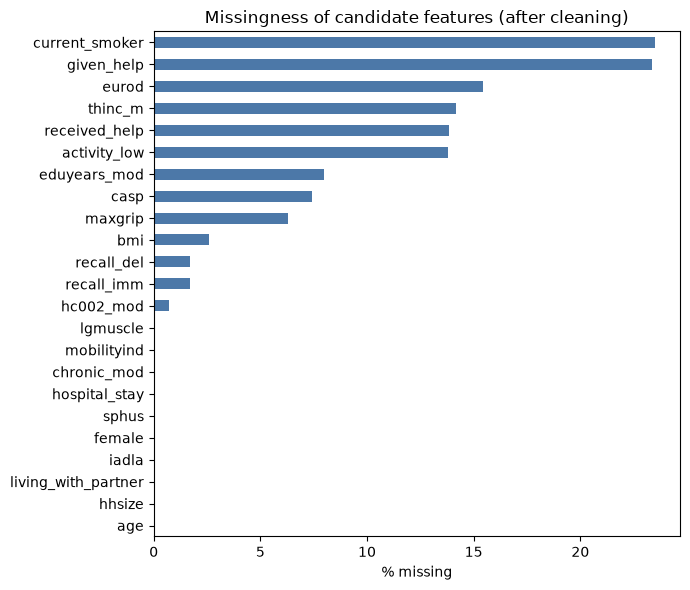

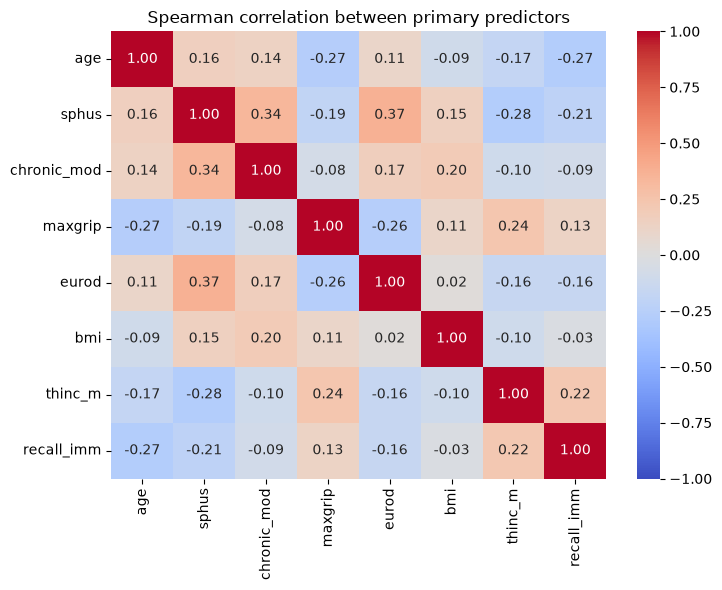

In [12]:
def savefig(name):
    """Save and display the current matplotlib figure.

    Args:
        name: Filename to use when saving the figure. The output
            directory and PNG extension are added automatically.

    Returns:
        None.
    """
    plt.tight_layout(); plt.savefig(f"{OUT}/{name}.png", dpi=200); plt.show()

# 1) Sample structure: observations per wave and per country (raw file, all ages)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
df_raw["wave"].value_counts().sort_index().plot.bar(ax=ax[0], color="#4C78A8"); ax[0].set(title="Observations per wave (all ages)", xlabel="wave")
df_raw["country"].value_counts().plot.bar(ax=ax[1], color="#4C78A8"); ax[1].set(title="Observations per country code", xlabel="country")
savefig("viz01_sample_structure")

# 2) Missing-code audit: % negative codes per wave and variable (eligible baseline rows, RAW data)
aud_vars = [v for v in ["sphus", "chronic_mod", "maxgrip", "eurod", "bmi", "thinc_m", "female"] if v in df_raw]
aud = (elig_raw.assign(**{v: (elig_raw[v] < 0) for v in aud_vars}).groupby("wave")[aud_vars].mean().mul(100))
plt.figure(figsize=(8, 4.5)); sns.heatmap(aud, annot=True, fmt=".0f", cmap="Reds", cbar_kws={"label": "% rows with negative code"})
plt.title("Special missing codes in the raw baseline-eligible data"); savefig("viz02_missing_codes_raw")

# 3) Raw vs cleaned distribution for variables with a known range
chk = [v for v in ["eurod", "maxgrip", "bmi"] if v in df_raw]
fig, ax = plt.subplots(2, len(chk), figsize=(4.5 * len(chk), 6))
for j, v in enumerate(chk):
    elig_raw[v].plot.hist(bins=60, ax=ax[0, j], color="#E45756"); ax[0, j].set_title(f"{v} - RAW (negative codes visible)")
    df.loc[elig_raw.index, v].plot.hist(bins=60, ax=ax[1, j], color="#54A24B"); ax[1, j].set_title(f"{v} - cleaned")
savefig("viz03_raw_vs_clean")

# 4) ADL at all waves (age 65+) and ADL=0 baseline pool per wave
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
(df_65["adla_clean"].value_counts(normalize=True).sort_index() * 100).plot.bar(ax=ax[0], color="#4C78A8")
ax[0].set(title="ADL score distribution, age 65+ (all waves)", xlabel="adla (0-5)", ylabel="%")
(df_65[df_65["adla_clean"] == 0].groupby("wave").size()).plot.bar(ax=ax[1], color="#4C78A8"); ax[1].set(title="Baseline pool: age 65+, ADL = 0", xlabel="wave")
savefig("viz04_adl_distribution")

# 5) Attrition and outcome by wave transition
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
att["retained_%"].plot.bar(ax=ax[0], color="#4C78A8"); ax[0].set(title="% of baseline-eligible with valid ADL at next wave", xlabel="baseline wave", ylim=(0, 100))
(pairs.groupby("baseline_wave")["y"].mean() * 100).plot.bar(ax=ax[1], color="#F58518"); ax[1].set(title=f"New ADL limitation (ADL >= {ADL_CUTOFF}) by transition", ylabel="%", xlabel="baseline wave")
pairs["interval_years"].value_counts().sort_index().plot.bar(ax=ax[2], color="#4C78A8"); ax[2].set(title="Follow-up interval (years)")
savefig("viz05_attrition_outcome_interval")

# 6) Outcome rate by age group, sex, self-rated health, activity, help received (with N)
pairs["age_group"] = pd.cut(pairs["age"], [64, 69, 74, 79, 84, np.inf], labels=["65-69", "70-74", "75-79", "80-84", "85+"])
groupings = [("age_group", "Age group"), ("female", "Female (0/1)"), ("sphus", "Self-rated health (1 excellent - 5 poor)"),
             ("chronic_mod", "Chronic diseases"), ("activity_low", "Vigorous activity (1 often - 4 never)"), ("received_help", "Received help (0/1)")]
groupings = [(c, t) for c, t in groupings if c in pairs.columns]
fig, ax = plt.subplots(2, 3, figsize=(16, 8)); ax = ax.ravel()
for a, (c, t) in zip(ax, groupings):
    g = pairs.groupby(c, observed=True)["y"].agg(["mean", "size"]); g = g[g["size"] >= 100]
    a.bar(g.index.astype(str), g["mean"] * 100, color="#F58518")
    for i, (m, n) in enumerate(zip(g["mean"], g["size"])): a.text(i, m * 100, f"n={n:,}", ha="center", va="bottom", fontsize=7)
    a.set(title=t, ylabel="% new ADL limitation")
savefig("viz06_outcome_by_group")

# 7) Baseline feature distributions by outcome
vf = [v for v in ["age", "sphus", "chronic_mod", "maxgrip", "eurod", "bmi", "log_income_eq", "recall_imm"] if v in pairs.columns]
fig, ax = plt.subplots(2, 4, figsize=(16, 7)); ax = ax.ravel()
for a, v in zip(ax, vf):
    sns.boxplot(data=pairs, x="y", y=v, ax=a, showfliers=False, palette=["#4C78A8", "#E45756"], hue="y", legend=False)
    a.set(title=v, xlabel=f"new ADL limitation (ADL >= {ADL_CUTOFF})")
savefig("viz07_features_by_outcome")

# 8) Missingness of candidate model features (prepared pairs)
feat_all = [c for c in dict.fromkeys(["age", "female", "sphus", "chronic_mod", "maxgrip", "eurod", "bmi", "thinc_m",
            "recall_imm", "casp", "recall_del", "activity_low", "received_help", "given_help", "current_smoker",
            "living_with_partner", "hhsize", "eduyears_mod", "hc002_mod", "hospital_stay", "mobilityind", "lgmuscle", "iadla"]) if c in pairs.columns]
pairs[feat_all].isna().mean().mul(100).sort_values().plot.barh(figsize=(7, 6), color="#4C78A8")
plt.xlabel("% missing"); plt.title("Missingness of candidate features (after cleaning)"); savefig("viz08_feature_missingness")

# 9) Predictor-to-predictor Spearman correlation (primary features)
pp = [v for v in ["age", "sphus", "chronic_mod", "maxgrip", "eurod", "bmi", "thinc_m", "recall_imm"] if v in pairs.columns]
plt.figure(figsize=(7.5, 6)); sns.heatmap(pairs[pp].corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Spearman correlation between primary predictors"); savefig("viz09_predictor_correlation")

**Result:** 

The exploratory visualizations confirmed several important characteristics
of the dataset. The raw-data plots showed the presence of special negative
codes and implausible values, while the cleaned distributions showed more
plausible ranges.

Among adults aged 65+, the baseline ADL distribution showed a substantial
group with ADL = 0, providing the population for the longitudinal prediction
analysis. Future ADL decline varied across age and health-related groups,
with higher observed decline among older participants and those with poorer
baseline health characteristics.

The feature-distribution plots showed differences between participants who
did and did not develop a new ADL limitation. Missingness plots were used to
identify variables that could reduce the available sample size, while the
predictor-correlation heatmap was used to assess potential redundancy among
the primary numerical predictors.

These visualizations supported the subsequent feature-selection, PCA, and
predictive-modeling stages.

## Defining Modeling Feature Sets and Data Splits

Before fitting the predictive models, we define several nested feature
sets with increasing levels of information.

The feature sets are designed to evaluate whether adding additional
health, socioeconomic, functional, and longitudinal information improves
prediction:

- **F_A:** Core demographic, general-health, chronic-disease, and physical-function variables.
- **F_B:** Core features plus mental health, BMI, income, and cognitive recall.
- **F_C:** F_B plus additional psychosocial, activity, social-help,
  household, education, healthcare-use, and country variables.
- **F_D:** F_C plus additional functional and mobility measures.
- **F_T:** F_D plus changes in selected variables from the previous
  regular wave to the baseline wave.

Only variables available in the prediction dataset are retained.

The data are then separated chronologically into development,
validation, and final test periods. 

The development period is used for
model development, the validation period is used for model-selection
decisions such as threshold selection, and the later waves are reserved
for final evaluation.

This temporal design reflects the longitudinal prediction objective and
helps prevent future information from influencing model development.

In [13]:
HC_VAR = "hc002_log" if HC002_MODE == "log" else "hc002_mod"
CAT_COLS = ["country"]
BIN_COLS = ["female", "current_smoker", "received_help", "given_help", "living_with_partner", "hospital_stay", "grip_low"]
F_A = ["age", "female", "sphus", "chronic_mod", "maxgrip"]
F_B = ["age", "female", "sphus", "chronic_mod", "maxgrip", "eurod", "bmi", "log_income_eq", "recall_imm"]
F_C = F_B + ["casp", "recall_del", "activity_low", "received_help", "given_help",
             "living_with_partner", "hhsize", "eduyears_mod", HC_VAR, "hospital_stay", "country"]
F_D = F_C + ["mobilityind", "lgmuscle", "iadlza"]      # iadla is a subset of iadlza (3 of its 5 items) -> only iadlza is kept
F_T = F_D + ["d_" + v for v in TREND_VARS]          # D + trend (change since the previous wave)
F_A, F_B, F_C, F_D, F_T = [[c for c in f if c in pairs.columns] for f in (F_A, F_B, F_C, F_D, F_T)]
print({k: len(v) for k, v in dict(A=F_A, B=F_B, C=F_C, D=F_D, T=F_T).items()})
print("Share of baseline rows with a previous-wave record:", round(pairs["prev_gap_years"].notna().mean() * 100, 1), "%")
print("\n% missing in pairs (extended sets):")
print((pairs[F_D].isna().mean() * 100).round(1).sort_values(ascending=False).head(15))

dev = pairs[pairs["baseline_wave"].isin(DEV_BASE)]
val = pairs[pairs["baseline_wave"].isin(VAL_BASE)]
trv = pairs[pairs["baseline_wave"].isin(DEV_BASE + VAL_BASE)]
test = pairs[pairs["baseline_wave"].isin(TEST_BASE)]
print(f"\ndev {len(dev):,} | val {len(val):,} | train(dev+val) {len(trv):,} | test {len(test):,}")
print("people in both train and test:", len(set(trv["mergeid"]) & set(test["mergeid"])),
      "| households in both:", len(set(trv["hh_key"]) & set(test["hh_key"])))

{'A': 5, 'B': 9, 'C': 20, 'D': 23, 'T': 31}
Share of baseline rows with a previous-wave record: 66.5 %

% missing in pairs (extended sets):
given_help       23.4
eurod            15.4
log_income_eq    14.2
activity_low     13.8
received_help    13.8
eduyears_mod      8.0
casp              7.4
maxgrip           6.3
bmi               2.6
recall_del        1.7
recall_imm        1.7
hc002_mod         0.7
mobilityind       0.1
chronic_mod       0.1
lgmuscle          0.1
dtype: float64

dev 45,574 | val 25,238 | train(dev+val) 70,812 | test 44,343
people in both train and test: 15395 | households in both: 12537


**Result:** 

The modeling stage uses nested feature sets to examine whether adding
additional domains of information improves predictive performance.

The data are divided chronologically into development, validation, and
test periods. The development period contains earlier wave transitions,
the validation period contains Wave 6→7, and the final test period
contains the later Wave 7→8 and Wave 8→9 transitions.

This structure preserves the temporal nature of the prediction problem
and ensures that the final test period represents future observations
that were not used for model development or threshold selection.

## Evaluating Functional Indices as Candidate Predictors

Before including additional functional measures in the predictive models,
we evaluate their individual relationship with future ADL decline.

The candidate functional variables are:

- `mobilityind`
- `lgmuscle`
- `iadla`
- `iadlza`

For each variable, we examine:

- percentage of missing observations
- univariate ROC-AUC for future ADL decline
- future ADL decline rate across increasing levels of the functional
  measure
- number of observations within each level.

For the group-level analysis, values above 3 are combined into a 3+
category to make the decline rates easier to compare while retaining
the original information for the univariate AUC calculation.

This analysis helps determine whether the additional functional indices
provide useful predictive information beyond the primary candidate
features.

In [14]:
rows = []
for v in [c for c in ["mobilityind", "lgmuscle", "iadla", "iadlza"] if c in dev.columns]:
    t = dev[[v, "y"]].dropna()
    a = roc_auc_score(t["y"], t[v])
    grp = t.groupby(t[v].clip(upper=3))["y"].agg(["size", "mean"]).assign(mean=lambda d: (d["mean"] * 100).round(1))
    rows.append({"variable": v, "missing_%": round(dev[v].isna().mean() * 100, 1), "univariate_AUC": round(max(a, 1 - a), 3),
                 "new-ADL rate by value (0 / 1 / 2 / 3+), %": " / ".join(str(x) for x in grp["mean"].tolist()),
                 "n by value": " / ".join(str(int(x)) for x in grp["size"].tolist())})
func_ev = pd.DataFrame(rows); print(func_ev.to_string(index=False))
func_ev.to_csv(f"{OUT}/functional_indices_evidence.csv", index=False)

   variable  missing_%  univariate_AUC new-ADL rate by value (0 / 1 / 2 / 3+), %                  n by value
mobilityind        0.0           0.668                  6.3 / 14.7 / 24.0 / 34.8  31026 / 9422 / 3576 / 1548
   lgmuscle        0.0           0.682                  5.6 / 12.1 / 20.1 / 28.9 26860 / 10138 / 5367 / 3207
      iadla        0.0           0.539                  9.6 / 31.1 / 44.6 / 72.4     44237 / 1084 / 195 / 58
     iadlza        0.0           0.571                  9.0 / 29.4 / 44.0 / 54.5    43169 / 1666 / 473 / 266


**Result:** 

The functional indices were evaluated individually for their ability to
distinguish participants who subsequently developed a new ADL
limitation. Variables were compared using univariate AUC, missingness,
and future ADL decline rates across their observed levels.

The results were used as supporting evidence for feature-set design.
Variables showing stronger discrimination and consistent increases in
future ADL decline across higher levels were considered more promising
for inclusion in extended models, while variables with substantial
missingness or weak discrimination were treated more cautiously.

## Data-Driven Feature Ranking

We perform an additional feature-screening analysis using only the
development period.

Candidate variables are ranked according to their univariate ability
to distinguish participants who subsequently develop a new ADL
limitation from those who do not.

Before ranking, we apply the following criteria:

- Exclude variables that duplicate information already represented by
  another feature.
- Exclude variables with more than 40% missingness.
- Require at least 500 complete observations.
- Require variation in both the predictor and the outcome.
- Rank variables by univariate ROC-AUC, using the direction-independent
  value max(AUC, 1 - AUC).

The top 12 eligible variables are selected to form Feature Set E.

This analysis is performed only on the development period so that the
final validation and test periods do not influence feature selection.

Feature Set E is therefore a data-driven candidate set rather than the
final model specification.

In [15]:
TOPK_E, MAX_MISSING_E = 12, 40
DUP_EXCL = {"br015_", "recall_1_worse", "recall_2_worse", "age_partner", "thinc_m", "isced1997_ordered", "hc002_mod_dummy"}
pool = [c for c in candidate_variables if c not in DUP_EXCL and c in dev.columns]
pool += [c for c in ["log_income_eq", "recall_imm", "recall_del", "activity_low"] if c in dev.columns and c not in pool]
rank = []
for v in pool:
    t = dev[[v, "y"]].dropna()
    miss = dev[v].isna().mean() * 100
    if miss > MAX_MISSING_E or len(t) < 500 or t[v].nunique() < 2 or t["y"].nunique() < 2:
        continue
    a = roc_auc_score(t["y"], t[v])
    rank.append({"variable": v, "missing_%": round(miss, 1), "univariate_AUC": max(a, 1 - a)})
rank = pd.DataFrame(rank).sort_values("univariate_AUC", ascending=False).reset_index(drop=True)
F_E = rank["variable"].head(TOPK_E).tolist()
print(rank.head(20).round(3).to_string(index=False))
print("\nFeature set E (top", TOPK_E, "):", F_E)
rank.round(4).to_csv(f"{OUT}/feature_ranking_dev_period.csv", index=False)

           variable  missing_%  univariate_AUC
              sphus        0.1           0.683
               casp       10.7           0.666
                age        0.0           0.660
              eurod        1.8           0.648
            maxgrip        6.5           0.630
         recall_del        1.5           0.628
       activity_low        0.2           0.627
         recall_imm        1.4           0.623
          hc002_mod        0.7           0.609
        chronic_mod        0.1           0.596
      log_income_eq        1.2           0.594
             co007_        1.7           0.582
          br010_mod        0.2           0.579
         income_pct        0.0           0.578
       eduyears_mod        5.4           0.569
      received_help        0.2           0.566
living_with_partner        0.0           0.556
         given_help       24.3           0.546
                bmi        2.8           0.544
      hospital_stay        0.1           0.540

Feature set 

**Result:** 

The development-period feature ranking identified self-rated health
(`sphus`) as the strongest individual predictor of future ADL decline
(AUC = 0.683), followed by CASP (0.666), age (0.660), depressive
symptoms (`eurod`, 0.648), and grip strength (`maxgrip`, 0.630).

Cognitive recall, physical activity, healthcare utilization, and
chronic disease burden also showed modest individual predictive
ability. All 12 variables selected for Feature Set E had less than 40%
missingness and at least 500 complete observations.

Feature Set E therefore consisted of `sphus`, `casp`, `age`, `eurod`,
`maxgrip`, `recall_del`, `activity_low`, `recall_imm`, `hc002_mod`,
`chronic_mod`, `log_income_eq`, and `co007_`.

This ranking was used as a data-driven feature-screening approach.
The final feature set was not determined by univariate AUC alone;
conceptual relevance, missingness, redundancy, and multivariable
predictive performance were also considered.

## Defining Preprocessing and Predictive Models

We define reusable model-building functions so that the same
preprocessing and modeling logic can be applied consistently across
different feature sets.

The models considered include:

- Logistic Regression
- PCA + Logistic Regression
- Random Forest
- Elastic-Net Logistic Regression

The preprocessing depends on the variable type. Numerical variables
are median-imputed and standardized for linear models, binary variables
use most-frequent imputation, and categorical variables are encoded
appropriately.

The models are implemented as scikit-learn pipelines so that
preprocessing is fitted only on the training data and then applied to
validation and test data. This helps prevent data leakage.

Different feature sets can therefore be evaluated using the same
model-building framework.

In [16]:
def make_prep(features, spline_cols=("age", "bmi"), add_ind=False):
    """Create a preprocessing pipeline for the selected features.

    Numerical variables are median-imputed and standardized, selected
    variables can be transformed using spline basis functions, binary
    variables are imputed using the most frequent value, and categorical
    variables are one-hot encoded.

    Args:
        features: List of predictor variable names.
        spline_cols: Variables to transform using spline basis functions.
        add_ind: If True, add missingness indicators for imputed
            numerical and binary variables.

    Returns:
        A ColumnTransformer containing the preprocessing steps for the
        selected features.
    """
    cat = [c for c in features if c in CAT_COLS]
    binc = [c for c in features if c in BIN_COLS]
    spl = [c for c in features if c in spline_cols]
    num = [c for c in features if c not in cat + binc + spl]
    tr = []
    if num:
        tr.append(("num", Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=add_ind)), ("sc", StandardScaler())]), num))
    if spl:
        tr.append(("spl", Pipeline([("imp", SimpleImputer(strategy="median")),
                                    ("sp", SplineTransformer(n_knots=5, degree=3, include_bias=False)),
                                    ("sc", StandardScaler())]), spl))
    if binc:
        tr.append(("bin", SimpleImputer(strategy="most_frequent", add_indicator=add_ind), binc))
    if cat:
        tr.append(("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=50), cat))
    return ColumnTransformer(tr)


def lr(features, C=1.0, class_weight=None, splines=("age", "bmi"), add_ind=False):
    """Create a Logistic Regression pipeline.

    Args:
        features: List of predictor variable names.
        C: Inverse regularization strength (smaller = stronger shrinkage).
        class_weight: None, or "balanced" to up-weight the rare outcome class.
        splines: Numerical variables modelled with splines.
        add_ind: If True, add missing-value indicator columns.

    Returns:
        A scikit-learn Pipeline containing preprocessing and Logistic Regression.
    """
    
    return Pipeline([("prep", make_prep(features, splines, add_ind)),
                     ("clf", LogisticRegression(C=C, max_iter=3000, class_weight=class_weight))])


def pca_lr(features, k, C=1.0):
    """Create a PCA + Logistic Regression pipeline.

    Numerical predictors are median-imputed, standardized and reduced to
    `k` principal components. Binary variables and the categorical country
    variable stay outside the PCA (binary: most-frequent imputation,
    country: one-hot encoding), as in the other models.

    Args:
        features: List of predictor variable names.
        k: Number of principal components kept from the numerical predictors.
        C: Inverse regularization strength of the Logistic Regression.

    Returns:
        A scikit-learn Pipeline containing preprocessing, PCA and Logistic Regression.
    """
    num = [c for c in features if c not in CAT_COLS + BIN_COLS]     # numerical predictors -> PCA
    binc = [c for c in features if c in BIN_COLS]                    # binary predictors -> outside the PCA
    cat = [c for c in features if c in CAT_COLS]                     # country -> outside the PCA
    tr = [("pca", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler()), ("pca", PCA(n_components=k))]), num),
          ("bin", SimpleImputer(strategy="most_frequent"), binc)]
    if cat:                                                          # country (one-hot) is kept outside the PCA, as in the other models
        tr.append(("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=50), cat))
    return Pipeline([("prep", ColumnTransformer(tr)), ("clf", LogisticRegression(C=C, max_iter=3000))])

    
def rf(features, leaf=50, max_features="sqrt"):
    """Create a Random Forest classification pipeline.

    Numerical predictors are median-imputed and categorical variables
    are ordinal-encoded before fitting the Random Forest.

    Args:
        features: List of predictor variable names.
        leaf: Minimum number of samples required in a leaf node.
        max_features: Number of features considered when splitting a tree.

    Returns:
        A scikit-learn Pipeline containing preprocessing and Random Forest.
    """
    num = [c for c in features if c not in CAT_COLS]
    cat = [c for c in features if c in CAT_COLS]
    tr = [("num", SimpleImputer(strategy="median", add_indicator=False), num)]
    if cat:
        tr.append(("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), cat))
    return Pipeline([("prep", ColumnTransformer(tr)),
                     ("clf", RandomForestClassifier(n_estimators=150 if FAST else 400, min_samples_leaf=leaf,
                                                    max_features=max_features, n_jobs=-1, random_state=RANDOM_STATE))])


from sklearn import __version__ as _skv
_SK_NEW = tuple(int(x) for x in _skv.split(".")[:2]) >= (1, 8)
def enet(features, C, l1_ratio):
    """Create an Elastic-Net Logistic Regression pipeline.

    Elastic-Net regularization combines L1 and L2 penalties. An
    l1_ratio of 1 corresponds to L1 regularization, which can shrink
    coefficients of less useful variables to zero.

    Args:
        features: List of predictor variable names.
        C: Inverse regularization strength.
        l1_ratio: Balance between L1 and L2 regularization.

    Returns:
        A scikit-learn Pipeline containing preprocessing and
        Elastic-Net Logistic Regression.
    """
    kw = dict(C=C, l1_ratio=l1_ratio, solver="saga", max_iter=500, tol=1e-3)
    if not _SK_NEW:
        kw["penalty"] = "elasticnet"
    return Pipeline([("prep", make_prep(features)), ("clf", LogisticRegression(**kw))])

**Result:**

Reusable preprocessing and modeling pipelines were created for Logistic
Regression, PCA + Logistic Regression, Random Forest, and Elastic-Net
Logistic Regression.

The pipelines ensure that preprocessing is performed consistently within
each model and that transformations such as imputation, scaling, encoding,
and PCA are fitted only on the training data.

These model definitions provide a common framework for comparing different
algorithms and feature sets while minimizing the risk of data leakage.

## Model Training, Validation, and Evaluation Framework

This section defines the framework used to train, compare, and evaluate
the predictive models.

Models are first trained on the development period and evaluated on the
validation period using ROC-AUC. 

The best-performing candidate model
within each model family is selected based on validation ROC-AUC.

After model selection, the classification threshold is chosen using the
validation predictions by maximizing the F1-score.

The selected model is then refit using the combined development and
validation data. Final predicted probabilities are generated on the
held-out test period, which contains later SHARE wave transitions.

This procedure separates model development, model selection, threshold
selection, and final evaluation to reduce the risk of information
leakage from the final test set.

The framework also supports sample weights.

In [17]:
def fit_model(m, X, y, w=None):
    """Fit a model with optional sample weights.

    Args:
        m: Unfitted estimator or scikit-learn Pipeline.
        X: Predictor variables used for model fitting.
        y: Target variable.
        w: Optional sample weights.

    Returns:
        The fitted estimator.
    """
    if w is None:
        return m.fit(X, y)
    if isinstance(m, Pipeline):
        return m.fit(X, y, **{m.steps[-1][0] + "__sample_weight": w})
    return m.fit(X, y, sample_weight=w)


def best_f1_threshold(y, p):
    """Find the probability threshold that maximizes F1-score.

    Args:
        y: Observed binary outcome values.
        p: Predicted probabilities for the positive class.

    Returns:
        The probability threshold producing the highest F1-score.
    """
    pr, rc, th = precision_recall_curve(y, p)
    f1 = 2 * pr[:-1] * rc[:-1] / np.clip(pr[:-1] + rc[:-1], 1e-12, None)
    return float(th[np.nanargmax(f1)])


def topk(y, p, frac):
    """Evaluate precision and recall among the highest-risk predictions.

    Args:
        y: Observed binary outcome values.
        p: Predicted probabilities for the positive class.
        frac: Fraction of observations selected as the highest-risk group.

    Returns:
        A tuple containing precision among selected observations,
        recall among all positive cases, and lift relative to the
        overall outcome prevalence.
    """
    y = np.asarray(y); n = max(1, int(frac * len(y)))
    idx = np.argsort(-p)[:n]
    prec = y[idx].mean()
    return prec, y[idx].sum() / y.sum(), prec / y.mean()


RESULTS = {}


def run_model(name, feats, candidates, ycol="y", wcol=None):
    """Train, select, and evaluate candidate models for a feature set.

    Candidate models are trained on the development period and compared
    using validation ROC-AUC. The best candidate is selected based on
    validation performance. Its F1-maximizing probability threshold is
    then determined from the validation predictions.

    The selected model is refit using the combined development and
    validation data and evaluated on the held-out test period.

    Args:
        name: Name used to identify the model or feature-set experiment.
        feats: List of predictor variable names.
        candidates: List of tuples containing a model label and a
            callable that returns an unfitted estimator.
        ycol: Name of the target column.
        wcol: Optional name of the sample-weight column.

    Returns:
        None. Results are stored in the global RESULTS dictionary and
        a summary is printed.
    """
    t0 = time.time()
    Xd, yd, Xv, yv = dev[feats], dev[ycol], val[feats], val[ycol]
    wd = dev[wcol].values if wcol else None
    best = None
    for label, build in candidates:
        m = fit_model(build(), Xd, yd, wd)
        pv = m.predict_proba(Xv)[:, 1]
        auc = roc_auc_score(yv, pv)
        if best is None or auc > best["val_auc"]:
            best = dict(label=label, build=build, val_auc=auc, p_val=pv)
    thr = best_f1_threshold(yv, best["p_val"])
    m = fit_model(best["build"](), trv[feats], trv[ycol], trv[wcol].values if wcol else None)
    pt = m.predict_proba(test[feats])[:, 1]
    RESULTS[name] = dict(feats=feats, label=best["label"], build=best["build"], val_auc=best["val_auc"],
                         p_val=best["p_val"], p_test=pt, thr=thr, model=m)
    print(f"{name:34s} best={best['label']:<22s} val AUC {best['val_auc']:.4f} | test AUC {roc_auc_score(test[ycol], pt):.4f}  ({time.time()-t0:.0f}s)")



**Result:**

A reproducible evaluation framework was established for comparing
candidate models using the same temporal development, validation, and
test structure.

Models are ranked using validation ROC-AUC, the classification
threshold is selected using validation F1-score, and the selected model
is then refit using the combined development and validation data before
being evaluated on the held-out future-wave test set.

This ensures that the final test period is not used to select the model
or classification threshold.

## Model Comparison and Feature-Set Experiments

We evaluate multiple predictive models and feature sets using the
development, validation, and final test structure defined previously.

For each model family, candidate hyperparameters are evaluated on the
validation period using ROC-AUC. The best-performing configuration is
then selected without using the final test data.

The selected model is refit using the combined development and
validation observations, and its predictions are evaluated on the
held-out future-wave test set.

The experiments compare:

- Logistic Regression using different feature sets;
- PCA + Logistic Regression;
- Random Forest;
- Elastic-Net Logistic Regression;
- models using additional functional variables;
- models using previous-wave trend variables;
- data-driven top-K feature sets.

This allows us to determine whether increasing model complexity,
adding additional variables, using PCA, or incorporating longitudinal
trends improves prediction of future ADL decline.

In [18]:
Cs = [0.1, 1.0] if FAST else [0.03, 0.1, 0.3, 1.0, 3.0]
rf_grid = [(f"leaf={l},mf={mf}", (lambda l=l, mf=mf: rf(F_B, leaf=l, max_features=mf))) for l in ([50] if FAST else [20, 50, 100]) for mf in (["sqrt"] if FAST else ["sqrt", 0.5])]

# reference points
run_model("0 Age only (spline LR)",        ["age"],  [("C=1", lambda: lr(["age"]))])
run_model("1 LR basic (A)",                F_A,      [(f"C={c}", (lambda c=c: lr(F_A, C=c))) for c in Cs])
run_model("2 LR balanced (B) [old design]", F_B,     [("C=1,balanced", lambda: lr(F_B, class_weight="balanced"))])
run_model("3 LR (B)",                      F_B,      [(f"C={c}", (lambda c=c: lr(F_B, C=c))) for c in Cs])

# PCA model: choose number of components on validation
p_num = len([c for c in F_B if c not in CAT_COLS + BIN_COLS])
run_model("4 PCA + LR (B)",                F_B,      [(f"k={k}", (lambda k=k: pca_lr(F_B, k))) for k in range(2, p_num + 1)])

run_model("5 Random forest tuned (B)",     F_B,      rf_grid)
run_model("6 LR extended (C)",             F_C,      [(f"C={c}", (lambda c=c: lr(F_C, C=c))) for c in Cs])
run_model("10 LR + functional (D)",        F_D,      [(f"C={c}", (lambda c=c: lr(F_D, C=c))) for c in Cs])

# trend features (change since previous wave)
run_model("13 LR + trend (D+T)",           F_T,      [(f"C={c}", (lambda c=c: lr(F_T, C=c))) for c in Cs])
# variables chosen by correlation with FUTURE ADL onset (dev period only)
run_model("15 LR top-K correlated (E)",    F_E,      [(f"C={c}", (lambda c=c: lr(F_E, C=c))) for c in Cs])
# elastic net: the model picks variables itself
en_grid = lambda f: [(f"C={c},l1={l}", (lambda c=c, l=l: enet(f, c, l))) for c in ([0.03] if FAST else [0.003, 0.01, 0.03, 0.1]) for l in ([0.5, 1.0] if FAST else [0.5, 1.0])]
run_model("17 Elastic-net LR (D)",         F_D,      en_grid(F_D))
run_model("18 Elastic-net LR (D+T)",       F_T,      en_grid(F_T))

# PCA on the larger feature sets (number of components chosen on the validation period; binary variables and country stay outside the PCA)
def _pca_grid(fs):
    """Build the candidate list of PCA + Logistic Regression models for one feature set.

    Args:
        fs: List of predictor variable names.

    Returns:
        List of (label, builder) pairs, one per number of components k = 2 ... number of
        numerical predictors (every third k in the fast run); builder() returns an unfitted pipeline.
    """
    pn = len([c for c in fs if c not in CAT_COLS + BIN_COLS])      # number of numerical predictors = maximum k
    return [(f"k={k}", (lambda k=k, fs=fs: pca_lr(fs, k))) for k in (range(2, pn + 1, 3) if FAST else range(2, pn + 1))]
run_model("21 PCA + LR (C)",           F_C,      _pca_grid(F_C))
run_model("22 PCA + LR (D)",           F_D,      _pca_grid(F_D))
run_model("23 PCA + LR (D+T)",         F_T,      _pca_grid(F_T))

# which variables did the elastic net keep? compare with the correlation-selected set E
for nm in ["17 Elastic-net LR (D)", "18 Elastic-net LR (D+T)"]:
    mm = RESULTS[nm]["model"]
    nms = [x.split("__", 1)[1] for x in mm.named_steps["prep"].get_feature_names_out()]
    co = pd.Series(mm.named_steps["clf"].coef_[0], index=nms)
    kept = co[co.abs() > 1e-6]
    print(f"\n{nm}: best {RESULTS[nm]['label']} | kept {len(kept)} of {len(co)} columns, set to zero: {sorted(co.index[co.abs() <= 1e-6])[:15]}")
    print(kept.reindex(kept.abs().sort_values(ascending=False).index).head(15).round(3).to_string())

def _base(c):
    """Map a transformed column name back to its original variable.

    Args:
        c: Column name after preprocessing, e.g. "age_sp_2" (spline term) or "country_12" (one-hot level).

    Returns:
        The original variable name, e.g. "age" or "country".
    """
    return c.split("_sp_")[0] if "_sp_" in c else ("country" if c.startswith("country") else c)
for nm in ["17 Elastic-net LR (D)", "18 Elastic-net LR (D+T)"]:     # separately for each elastic-net model (correct label)
    _co = pd.Series(RESULTS[nm]["model"].named_steps["clf"].coef_[0],
                    index=[x.split("__", 1)[1] for x in RESULTS[nm]["model"].named_steps["prep"].get_feature_names_out()])
    print(f"Variables of set E kept by {nm}:", sorted(set(F_E) & {_base(c) for c in _co.index[_co.abs() > 1e-6]}))

0 Age only (spline LR)             best=C=1                    val AUC 0.6692 | test AUC 0.6662  (0s)
1 LR basic (A)                     best=C=3.0                  val AUC 0.7509 | test AUC 0.7386  (0s)
2 LR balanced (B) [old design]     best=C=1,balanced           val AUC 0.7627 | test AUC 0.7504  (0s)
3 LR (B)                           best=C=3.0                  val AUC 0.7632 | test AUC 0.7504  (0s)
4 PCA + LR (B)                     best=k=8                    val AUC 0.7618 | test AUC 0.7485  (0s)
5 Random forest tuned (B)          best=leaf=50,mf=sqrt        val AUC 0.7579 | test AUC 0.7513  (14s)
6 LR extended (C)                  best=C=0.3                  val AUC 0.7821 | test AUC 0.7630  (1s)
10 LR + functional (D)             best=C=0.1                  val AUC 0.7992 | test AUC 0.7837  (1s)
13 LR + trend (D+T)                best=C=0.1                  val AUC 0.8044 | test AUC 0.7898  (1s)
15 LR top-K correlated (E)         best=C=3.0                  val AUC 0.7635 | t

**Result:** 

Model Comparison Results

The expanded model comparison showed that adding functional measures
and previous-wave changes substantially improved prediction of future
ADL decline compared with the basic feature sets.

The strongest test-set discrimination was achieved by the logistic
regressions with trend features: LR (D+T) and elastic-net LR (D+T) both
reached ROC-AUC = 0.790. Logistic Regression with functional features
achieved ROC-AUC = 0.784 (elastic net with the same features 0.784).

The basic Logistic Regression model (B) achieved a test ROC-AUC of
0.750, while PCA + Logistic Regression achieved 0.749 and Random
Forest achieved 0.751. Thus, neither PCA nor the more flexible random
forest improved prediction, whereas adding functional and longitudinal
trend information produced a substantial improvement.

The trend-based logistic regressions also achieved the highest PR-AUC (0.306). With a test
prevalence of 9.05%, this is substantially above the random-model PR-AUC baseline of 0.0905.

At the validation-selected threshold, Logistic Regression with trend
features achieved the highest F1-score (0.365, recall 0.460), followed by
elastic-net LR (D+T) (0.360) and LR with functional features (0.353).

Overall, incorporating changes in health and functional characteristics
between the previous wave and baseline appears to provide additional
predictive information beyond baseline characteristics alone.


**PCA + Logistic Regression on the larger feature sets**

PCA was also tested on the extended sets. The number of components was chosen on the validation period, and binary variables and country stay outside the PCA. PCA does not improve prediction for any set: test ROC-AUC 0.762 for set C (best k = 12 of 14 numeric variables; LR without PCA 0.763), 0.782 for set D (k = 16 of 17; LR 0.784) and 0.789 for set D+T (k = 24 of 25; LR 0.790). In every case the best number of components is almost the number of variables, i.e. there is practically no compression, and the test AUC is 0.001–0.002 lower than without PCA.

## Final Model Evaluation on the Held-Out Test Set

The final models are evaluated on the held-out future-wave test set.

Because observations may be clustered within households, bootstrap
confidence intervals for ROC-AUC are calculated by resampling households
rather than individual observations. This preserves the household
clustering structure during uncertainty estimation.

The evaluation includes:

- ROC-AUC and its 95% bootstrap confidence interval;
- difference in ROC-AUC relative to the reference Logistic Regression
  model;
- PR-AUC, which is particularly informative for the imbalanced ADL
  outcome;
- Brier score to assess probability calibration;
- precision, recall, and F1-score at the threshold selected using the
  validation data;
- precision, recall, and lift among the highest-risk 20% of participants.

The final test set is not used to select models or thresholds. It is
used only to estimate final out-of-sample performance.

In [19]:
y_test = test["y"].values
groups = pd.factorize(test["hh_key"])[0]
order = np.argsort(groups, kind="stable")
bounds = np.r_[0, np.cumsum(np.bincount(groups))]
rng = np.random.default_rng(RANDOM_STATE)
names = list(RESULTS)
boot_auc = np.zeros((N_BOOT, len(names))); boot_ap = np.zeros_like(boot_auc)
for b in range(N_BOOT):
    g = rng.integers(0, len(bounds) - 1, len(bounds) - 1)
    idx = np.concatenate([order[bounds[i]:bounds[i + 1]] for i in g])
    yb = y_test[idx]
    for j, n in enumerate(names):
        pb = RESULTS[n]["p_test"][idx]
        boot_auc[b, j] = roc_auc_score(yb, pb); boot_ap[b, j] = average_precision_score(yb, pb)

rows = []
ref = names.index("3 LR (B)")
for j, n in enumerate(names):
    r = RESULTS[n]; p = r["p_test"]
    pred = (p >= r["thr"]).astype(int)
    p20, r20, l20 = topk(y_test, p, 0.20)
    rows.append({
        "model": n, "val_AUC": r["val_auc"], "test_AUC": roc_auc_score(y_test, p),
        "AUC_95CI": f"{np.percentile(boot_auc[:, j], 2.5):.3f}-{np.percentile(boot_auc[:, j], 97.5):.3f}",
        "dAUC_vs_LR(B)": roc_auc_score(y_test, p) - roc_auc_score(y_test, RESULTS['3 LR (B)']['p_test']),
        "dAUC_95CI": f"{np.percentile(boot_auc[:, j] - boot_auc[:, ref], 2.5):+.3f}..{np.percentile(boot_auc[:, j] - boot_auc[:, ref], 97.5):+.3f}",
        "PR_AUC": average_precision_score(y_test, p), "Brier": brier_score_loss(y_test, p),
        "thr(val F1)": r["thr"], "precision@thr": precision_score(y_test, pred, zero_division=0),
        "recall@thr": recall_score(y_test, pred, zero_division=0), "F1@thr": f1_score(y_test, pred, zero_division=0),
        "prec@top20%": p20, "recall@top20%": r20, "lift@top20%": l20})
results_table = pd.DataFrame(rows).set_index("model")
print(f"Test prevalence: {y_test.mean():.2%} (PR-AUC of a random model = prevalence)")
display(results_table.round(3)) if "display" in globals() else print(results_table.round(3).to_string())
results_table.round(4).to_csv(f"{OUT}/model_comparison_test.csv")

Test prevalence: 9.05% (PR-AUC of a random model = prevalence)
                                val_AUC  test_AUC     AUC_95CI  dAUC_vs_LR(B)       dAUC_95CI  PR_AUC  Brier  thr(val F1)  precision@thr  recall@thr  F1@thr  prec@top20%  recall@top20%  lift@top20%
model                                                                                                                                                                                                
0 Age only (spline LR)            0.669     0.666  0.658-0.675         -0.084  -0.092..-0.076   0.186  0.079        0.135          0.180       0.426   0.254        0.184          0.407        2.033
1 LR basic (A)                    0.751     0.739  0.729-0.746         -0.012  -0.015..-0.009   0.234  0.076        0.172          0.240       0.425   0.307        0.220          0.486        2.432
2 LR balanced (B) [old design]    0.763     0.750  0.742-0.758          0.000  -0.000..+0.000   0.242  0.202        0.641          0.238       0.

**Result:** 

Final Model Evaluation Results

The final test set had a new ADL decline prevalence of 9.05%, indicating
a substantially imbalanced prediction problem. Therefore, both ROC-AUC
and PR-AUC were considered alongside threshold-based measures such as
precision, recall, and F1-score.

The best overall discrimination was achieved by Logistic Regression with
longitudinal trend features (D+T), with a test ROC-AUC of 0.790 (95%
bootstrap CI: 0.783–0.798) and the highest F1-score of 0.365 at its
validation-selected threshold. Its PR-AUC was 0.306, substantially above
the random-model baseline of 0.0905. Logistic Regression with functional
features (D) followed closely (ROC-AUC 0.784, 95% CI 0.776–0.791).

The trend-based models clearly outperformed the basic Logistic
Regression model (test ROC-AUC = 0.750), PCA + Logistic Regression
(0.749), and the tuned Random Forest (0.751). This indicates that
incorporating changes in health and functional characteristics between
the previous wave and the baseline wave provides additional predictive
information beyond baseline characteristics alone.

Among the highest-risk 20% of participants, LR with trend features
captured approximately 56.7% of all future ADL decline cases and
achieved a lift of 2.83. Thus, the model concentrated substantially
more decline cases in the highest-risk group than would be expected
from random selection.


## Outcome Patterns, Model Diagnostics, and Sample-Size Impact

1. We examine future ADL decline rates across important demographic
and baseline characteristics, including age, sex, social help, smoking,
and physical activity.

2. Confusion matrices and classification reports are examined for
selected models using thresholds determined from the validation period.
This allows us to assess how well the models identify participants who
actually develop a new ADL limitation.

3. Random Forest feature importance is examined to identify variables
that contribute strongly to the fitted tree-based model. This importance
measure is interpreted cautiously because impurity-based importance can
favor variables with certain measurement characteristics.

Finally, we calculate the number of complete cases for each feature set.
This shows how many observations would be lost if rows with any missing
predictor were deleted. The predictive pipelines instead retain
observations and handle missing predictors through imputation or
model-supported missing-value handling.

In [20]:
from sklearn.metrics import confusion_matrix, classification_report
# age-group and binary-group outcome rates
pairs["age_group"] = pd.cut(pairs["age"], [64, 69, 74, 79, 84, np.inf], labels=["65-69", "70-74", "75-79", "80-84", "85+"])
tab = pairs.groupby("age_group", observed=True)["y"].agg(participants="size", cases="sum", rate_pct=lambda x: x.mean() * 100)
print("Outcome by age group\n", tab.round(2))
for c in [c for c in ["female", "received_help", "current_smoker", "activity_low"] if c in pairs.columns]:
    print(f"\n{c}\n", pairs.groupby(c, dropna=False)["y"].agg(participants="size", cases="sum", rate_pct=lambda x: x.mean() * 100).round(2))

# confusion matrices at the validation-selected threshold
for n in [n for n in ["3 LR (B)", "6 LR extended (C)", "10 LR + functional (D)"] if n in RESULTS]:
    r = RESULTS[n]; pred = (r["p_test"] >= r["thr"]).astype(int)
    print(f"\n=== {n} | threshold {r['thr']:.3f} (chosen on validation) ===")
    print(pd.DataFrame(confusion_matrix(y_test, pred), index=["actual no", "actual new ADL"], columns=["pred no", "pred new ADL"]))
    print(classification_report(y_test, pred, target_names=["no new ADL", "new ADL"], zero_division=0, digits=3))

# random forest impurity importance (note: biased towards continuous variables; compare with permutation importance below)
rf_pipe = RESULTS["5 Random forest tuned (B)"]["model"]
rf_names = [x.split("__", 1)[1] for x in rf_pipe.named_steps["prep"].get_feature_names_out()]
print(pd.Series(rf_pipe.named_steps["clf"].feature_importances_, index=rf_names).sort_values(ascending=False).round(4))

# complete-case sample size per feature set (what dropping missing rows would cost)
for nm, fs in [("A", F_A), ("B", F_B), ("C", F_C), ("D", F_D)]:
    cc = pairs[fs].notna().all(axis=1)
    print(f"Feature set {nm}: {cc.sum():,} complete rows ({cc.mean():.1%}) - models keep all rows via imputation / native NaN handling")

Outcome by age group
            participants  cases  rate_pct
age_group                               
65-69             32611   1647      5.05
70-74             33862   2337      6.90
75-79             24781   2580     10.41
80-84             15447   2362     15.29
85+                8454   2162     25.57

female
         participants  cases  rate_pct
female                               
0              51442   4583      8.91
1              63713   6505     10.21

received_help
                participants  cases  rate_pct
received_help                               
0.0                   78836   6294      7.98
1.0                   20404   3138     15.38
NaN                   15915   1656     10.41

current_smoker
                 participants  cases  rate_pct
current_smoker                               
0.0                    79659   7786      9.77
1.0                     8437    679      8.05
NaN                    27059   2623      9.69

activity_low
               participants 

**Result:** 

Accuracy is misleading: predicting "nobody" gives 90.95 % accuracy with zero recall. At its validation-chosen threshold the basic LR(B) finds 42.5 % of the new cases with 24.3 % precision;
LR with functional indicators (D) 43.1 % recall at 29.9 % precision. The random-forest importance table is biased towards continuous variables (age, BMI, income).

## Plots: ROC, precision-recall, calibration

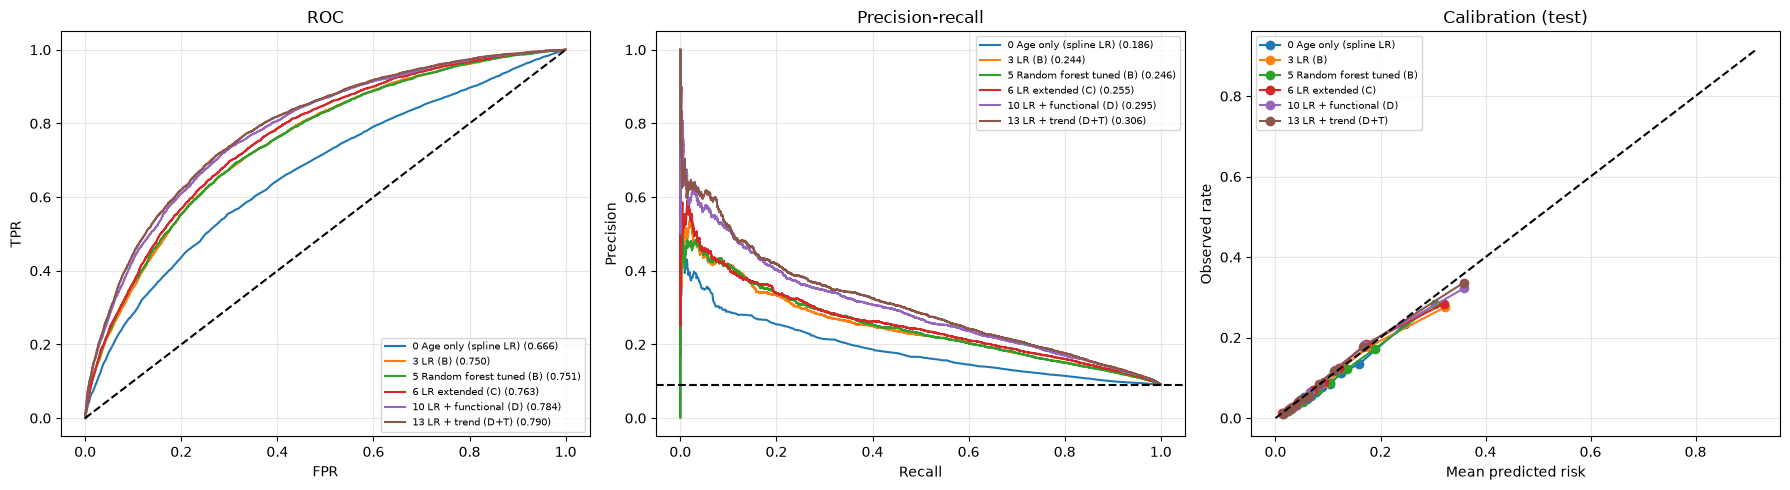

In [21]:
show = [n for n in ["0 Age only (spline LR)", "3 LR (B)", "5 Random forest tuned (B)", "6 LR extended (C)",
                    "10 LR + functional (D)", "13 LR + trend (D+T)"] if n in RESULTS]
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for n in show:
    p = RESULTS[n]["p_test"]
    fpr, tpr, _ = roc_curve(y_test, p); ax[0].plot(fpr, tpr, label=f"{n} ({roc_auc_score(y_test, p):.3f})")
    pr, rc, _ = precision_recall_curve(y_test, p); ax[1].plot(rc, pr, label=f"{n} ({average_precision_score(y_test, p):.3f})")
    fp, mp = calibration_curve(y_test, p, n_bins=10, strategy="quantile"); ax[2].plot(mp, fp, marker="o", label=n)
ax[0].plot([0, 1], [0, 1], "k--"); ax[0].set(title="ROC", xlabel="FPR", ylabel="TPR")
ax[1].axhline(y_test.mean(), color="k", ls="--"); ax[1].set(title="Precision-recall", xlabel="Recall", ylabel="Precision")
m = max(0.5, float(np.max([RESULTS[n]["p_test"].max() for n in show if "balanced" not in n])))
ax[2].plot([0, m], [0, m], "k--"); ax[2].set(title="Calibration (test)", xlabel="Mean predicted risk", ylabel="Observed rate")
for a in ax: a.legend(fontsize=7); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"{OUT}/roc_pr_calibration.png", dpi=200); plt.show()

**Reading the output.** The ROC and precision-recall curves of the stronger models lie above those of the basic models, and the calibration curves of the unweighted models follow the diagonal, i.e. the predicted
probabilities can be read as risks. (The class-weighted "balanced" model is deliberately not drawn: it overestimates risk by construction.)

### Stability of the models over time and across subgroups
**Aim:** Check whether the discrimination of the models holds up in the two test transitions, for men and women, and within age groups.

**Why:** A good overall AUC can hide poor performance in some groups or periods. Subgroup results show where the model is less reliable and whether the ranking of the models is the same everywhere.

**Method:** For six models, compute the test AUC separately for the wave pairs 7 -> 8 and 8 -> 9, for men and women, and for the age groups 65-69, 70-74, 75-79, 80-84 and 85+. The models are not refitted: the stored test predictions are split by group.

**Input:** Stored test predictions of the six models in `show`, test outcomes, wave, sex and age of the test pairs.

**Decision rule:** Performance is stable if the AUC is similar across groups and the ranking of the models does not change.


In [22]:
def sub_auc(mask, n):
    """Test AUC of one model within a subgroup.

    Uses the global objects `y_test` and `RESULTS` (stored test predictions).

    Args:
        mask (np.ndarray): Boolean array selecting the test rows of the subgroup.
        n (str): Model name (key in `RESULTS`).

    Returns:
        float: AUC in the subgroup, or NaN if the subgroup contains only one outcome class.
    """
    return roc_auc_score(y_test[mask], RESULTS[n]["p_test"][mask]) if len(np.unique(y_test[mask])) > 1 else np.nan

agegrp = pd.cut(test["age"], [64, 69, 74, 79, 84, np.inf], labels=["65-69", "70-74", "75-79", "80-84", "85+"]).astype(str).values
sub = {}
for lab, mask in ([(f"{b}->{b+1}", (test["baseline_wave"] == b).values) for b in TEST_BASE] +
                  [("male", (test["female"] == 0).values), ("female", (test["female"] == 1).values)] +
                  [(f"age {a}", agegrp == a) for a in ["65-69", "70-74", "75-79", "80-84", "85+"]]):
    sub[lab] = {n[:28]: sub_auc(mask, n) for n in show}
sub = pd.DataFrame(sub).T
print("Validation AUC (wave 6->7) vs test AUC (7->8, 8->9) shows temporal drift; wave 8->9 spans COVID-19.")
print(sub.round(3))

Validation AUC (wave 6->7) vs test AUC (7->8, 8->9) shows temporal drift; wave 8->9 spans COVID-19.
           0 Age only (spline LR)  3 LR (B)  5 Random forest tuned (B)  6 LR extended (C)  10 LR + functional (D)  13 LR + trend (D+T)
7->8                        0.663     0.743                      0.747              0.758                   0.778                0.785
8->9                        0.672     0.759                      0.756              0.769                   0.790                0.795
male                        0.640     0.737                      0.737              0.751                   0.768                0.774
female                      0.685     0.759                      0.762              0.771                   0.794                0.800
age 65-69                   0.503     0.734                      0.730              0.756                   0.780                0.783
age 70-74                   0.534     0.701                      0.700              0.722 

**Result:**
1. **Over time.** All models discriminate somewhat better in the pair 8 -> 9 than in 7 -> 8 (LR with functional indicators: 0.790 vs 0.778), so the COVID-19 wave pair is not worse. The lower value for 7 -> 8 is probably linked to the SHARELIFE respondents of wave 7 (see the sensitivity analysis).
2. **Sex.** The AUC is higher for women than for men for every model (LR with functional indicators: 0.794 vs 0.768).
3. **Age.** Within narrow age bands the AUC is lower (LR with functional indicators: 0.780 at 65-69, 0.698 at 85+; in between 0.733-0.747), partly because age itself no longer separates people inside a band (the age-only model is at chance level, 0.503, in the 65-69 band). The other variables still discriminate, and the gain of the functional indicators over the basic model LR (B) is largest in the oldest groups (+0.056 at 80-84, +0.043 at 85+).
4. **Ranking of models.** The ranking is the same in every subgroup: the models with functional indicators (and trend) are best, followed by the extended and the basic models. No confidence intervals are shown, so differences of about 0.01 between groups should not be interpreted.


### This step below **aims** to determine whether PCA can reduce 8 components to a smaller number general variables

Reason: PCA only helps if the predictors are strongly correlated

**Method:**
1. Standardise the 8 numeric variables and run PCA;
2. inspect eigenvalues (Kaiser rule for eigenvalue > 1) and cumulative explained variance;
3. fit logistic regression on k = 1, 2, 3, 4, 5, 6, 7, 8 components in the development period and compare validation AUC with LR without PCA.

**Input:** Numeric variables of set B (Variables include age, female (binary variable so not included for PCA) sphus, chronic_mod, maxgrip, eurod, bmi, log_income_eq, recall_imm)

set A only has four variables. set C and set D have more categorical variables.

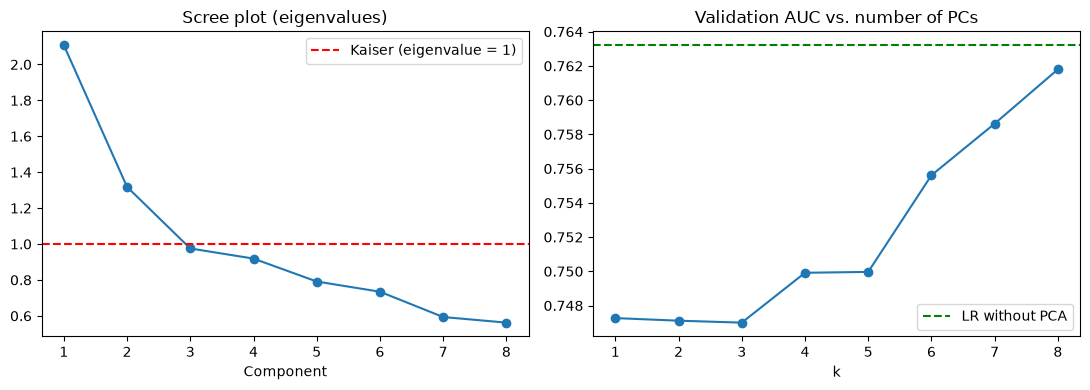

component  eigenvalue  explained_%  cumulative_%  Kaiser (eigenvalue>1)
      PC1        2.11        26.34         26.34                   True
      PC2        1.32        16.47         42.81                   True
      PC3        0.98        12.19         55.00                  False
      PC4        0.92        11.48         66.48                  False
      PC5        0.79         9.89         76.37                  False
      PC6        0.73         9.18         85.55                  False
      PC7        0.59         7.42         92.97                  False
      PC8        0.56         7.03        100.00                  False
Eigenvalues: [2.11 1.32 0.98 0.92 0.79 0.73 0.59 0.56] -> components with eigenvalue > 1: 2
Cumulative variance of first 4 PCs: 66.5%
                 PC1    PC2    PC3    PC4
age            0.342 -0.436 -0.007  0.494
sphus          0.488  0.263  0.122 -0.077
chronic_mod    0.336  0.407  0.302  0.333
maxgrip       -0.369  0.347 -0.248  0.262
eurod   

In [23]:
num_B = [c for c in F_B if c not in CAT_COLS + BIN_COLS]
Z = StandardScaler().fit_transform(SimpleImputer(strategy="median").fit_transform(trv[num_B]))
ev = PCA().fit(Z).explained_variance_
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(range(1, len(ev) + 1), ev, "o-"); ax[0].axhline(1, color="r", ls="--", label="Kaiser (eigenvalue = 1)")
ax[0].set(title="Scree plot (eigenvalues)", xlabel="Component"); ax[0].legend()
ks = list(range(1, len(num_B) + 1)); aucs = []
for k in ks:
    m_ = fit_model(pca_lr(F_B, k), dev[F_B], dev["y"]); aucs.append(roc_auc_score(val["y"], m_.predict_proba(val[F_B])[:, 1]))
ax[1].plot(ks, aucs, "o-"); ax[1].axhline(RESULTS["3 LR (B)"]["val_auc"], color="g", ls="--", label="LR without PCA")
ax[1].set(title="Validation AUC vs. number of PCs", xlabel="k"); ax[1].legend()
plt.tight_layout(); plt.savefig(f"{OUT}/pca_diagnostics.png", dpi=200); plt.show()
_pf = PCA().fit(Z)
pca_tab = pd.DataFrame({"component": [f"PC{i}" for i in range(1, len(ev) + 1)], "eigenvalue": _pf.explained_variance_,
                        "explained_%": _pf.explained_variance_ratio_ * 100, "cumulative_%": np.cumsum(_pf.explained_variance_ratio_) * 100,
                        "Kaiser (eigenvalue>1)": _pf.explained_variance_ > 1}).round(2)
print(pca_tab.to_string(index=False)); pca_tab.to_csv(f"{OUT}/pca_variance_table.csv", index=False)
print("Eigenvalues:", np.round(ev, 2), "-> components with eigenvalue > 1:", int((ev > 1).sum()))
pca4 = PCA(n_components=4).fit(Z)
print("Cumulative variance of first 4 PCs: %.1f%%" % (pca4.explained_variance_ratio_.sum() * 100))
print(pd.DataFrame(pca4.components_.T, index=num_B, columns=[f"PC{i}" for i in range(1, 5)]).round(3))

print("(PC signs are arbitrary; labels such as 'general ageing/health' are descriptive only.)")

Each component is a weighted combination of all eight variables; the interpretation is based on the variables with the largest loadings.

For example, the first component (PC1) reflects general health and ageing. For PC4 5 6 7 8 have no clear meaning. Later components still carry predictive information (validation AUC rises from 0.747 with three components to 0.762 with eight).

Validation AUC increases with the number of components and never exceeds that of the logistic regression without PCA.

**Result:** PCA does **not** help, we keep the original, interpretable variables.
1. Only two eigenvalues exceed 1;
2. First four components explain 66.5 % variance;
3. The best number of components is k = 8, which means no compression;
The negative - signs are arbitrary.

### PCA versus no PCA for the larger feature sets (B, D, D+T)

**Aim:** Check whether PCA becomes useful when more variables are available (feature sets D and D+T), not only for the eight numeric variables of set B.

**Why:** PCA is only useful if the predictors are strongly correlated, so that a few components carry most of the information. Larger sets could contain more redundancy.

**Method:** For each set, fit PCA + Logistic Regression with k = 1 ... number of numeric variables on the development period and compare the validation AUC with the logistic regression on the original variables (dashed line). Binary variables and country stay outside the PCA. We also count how many components are needed for 80 % and 90 % of the variance. Models 4, 22 and 23 in the main table use the best k of these curves.

**Input:** Feature sets B, D and D+T; development, validation and test periods.

**Decision rule:** PCA is useful only if few components explain most of the variance and the best k is clearly smaller than the number of variables.

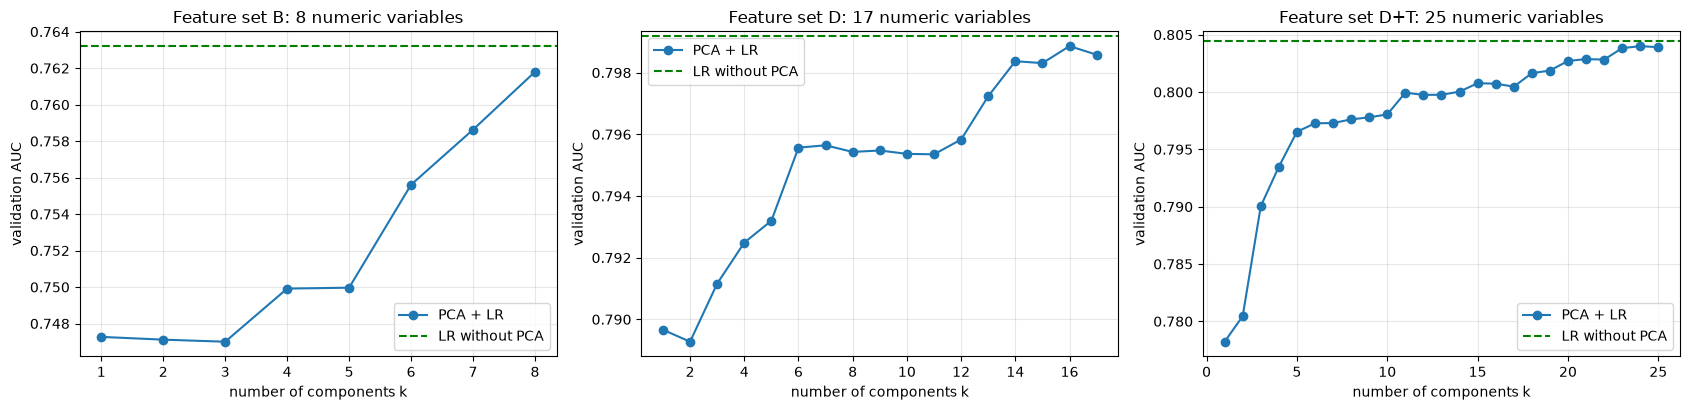

feature set  numeric variables  PCs for 80 % variance  PCs for 90 % variance best k (validation)  test AUC PCA + LR  test AUC LR without PCA  difference
          B                  8                      6                      7                 k=8             0.7485                   0.7504     -0.0019
          D                 17                     11                     14                k=16             0.7824                   0.7837     -0.0012
        D+T                 25                     16                     19                k=24             0.7885                   0.7898     -0.0013

=> PCA changes the test AUC by B: -0.0019, D: -0.0012, D+T: -0.0013 | components needed for 90 % of the variance: B: 7 of 8, D: 14 of 17, D+T: 19 of 25


In [24]:
# PCA versus no PCA for the larger feature sets (B, D, D+T): validation AUC against the number of components k,
# compared with the logistic regression on the original variables; binary variables and country stay outside the PCA
rows11b = []
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
for j, (lab, fs, ref, pc) in enumerate([("B", F_B, "3 LR (B)", "4 PCA + LR (B)"), ("D", F_D, "10 LR + functional (D)", "22 PCA + LR (D)"),
                                         ("D+T", F_T, "13 LR + trend (D+T)", "23 PCA + LR (D+T)")]):
    numc = [c for c in fs if c not in CAT_COLS + BIN_COLS]; pn = len(numc)          # numerical variables entering the PCA
    ks = list(range(1, pn + 1, 3 if FAST else 1)); aucs = []
    for k in ks:                                                                     # fit on development, evaluate on validation
        m_ = fit_model(pca_lr(fs, k), dev[fs], dev["y"]); aucs.append(roc_auc_score(val["y"], m_.predict_proba(val[fs])[:, 1]))
    ax[j].plot(ks, aucs, "o-", label="PCA + LR"); ax[j].axhline(RESULTS[ref]["val_auc"], color="g", ls="--", label="LR without PCA")
    ax[j].set(title=f"Feature set {lab}: {pn} numeric variables", xlabel="number of components k", ylabel="validation AUC"); ax[j].legend(); ax[j].grid(alpha=.3)
    # cumulative explained variance on the training period (standardised variables)
    Zs = StandardScaler().fit_transform(SimpleImputer(strategy="median").fit_transform(trv[numc]))
    cum = np.cumsum(PCA().fit(Zs).explained_variance_ratio_)
    rows11b.append({"feature set": lab, "numeric variables": pn, "PCs for 80 % variance": int(np.argmax(cum >= .8)) + 1, "PCs for 90 % variance": int(np.argmax(cum >= .9)) + 1,
                    "best k (validation)": RESULTS[pc]["label"], "test AUC PCA + LR": round(roc_auc_score(y_test, RESULTS[pc]["p_test"]), 4),
                    "test AUC LR without PCA": round(roc_auc_score(y_test, RESULTS[ref]["p_test"]), 4),
                    "difference": round(roc_auc_score(y_test, RESULTS[pc]["p_test"]) - roc_auc_score(y_test, RESULTS[ref]["p_test"]), 4)})
savefig("pca_vs_no_pca")
t11b = pd.DataFrame(rows11b); print(t11b.to_string(index=False)); t11b.to_csv(f"{OUT}/pca_vs_no_pca.csv", index=False)
print("\n=> PCA changes the test AUC by", ", ".join(f"{r['feature set']}: {r['difference']:+.4f}" for r in rows11b),
      "| components needed for 90 % of the variance:", ", ".join(f"{r['feature set']}: {r['PCs for 90 % variance']} of {r['numeric variables']}" for r in rows11b))

**Result:**

| Feature set | Numeric variables | PCs for 80 % / 90 % variance | Best k | Test AUC PCA + LR | Test AUC LR | Difference |
|---|---|---|---|---|---|---|
| B | 8 | 6 / 7 | 8 | 0.7485 | 0.7504 | -0.0019 |
| D | 17 | 11 / 14 | 16 | 0.7824 | 0.7837 | -0.0012 |
| D+T | 25 | 16 / 19 | 24 | 0.7885 | 0.7898 | -0.0013 |

1. Also for the larger sets, many components are needed to keep most of the information (14 of 17 and 19 of 25 for 90 % of the variance), so the predictors are only weakly correlated.
2. The best number of components is (almost) the number of variables, i.e. no compression, and PCA + LR is never better than the logistic regression on the original variables.
3. PCA is therefore not used in the final model; the original variables are kept because they allow odds ratios per variable.

### PCA implemented from scratch

**Aim:** Show that we understand what PCA computes, by implementing it ourselves and comparing it with scikit-learn.

**Method:** PCA = eigen-decomposition of the covariance matrix of the standardised variables (the eight numeric variables of set B). The eigenvalues are sorted from largest to smallest; the component scores are the standardised data multiplied by the eigenvectors.

**Decision rule:** The implementation is correct if the eigenvalues and the component scores agree with scikit-learn (scores up to sign).

In [25]:
# PCA implemented from scratch: eigen-decomposition of the covariance matrix of the standardised variables,
# compared with scikit-learn (same eigenvalues, same component scores up to sign)
cov = np.cov(Z, rowvar=False)                       # Z: standardised numeric variables of feature set B (PCA diagnostics above)
w_, V_ = np.linalg.eigh(cov); o_ = np.argsort(w_)[::-1]; w_, V_ = w_[o_], V_[:, o_]   # eigenvalues / eigenvectors, largest first
scores_ = Z @ V_[:, :4]; sk_ = PCA(n_components=4).fit_transform(Z)                    # own and scikit-learn component scores
print("eigenvalues (from scratch):", np.round(w_, 3))
print("max |eigenvalue difference| to scikit-learn:", float(np.abs(w_ - ev).max()))
print("|correlation| between own and scikit-learn scores of PC1-PC4:", [round(float(abs(np.corrcoef(scores_[:, i], sk_[:, i])[0, 1])), 6) for i in range(4)])
print("explained variance of PC1-PC4 (%):", np.round(w_[:4] / w_.sum() * 100, 2))

eigenvalues (from scratch): [2.107 1.318 0.975 0.919 0.791 0.734 0.593 0.562]
max |eigenvalue difference| to scikit-learn: 8.881784197001252e-16
|correlation| between own and scikit-learn scores of PC1-PC4: [1.0, 1.0, 1.0, 1.0]
explained variance of PC1-PC4 (%): [26.34 16.47 12.19 11.48]


**Result:** The own implementation reproduces scikit-learn exactly: the eigenvalues are 2.107, 1.318, 0.975, 0.919, 0.791, 0.734, 0.593 and 0.562 (largest difference 1.3e-15), the scores of PC1–PC4 have a correlation of 1.0 in absolute value with the scikit-learn scores (only the sign may differ), and PC1–PC4 explain 26.34 %, 16.47 %, 12.19 % and 11.48 % of the variance.

### Odds ratios for the primary variables (feature set B)

The **odds** of an event are the probability that it occurs divided by the probability that it does not.

Odds ratios (OR) per +1 Standard deviation with cluster-robust 95 % Confidence Interval (CI) using primary features with no class weights

**Aim:** Quantify how strongly each primary baseline variable is associated with the odds of a new ADL limitation at the next wave.

**Reason:** Prediction metrics (AUC) say how well the model ranks people, but not which variables drive the prediction or in which direction. Odds ratios give interpretable effect sizes for decision support.

**Method:** Standardise the numeric variables (mean 0, SD 1) and fit an unpenalised logistic regression without class weights on the training period. Standard errors are cluster-robust by household because spouses share a household and are not independent.

**Input:** The 9 variables of set B

**Decision rule:** OR > 1: higher value, higher odds; OR < 1: lower odds; a 95 % CI that contains 1 (p ≥ 0.05) means no clear association.


In [26]:
try:
    import statsmodels.api as sm
    prep = make_prep(F_B, spline_cols=())
    Xt = prep.fit_transform(trv[F_B]); names_t = [s.split("__", 1)[1] for s in prep.get_feature_names_out()]
    Xt = np.asarray(Xt.todense()) if hasattr(Xt, "todense") else np.asarray(Xt)
    res = sm.Logit(trv["y"].values, sm.add_constant(Xt)).fit(disp=0, cov_type="cluster",
                                                             cov_kwds={"groups": pd.factorize(trv["hh_key"])[0]})
    orr = pd.DataFrame({"feature": ["const"] + names_t, "OR": np.exp(res.params), "CI_low": np.exp(res.conf_int()[:, 0]),
                        "CI_high": np.exp(res.conf_int()[:, 1]), "p": res.pvalues}).iloc[1:]
    print("OR per +1 SD for continuous variables (standardised); binary variables: 0 -> 1")
    print(orr.sort_values("OR", ascending=False).round(3).to_string(index=False))
    orr.round(4).to_csv(f"{OUT}/odds_ratios_cluster_robust.csv", index=False)
except Exception as e:
    print("statsmodels step skipped:", e)

statsmodels step skipped: No module named 'statsmodels'


We report odds ratios to quantify the direction and strength of each predictor’s association with a new ADL limitation, which makes the final logistic regression interpretable and shows which variables matter most.

**Result:** 
1. self-rated health(sphus), age, EURO-D, BMI, chronic diseases(chronic_mod) are associated with higher odds of the future outcome
2. Being female, recall ability and grip strength are associated with lower odds of the future outcome.
3. income does not show a statistically significant association with the outcome

From the data, we can find out that  worse self-rated health (OR 1.66 per SD, 95 % CI 1.60–1.72), higher age (1.54), higher depression score (1.21), higher BMI (1.21) and more chronic diseases (1.08) were associated with higher odds of a new ADL limitation, while better recall (0.86), stronger grip (0.76) and female sex (0.72) were associated with lower odds. Income showed no association (1.01, p = 0.50).

Therefore, **Current health status** (self-rated health, age, depression, BMI) is the strongest signal for a future ADL limitation, **physical and cognitive capacity** (grip strength, recall) are protective, and **income** adds no independent information once these are taken into account.

These results indicate statistical associations rather than causal relationships.

### Odds ratios (OR) in ORIGINAL units

OR = factor by which the ODDS of a new ADL limitation change when the variable increases (with age, grip and BMI: per 5 units)

**Purpose:**
To examine the strength of the association with the odds of developing a new ADL limitation in the future.

**Reason:** Odds ratios per standard deviation (previous step) are good for ranking variables, but difficult to explain to non-statisticians. Original units (per 5 years of age, per 5 kg of grip strength, per extra IADL difficulty) are easier to interpret, and the comparison across feature sets shows which effects are explained by the new information.

**Method:** For each feature set: fill missing values with the median, rescale age, grip strength and BMI to 5-unit steps, add country dummies as controls, and fit an unpenalised logistic regression with household-clustered standard errors. Constant or collinear columns are dropped.

**Input:** Feature sets B, D and D+T, training period (development + validation).

**Decision rule:** OR > 1: higher value, higher odds; OR < 1: lower odds; p ≥ 0.05: no clear association.


In [27]:
def or_table_original_units(feats, title, scale=None):

    """Fit a logistic regression and report odds ratios in the original units of the variables.

    Missing values are filled with the median. Age, grip strength and BMI are divided by 5, so their odds ratios
    refer to a 5-unit change; all other variables keep their own unit (binary variables: 0 -> 1). Country enters
    as dummy controls and is not reported. Standard errors are cluster-robust by household. The table is printed
    and saved as a CSV file.

    Note:
        Uses the global objects `trv` (training data) and `OUT` (output folder).

    Args:
        feats (list[str]): Predictor columns, e.g. F_B, F_D or F_T.
        title (str): Heading of the table; its first word is used in the CSV file name.
        scale (dict | None): Divisor per variable, e.g. {"age": 5}. Default: age, maxgrip and bmi by 5.

    Returns:
        pd.DataFrame: One row per variable with OR, CI_low, CI_high, p, "odds change %" and "reading".
    """

    import statsmodels.api as sm
    scale = scale or {"age": 5, "maxgrip": 5, "bmi": 5}
    X = trv[feats].copy()
    ctrl = pd.get_dummies(X["country"], prefix="country", drop_first=True).astype(float) if "country" in X else None
    X = X.drop(columns=["country"], errors="ignore")
    X = X.apply(lambda c: c.fillna(c.median())).astype(float)
    for v, k in scale.items():
        if v in X:
            X[v] = X[v] / k
    X = X.rename(columns={v: f"{v} (per {k})" for v, k in scale.items() if v in X})
    Xc = pd.concat([X, ctrl], axis=1) if ctrl is not None else X
    Xc = Xc.loc[:, Xc.std() > 1e-9]                                   # drop constant columns (e.g. country with no rows)
    q, r_ = np.linalg.qr(Xc.values - Xc.values.mean(0)); keep = np.abs(np.diag(r_)) > 1e-8 * np.abs(r_).max()
    if not keep.all():
        print("dropped collinear columns:", list(Xc.columns[~keep])); Xc = Xc.loc[:, keep]
    res = sm.Logit(trv["y"].values, sm.add_constant(Xc.astype(float))).fit(disp=0, cov_type="cluster",
                                                                           cov_kwds={"groups": pd.factorize(trv["hh_key"])[0]})
    ci = np.asarray(res.conf_int())
    t = pd.DataFrame({"OR": np.exp(np.asarray(res.params)), "CI_low": np.exp(ci[:, 0]), "CI_high": np.exp(ci[:, 1]),
                      "p": np.asarray(res.pvalues)}, index=res.params.index)
    t = t.drop(index="const"); t = t[~t.index.str.startswith("country_")]
    t["odds change %"] = (t["OR"] - 1) * 100
    t["reading"] = np.where(t["p"] >= 0.05, "no clear association", np.where(t["OR"] > 1, "higher value -> higher risk", "higher value -> lower risk"))
    print(f"\n{title}"); print(t.sort_values("OR", ascending=False).round(3).to_string())
    t.round(4).to_csv(f"{OUT}/odds_ratios_original_units_{title.split()[0]}.csv")
    return t

try:
    or_B = or_table_original_units(F_B, "B primary variables (original units)")
    or_D = or_table_original_units(F_D, "D extended + functional (original units)")
    or_T = or_table_original_units(F_T, "T with trend (original units)")
except Exception as e:
    print("odds-ratio table skipped:", e)

odds-ratio table skipped: No module named 'statsmodels'


**Result:** 
1. Physical function indicators are strongly associated with future ADL limitations. These variables includes IADL, mobility, large-muscle function, and grip strength provide valuable predictive information.
2. Trend model (T) shows that a person who has been poor for a long time is at higher risk than someone who has only recently worsened.

In original units, each additional IADL difficulty is associated with 44 % higher odds of a new ADL limitation (OR 1.44, 95 % CI 1.37–1.51), each additional large-muscle difficulty with 26 % higher odds (1.26) and each additional mobility difficulty with 18 % higher odds (1.18). Adding these indicators reduces the odds ratios of self-rated health (1.66 to 1.34), age per 5 years (1.42 to 1.29) and depression score (1.10 to 1.04), which shows that part of their effect is shared with physical function.

### Logistic regression implemented from scratch (Newton-Raphson / IRLS)

**Aim:** Show how the logistic regression behind the odds ratios is estimated, by implementing maximum likelihood ourselves and comparing it with scikit-learn.

**Method:** Newton-Raphson (iteratively re-weighted least squares) on the standardised primary variables of set B (no splines). Each step solves (X'WX) step = X'(y - p), where p are the predicted probabilities and W = p(1 - p). The reference is an (almost) unpenalised scikit-learn logistic regression.

**Decision rule:** The implementation is correct if coefficients and test AUC agree with scikit-learn.

In [28]:
def logistic_newton(X, y, iters=50, tol=1e-9):
    """Fit a logistic regression by maximum likelihood with the Newton-Raphson (IRLS) algorithm.

    Args:
        X: Design matrix (n x p) as a NumPy array; must contain a column of ones for the intercept.
        y: Binary outcome (0/1) as a NumPy array of floats.
        iters: Maximum number of Newton-Raphson iterations.
        tol: Convergence tolerance for the largest coefficient change.

    Returns:
        NumPy array with the estimated coefficients (intercept first if the first column of X is ones).
    """
    w = np.zeros(X.shape[1])                                        # start at all coefficients = 0
    for _ in range(iters):
        mu = 1 / (1 + np.exp(-(X @ w))); W = mu * (1 - mu)            # predicted probabilities and IRLS weights
        step = np.linalg.solve((X * W[:, None]).T @ X, X.T @ (y - mu)); w += step   # Newton step: (X'WX)^-1 X'(y - mu)
        if np.max(np.abs(step)) < tol:
            break
    return w

# logistic regression implemented from scratch on the standardised primary variables (set B), compared with scikit-learn
prepB = make_prep(F_B, spline_cols=())                              # same preprocessing as for the odds ratios per SD (no splines)
XtrB = prepB.fit_transform(trv[F_B]); XteB = prepB.transform(test[F_B])
XtrB = np.asarray(XtrB.todense()) if hasattr(XtrB, "todense") else np.asarray(XtrB)
XteB = np.asarray(XteB.todense()) if hasattr(XteB, "todense") else np.asarray(XteB)
w_own = logistic_newton(np.c_[np.ones(len(XtrB)), XtrB], trv["y"].values.astype(float))
lr_ref = LogisticRegression(C=1e10, max_iter=5000).fit(XtrB, trv["y"])          # (almost) unpenalised reference
print("max |coefficient difference| own vs scikit-learn:", float(np.abs(w_own[1:] - lr_ref.coef_[0]).max()), "| intercept difference:", float(abs(w_own[0] - lr_ref.intercept_[0])))
p_own = 1 / (1 + np.exp(-(np.c_[np.ones(len(XteB)), XteB] @ w_own)))           # test-period probabilities of the own model
print(f"test AUC own implementation {roc_auc_score(y_test, p_own):.4f} | scikit-learn {roc_auc_score(y_test, lr_ref.predict_proba(XteB)[:, 1]):.4f}")
print(pd.DataFrame({"feature": [x.split("__", 1)[1] for x in prepB.get_feature_names_out()], "coef (own)": w_own[1:], "OR per SD / 0->1": np.exp(w_own[1:])}).round(3).to_string(index=False))

max |coefficient difference| own vs scikit-learn: 0.0016652917425739044 | intercept difference: 0.001427365324302876
test AUC own implementation 0.7485 | scikit-learn 0.7485
      feature  coef (own)  OR per SD / 0->1
          age       0.433             1.542
        sphus       0.507             1.660
  chronic_mod       0.078             1.081
      maxgrip      -0.278             0.757
        eurod       0.193             1.213
          bmi       0.190             1.210
log_income_eq       0.009             1.009
   recall_imm      -0.148             0.863
       female      -0.334             0.716


**Result:** The own implementation gives the same model as scikit-learn: the largest coefficient difference is 0.0017 (intercept 0.0014) and the test AUC is 0.7485 for both. The odds ratios per SD (exp of the coefficients) are the same as in the odds-ratio table for set B: self-rated health 1.660, age 1.542, EURO-D 1.213, BMI 1.210, chronic diseases 1.081, income 1.009, recall 0.863, grip strength 0.757 and female 0.716.

### Variable importance of the extended logistic regressions (permutation importance, partial dependence)

1. permutation importance: how much AUC is lost when one variable is shuffled
2. partial dependence: how predicted risk changes with one variable on average


**Aim:** Find out which variables matter most for the extended logistic regressions, and how each variable changes the predicted risk.

**Why:** With splines, country dummies and many correlated variables, single coefficients are hard to compare. Permutation importance measures each variable's contribution on one scale (AUC), and partial dependence shows the shape of its effect on the probability scale, so both can be checked against the odds ratios.

**Method:** (1) Permutation importance: shuffle one variable at a time in the test data and measure the loss in AUC (8 repeats, 20,000 test rows) for the LR models C, D and D+T. (2) Partial dependence: average predicted risk when one variable is set to each value of its range, for the six most important numeric variables of LR D+T.

**Input:** Fitted models stored in `RESULTS`, test period.

**Decision rule:** A larger AUC drop means a more important variable; the curve shape shows the direction of the effect.



6 LR extended (C)
       feature  mean_AUC_drop     sd
        sphus         0.0354 0.0033
          age         0.0354 0.0024
      country         0.0154 0.0026
      maxgrip         0.0122 0.0015
         casp         0.0093 0.0011
       female         0.0091 0.0014
          bmi         0.0076 0.0015
 activity_low         0.0044 0.0011
received_help         0.0022 0.0005
        eurod         0.0021 0.0006
    hc002_mod         0.0019 0.0002
   recall_imm         0.0018 0.0007
   recall_del         0.0013 0.0006
   given_help         0.0011 0.0003
  chronic_mod         0.0009 0.0002

10 LR + functional (D)
      feature  mean_AUC_drop     sd
         age         0.0226 0.0017
    lgmuscle         0.0169 0.0013
     country         0.0154 0.0022
       sphus         0.0144 0.0018
      female         0.0118 0.0015
     maxgrip         0.0080 0.0012
 mobilityind         0.0060 0.0008
      iadlza         0.0059 0.0006
        casp         0.0045 0.0006
         bmi         0.0040 0

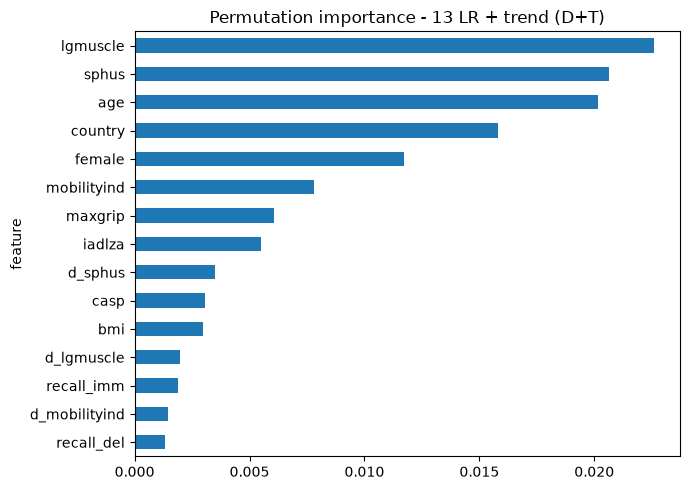

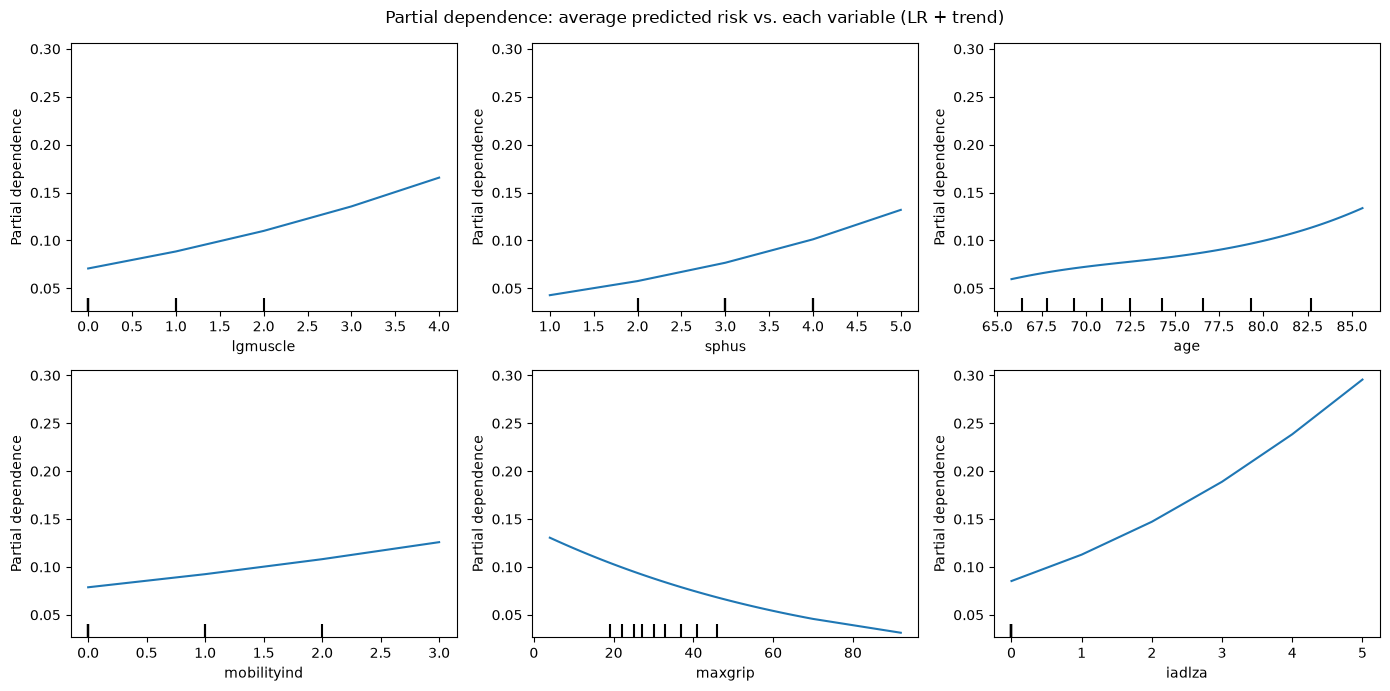

In [29]:
from sklearn.inspection import PartialDependenceDisplay
sub_idx = np.random.default_rng(0).choice(len(test), min(20000, len(test)), replace=False)
IMP = {}
for nm in ["6 LR extended (C)", "10 LR + functional (D)", "13 LR + trend (D+T)"]:
    r = RESULTS[nm]
    pi = permutation_importance(r["model"], test[r["feats"]].iloc[sub_idx], test["y"].iloc[sub_idx], scoring="roc_auc",
                                n_repeats=3 if FAST else 8, random_state=RANDOM_STATE, n_jobs=1)
    IMP[nm] = pd.DataFrame({"feature": r["feats"], "mean_AUC_drop": pi.importances_mean, "sd": pi.importances_std}).sort_values("mean_AUC_drop", ascending=False)
    print(f"\n{nm}\n", IMP[nm].head(15).round(4).to_string(index=False))
    IMP[nm].round(4).to_csv(f"{OUT}/permutation_importance_{nm.split()[0]}.csv", index=False)
nm = "13 LR + trend (D+T)"
IMP[nm].head(15)[::-1].plot.barh(x="feature", y="mean_AUC_drop", legend=False, figsize=(7, 5), title=f"Permutation importance - {nm}")
savefig("importance_permutation_LR_trend")

# partial dependence of the 6 most important numeric variables
top_num = [f for f in IMP[nm]["feature"] if f != "country" and test[f].nunique() > 2][:6]
# rows with a missing value in a plotted variable are left out: otherwise the grid of that variable is computed from
# percentiles that include NaN (empty or stretched curve, e.g. maxgrip)
Xpd = test[RESULTS[nm]["feats"]].iloc[sub_idx[:6000]].dropna(subset=top_num)
# float32 columns from the Stata file cannot take the float64 grid values in recent pandas versions -> convert to float64 (country stays categorical)
Xpd = Xpd.astype({c: "float64" for c in Xpd.columns if c not in CAT_COLS})

fig, ax = plt.subplots(2, 3, figsize=(14, 7))
# response_method="predict_proba" puts the y-axis on the probability scale
PartialDependenceDisplay.from_estimator(RESULTS[nm]["model"], Xpd, top_num, kind="average", ax=ax.ravel()[:len(top_num)],
                                        method="brute", response_method="predict_proba")
fig.suptitle("Partial dependence: average predicted risk vs. each variable (LR + trend)"); savefig("importance_partial_dependence")



**Result:** 
1. Large-muscle function (lgmuscle), age, self-rated health and country are the most important predictors of the models with functional indicators, followed by sex, grip strength, mobility and IADL difficulties.
2. Once the functional indicators are added, the importance of age falls from 0.035 to 0.023 AUC and that of self-rated health from 0.035 to 0.014, i.e. part of their information is shared with physical function.
3. The direction of the effects agrees with the odds ratios: more functional difficulties, older age, poorer self-rated health, lower grip strength and male sex are associated with a higher predicted risk. The trend variables (d_*) contribute less than the current level (largest: d_sphus, 0.004).
4. Importance of correlated variables (IADL, large-muscle, mobility) is shared between them and should not be read separately.


5. **Partial dependence (LR D+T).**

The average predicted risk rises from about 7 % with no large-muscle difficulty to about 16.5 % with four, from about 8.5 % with no IADL difficulty to about 30 % with five (few people have that many), and from about 8 % to 12.5 % across 0–3 mobility difficulties. It rises with age (about 6 % at 66 to 13 % at 85, steeper after 80) and with poorer self-rated health (about 4 % for rating 1 to 13 % for rating 5), and falls with grip strength (about 13 % at 5 kg to about 7.5 % at 40 kg; beyond about 45 kg there are few observations). Because the model is a logistic regression, the curves are smooth and monotone; the shapes agree with the odds ratios. The values are read from the plot and are approximate.


### Sensitivity to the outcome definition (ADL >= 1 vs ADL >= 2)

**Aim:** Check whether the conclusions depend on how a "new ADL limitation" is defined: any new difficulty (ADL >= 1, main analysis) or at least two difficulties (ADL >= 2, more severe).

**Why:** The cut-off is a design choice. If the model ranking changed with the cut-off, the findings would not be reliable.

**Method:** For three models (LR B, LR C, LR D) keep the feature set and the hyper-parameters selected in the main analysis, refit each model on the training period with the ADL >= 1 and with the ADL >= 2 outcome, and evaluate both on the test period.

**Input:** Outcome columns `y_ge1` and `y_ge2`, training period (development + validation), test period.

**Decision rule:** The conclusions are robust if the ranking of the models and the size of the gains are similar for both outcomes.

In [30]:
rows = []
for ycol, lab in [("y_ge1", "ADL >= 1"), ("y_ge2", "ADL >= 2")]:
    for n in ["3 LR (B)", "6 LR extended (C)", "10 LR + functional (D)"]:
        r = RESULTS[n]
        m_ = fit_model(r["build"](), trv[r["feats"]], trv[ycol])
        p_ = m_.predict_proba(test[r["feats"]])[:, 1]
        p20, r20, l20 = topk(test[ycol].values, p_, 0.2)
        rows.append({"outcome": lab, "prevalence": test[ycol].mean(), "model": n, "AUC": roc_auc_score(test[ycol], p_),
                     "PR_AUC": average_precision_score(test[ycol], p_), "recall@top20%": r20, "lift@top20%": l20})
print(pd.DataFrame(rows).round(3).to_string(index=False))

 outcome  prevalence                  model   AUC  PR_AUC  recall@top20%  lift@top20%
ADL >= 1       0.090               3 LR (B) 0.750   0.244          0.500        2.498
ADL >= 1       0.090      6 LR extended (C) 0.763   0.255          0.518        2.591
ADL >= 1       0.090 10 LR + functional (D) 0.784   0.295          0.556        2.782
ADL >= 2       0.037               3 LR (B) 0.796   0.145          0.605        3.024
ADL >= 2       0.037      6 LR extended (C) 0.810   0.159          0.628        3.141
ADL >= 2       0.037 10 LR + functional (D) 0.829   0.196          0.669        3.347


**Result:**
1. The conclusions are robust to the outcome definition. With ADL ≥ 2 (prevalence 3.7 % instead of 9.0 %) the ranking of the models is unchanged: LR (C) outperforms LR (B) by +0.014 AUC (0.796 → 0.810) and LR (D) by +0.033 (→ 0.829), compared with +0.013 and +0.033 for ADL ≥ 1 (0.750 → 0.763 → 0.784).
2. All models discriminate better for the more severe outcome (AUC 0.829 vs 0.784 for LR (D)), and the 20 % highest-risk group captures more cases (recall 0.67 vs 0.56, lift 3.3 vs 2.8). Severe limitations are easier to anticipate from baseline health.
3. PR-AUC is lower for ADL ≥ 2 (0.196 vs 0.295 for LR (D)) only because the event is rarer; relative to prevalence it is higher (5.3 times vs 3.3 times). PR-AUC should therefore not be compared directly across outcomes.
4. The gain from the functional indicators is the same for both definitions, so the choice of ADL ≥ 1 as the primary outcome does not change the model conclusions.

*Limitation:* hyper-parameters were not re-tuned for ADL ≥ 2, no confidence intervals are computed here, and ADL ≥ 2 has only about 1,600 events in the test period.


### Person/household-disjoint pooled cross-validation
**Aim:** Check whether the results depend on the time-based split of the main analysis, in which the same person can appear in the training period (earlier waves) and in the test period (later waves).

**Why:** If a model partly "recognises" persons it has already seen, the test performance would be too optimistic. A validation in which no household is in both the training and the test part removes this possibility.

**Method:** All baseline -> follow-up pairs are split into 5 folds so that all rows of a household stay in the same fold (`GroupKFold`, group = household key). Each fold is predicted by a model trained on the other four folds. The out-of-fold predictions of all folds are then pooled and AUC and PR-AUC are computed once on the pooled predictions.

**Input:** All pairs (all waves), feature sets and hyper-parameters of LR (B), LR (C) and LR (D) from the main analysis.

**Decision rule:** The findings are robust if the ranking of the models and the size of the differences are similar to the temporal test.

In [31]:
gkf = GroupKFold(n_splits=5)
rows = []
for n in ["3 LR (B)", "6 LR extended (C)", "10 LR + functional (D)"]:
    r = RESULTS[n]
    p_ = cross_val_predict(r["build"](), pairs[r["feats"]], pairs["y"], groups=pairs["hh_key"], cv=gkf,
                           method="predict_proba")[:, 1]
    rows.append({"model": n, "pooled grouped-CV AUC": roc_auc_score(pairs["y"], p_), "PR_AUC": average_precision_score(pairs["y"], p_)})
print(pd.DataFrame(rows).round(3).to_string(index=False))

                 model  pooled grouped-CV AUC  PR_AUC
              3 LR (B)                  0.756   0.261
     6 LR extended (C)                  0.773   0.280
10 LR + functional (D)                  0.790   0.315


**Result:**
1. Pooled grouped-CV AUC (no household in both the training and the test fold) is 0.756 for LR (B), 0.773 for LR (C) and 0.790 for LR (D); PR-AUC is 0.261, 0.280 and 0.315.
2. The main conclusions agree with the temporal test: the extended feature set improves on the basic set by a similar margin (+0.017 vs +0.013 AUC), and the functional indicators add a further +0.017 (vs +0.021 in the temporal test). The ranking of the three models is the same in both designs.
3. The cross-validated AUCs are slightly higher than in the temporal test because this design has no drift over time. It therefore supplements, but does not replace, the temporal validation, which remains the primary analysis.
4. Because households never appear in both parts, the results are not driven by the model recognising persons it has seen before.


### Follow-up interval as an additional predictor
**Aim:** Check whether the differing time between baseline and follow-up interview (`interval_years`) drives the results.

**Why:** The outcome is "a new ADL limitation at the NEXT interview", not within a fixed time window. Most pairs are about 2 years apart, but some are longer (for example when interviews were delayed during COVID-19). A longer interval gives more time for a limitation to develop, which could distort the model.

**Method:** Add `interval_years` (capped at 4 years to limit extreme values) to feature set C, refit the logistic regression on the training period and compare the test AUC with the same model without the interval.

**Input:** Feature set C plus `interval_years`; training period and test period.


**Decision rule:** If the AUC hardly changes, the interval length does not drive the results.

In [32]:
F_Ci = F_C + ["interval_years"]
trv_i = trv.assign(interval_years=trv["interval_years"].clip(upper=4)); test_i = test.assign(interval_years=test["interval_years"].clip(upper=4))
m_ = fit_model(lr(F_Ci), trv_i[F_Ci], trv_i["y"])
print("LR extended + interval_years: test AUC =", round(roc_auc_score(test_i["y"], m_.predict_proba(test_i[F_Ci])[:, 1]), 4),
      "| without:", round(roc_auc_score(y_test, RESULTS["6 LR extended (C)"]["p_test"]), 4))

LR extended + interval_years: test AUC = 0.7623 | without: 0.763


**Result:** Adding the follow-up interval to the extended logistic regression does not improve prediction (test AUC 0.762 with and 0.763 without the interval). Most baseline -> follow-up pairs are about two years apart, so the interval carries almost no information, and the differences in interval length do not drive the results. The interval is only known after the follow-up interview and is therefore not a usable predictor; the check merely shows that the "next wave" outcome definition is not distorted by unequal intervals.

### Attrition: inverse-probability-of-follow-up weighting (IPW)
**Aim:** Check whether losing participants between baseline and follow-up biases the model or the estimated event rate.

**Why:** Only people who are interviewed again enter the analysis (retention differs by wave). If the people who drop out differ systematically from those who stay (for example older or less healthy), the observed sample is not representative of all eligible people.

**Method:** 

(1) Train a logistic regression that predicts, from baseline variables (feature set C), the probability that a person is followed up; it is trained on the training baselines only and does not use the outcome. 

(2) Give each followed-up person the weight "average retention rate / own retention probability" (probability clipped at 0.05, weight capped at 5), so that people who resemble those lost to follow-up count more. 

(3) Refit LR (C) and LR (D) with these weights and compare the test AUC, and compare the weighted with the raw event rate.

**Input:** All baseline-eligible people (also those without follow-up), feature set C, training baselines for the attrition model.

**Decision rule:** If the weighted and unweighted AUC are similar, attrition does not change the model's discrimination.


In [33]:
att_feats = F_C
tr_el = eligible[eligible["baseline_wave"].isin(DEV_BASE + VAL_BASE)]
att_model = lr(att_feats).fit(tr_el[att_feats], tr_el["has_followup"].astype(int))
p_follow = att_model.predict_proba(eligible[att_feats])[:, 1]
eligible = eligible.assign(w_ipw=np.clip(tr_el["has_followup"].mean() / np.clip(p_follow, 0.05, 1), 0, 5))
w_map = eligible.loc[eligible["has_followup"], "w_ipw"].values
pairs = pairs.assign(w_ipw=w_map)
dev, val = pairs[pairs["baseline_wave"].isin(DEV_BASE)], pairs[pairs["baseline_wave"].isin(VAL_BASE)]
trv, test = pairs[pairs["baseline_wave"].isin(DEV_BASE + VAL_BASE)], pairs[pairs["baseline_wave"].isin(TEST_BASE)]
print("Weights: mean %.2f, 99th pct %.2f, max %.2f" % (pairs.w_ipw.mean(), pairs.w_ipw.quantile(.99), pairs.w_ipw.max()))

rows = []
for n in ["6 LR extended (C)", "10 LR + functional (D)"]:
    r = RESULTS[n]
    m_w = fit_model(r["build"](), trv[r["feats"]], trv["y"], trv["w_ipw"].values)
    p_w = m_w.predict_proba(test[r["feats"]])[:, 1]
    rows.append({"model": n, "AUC unweighted fit": roc_auc_score(test["y"], r["p_test"]),
                 "AUC IPW fit": roc_auc_score(test["y"], p_w),
                 "AUC (IPW-weighted evaluation, IPW fit)": roc_auc_score(test["y"], p_w, sample_weight=test["w_ipw"]),
                 "weighted event rate": np.average(test["y"], weights=test["w_ipw"]), "raw event rate": test["y"].mean()})
print(pd.DataFrame(rows).round(3).to_string(index=False))

Weights: mean 1.04, 99th pct 2.51, max 5.00
                 model  AUC unweighted fit  AUC IPW fit  AUC (IPW-weighted evaluation, IPW fit)  weighted event rate  raw event rate
     6 LR extended (C)               0.763        0.763                                   0.764                0.097            0.09
10 LR + functional (D)               0.784        0.783                                   0.785                0.097            0.09


**Result:**
1. Inverse-probability-of-follow-up weighting does not change the discrimination of the models. The test AUC is 0.763 (LR C) and 0.784 (LR D) without weighting, 0.763 and 0.783 with IPW fitting, and 0.764 and 0.785 when the test sample is weighted as well. The weights are moderate (mean 1.04, 99th percentile 2.51, capped at 5).
2. Attrition does affect the estimated event rate: the weighted event rate in the test period is 9.7 % compared with 9.0 % in the observed sample, which suggests that people lost to follow-up are at somewhat higher risk. The absolute risks reported in this study may therefore be slightly too low for the whole eligible population.
3. IPW can only correct for differences that are visible in the baseline variables. People who died or became too ill to be interviewed are not observed, so some selection bias remains.


### Smoking as a sensitivity feature
**Aim:** Check whether adding current smoking to the extended logistic regression (feature set C) improves the prediction of a new ADL limitation.

**Why:** Smoking is a well-known health risk, so it might add information, but it was not part of the main feature sets. This check shows whether leaving it out costs predictive performance.

**Method:** Add the binary variable `current_smoker` (1 = current smoker, 0 = not) to feature set C, refit the logistic regression on the training period and compare the test AUC with the same model without smoking。

**Input:** Feature set C plus `current_smoker`; training period and test period.

**Decision rule:** If the AUC does not improve (the difference is smaller than the uncertainty of the AUC), smoking stays out of the main models.


In [34]:
F_Cs = F_C + ["current_smoker"]
m_ = fit_model(lr(F_Cs), trv[F_Cs], trv["y"])
print("LR extended + smoking: test AUC =", round(roc_auc_score(test["y"], m_.predict_proba(test[F_Cs])[:, 1]), 4),
      "| without smoking:", round(roc_auc_score(test["y"], RESULTS["6 LR extended (C)"]["p_test"]), 4))

LR extended + smoking: test AUC = 0.7625 | without smoking: 0.763


**Result:** 

Adding current smoking to the extended logistic regression does not improve prediction (test AUC 0.7625 with and 0.7630 without smoking), so smoking is left out of the main models. This is a statement about predictive contribution, not about the health effects of smoking: among people aged 65+, smokers are a selected group (many have died or quit because of illness), and part of the information is already contained in self-rated health, chronic diseases and grip strength.

### Persistence benchmark ("nobody develops a limitation")

**Aim:** Show what a model that never flags anyone achieves, so that the accuracy of the real models can be judged against it.

**Why:** Only about 9 % of the people in the test period develop a new limitation. With such an imbalanced outcome, a high accuracy can be reached without finding a single case, so accuracy alone says little about usefulness.

**Method:** The benchmark assumes persistence: everybody stays free of ADL limitations, as at baseline, i.e. it predicts "no new limitation" for every person. Its accuracy is the share of people without a new limitation; precision, recall and F1 are zero because no case is flagged.

**Input:** The test period outcome `y`.


**Decision rule:** A useful model must find cases (recall, precision, lift) and not only reach a high accuracy.

In [35]:
bench = np.zeros(len(test), dtype=int)
print(f"Accuracy {1 - test['y'].mean():.4f} | precision 0 | recall 0 | F1 0  -> accuracy alone is misleading at {test['y'].mean():.1%} prevalence")

Accuracy 0.9095 | precision 0 | recall 0 | F1 0  -> accuracy alone is misleading at 9.0% prevalence


**Result:**

The persistence benchmark ("nobody develops a limitation") reaches an accuracy of 90.95 %, but its precision, recall and F1 are zero because it does not identify a single person who develops a new ADL limitation. With only about 9 % positive cases, accuracy therefore says very little about usefulness. The final model has a lower accuracy than this benchmark (about 86 % at the chosen threshold) because it flags many people in order to find more cases, yet it identifies 43 % of the new limitations and its top 20 % of predicted risk captures 56 % of all cases. For this reason the models are compared with AUC, PR-AUC, recall, precision and lift instead of accuracy.

### Missing-value patterns and missing-value indicators

**Aim:** Find out why the extended logistic regression (feature set C) can perform worse in the test period than expected, and whether missing-value indicators or the country variable are responsible.

**Why:** The extended set contains variables that are missing for many people in some waves (for example EURO-D, income and activity in the wave-7 SHARELIFE interviews). A model that learns from the missing-data pattern of the training waves can fail when that pattern changes.

**Method:** (1) Tabulate the percentage of missing values of every extended variable by baseline wave. (2) Fit five logistic regressions with the same regularisation (C = 0.3): LR (C) as in the main analysis, LR (C) with missing-value indicators, both without country, and LR (B). Each model is fitted on the development period and evaluated on the validation period, and fitted on development + validation and evaluated on the test period.

**Input:** Feature sets B and C; development, validation and training/test periods.

**Decision rule:** A variant that improves the validation AUC but lowers the test AUC is sensitive to changes in the data (distribution shift).

In [36]:
print("% missing of extended features by baseline wave")
print(pairs.groupby("baseline_wave")[[c for c in F_C if c != "country"]].apply(lambda g: g.isna().mean() * 100).round(1).T.to_string())

rows = []
noC = [c for c in F_C if c != "country"]
for lab, kw, feats in [("LR(C) default: no missing indicators", {}, F_C),
                       ("LR(C) WITH missing indicators", dict(add_ind=True), F_C),
                       ("LR(C) without country", {}, noC),
                       ("LR(C) without country, with indicators", dict(add_ind=True), noC),
                       ("LR(B)", {}, F_B)]:
    mv = fit_model(lr(feats, C=0.3, **kw), dev[feats], dev["y"]); mt = fit_model(lr(feats, C=0.3, **kw), trv[feats], trv["y"])
    rows.append({"variant": lab, "val AUC": roc_auc_score(val["y"], mv.predict_proba(val[feats])[:, 1]),
                 "test AUC": roc_auc_score(test["y"], mt.predict_proba(test[feats])[:, 1])})
print(pd.DataFrame(rows).round(4).to_string(index=False))

% missing of extended features by baseline wave
baseline_wave           1     4     5    6     7     8
age                   0.0   0.0   0.0  0.0   0.0   0.0
female                0.0   0.0   0.0  0.0   0.0   0.0
sphus                 0.1   0.0   0.0  0.0   0.0   0.0
chronic_mod           0.1   0.1   0.1  0.0   0.2   0.0
maxgrip               5.9   6.0   7.1  6.2   6.3   5.9
eurod                 1.5   1.8   1.9  2.7  73.2   1.9
bmi                   1.5   4.0   2.4  2.1   2.8   2.4
log_income_eq         7.4   0.0   0.0  0.0  72.8   0.0
recall_imm            0.8   1.3   1.7  2.7   1.8   1.0
casp                 37.6   5.2   5.4  4.5   5.8   5.5
recall_del            0.9   1.3   1.9  2.7   1.5   1.1
activity_low          0.0   0.5   0.1  0.0  72.8   0.1
received_help         0.2   0.2   0.2  0.0  72.9   0.2
given_help            0.1  28.4  29.8  0.0  72.9   0.2
living_with_partner   0.0   0.0   0.0  0.0   0.0   0.0
hhsize                0.0   0.0   0.0  0.0   0.0   0.0
eduyears_mod     

**Result:**

1. The pattern of missing data changes strongly between the training and the test waves. In wave 7 (SHARELIFE respondents) EURO-D, income, activity and help variables are missing for about 73 % of the people, whereas in the other waves they are mostly missing for less than 3 % (exceptions: income 7 % in wave 1, given help 28–30 % in waves 4 and 5).
2. Missing-value indicators improve the validation AUC slightly (0.7845 vs 0.7821) but lower the test AUC from 0.7630 to 0.7335, because the model learns the missing-data pattern of the training waves and cannot transfer it to wave 7. Removing country does not explain the drop (0.7382 vs 0.7602 without country).
3. Without indicators, LR (C) still outperforms LR (B) in both periods (validation 0.782 vs 0.763, test 0.763 vs 0.750). Missing-value indicators are therefore disabled by default.
4. Note that this decision was informed by the test period.

### Strict "unseen person" split: do people who appear in both training and test inflate the results?

**Aim.** Check whether the test performance is inflated because the same people can appear in the training period (earlier waves) and in the test period (later waves).

**Why.** In the main temporal design a person interviewed in several waves can contribute rows to both parts. A model could partly benefit from having seen the same person before. A strict design removes this overlap.

**Method.** Remove from the training data (development + validation) every person who also appears in the test period, refit LR (B) and LR + functional (D) with the hyper-parameters of the main analysis on the remaining people, and evaluate them on the unchanged test set. The training size and the training event rate before and after the exclusion are reported.

**Input.** Training pairs, test pairs, the stored settings of models 3 and 10.

**Decision rule.** If the AUC hardly changes, person overlap does not inflate the results.

In [37]:
strict = trv[~trv["mergeid"].isin(set(test["mergeid"]))]
print(f"training rows: {len(trv):,} -> {len(strict):,} after removing people who appear in the test period | people in both: {len(set(strict['mergeid']) & set(test['mergeid']))}")
print(f"training event rate: {trv['y'].mean():.2%} -> {strict['y'].mean():.2%} | test event rate {test['y'].mean():.2%}")
rows = []
for n in [n for n in ["3 LR (B)", "10 LR + functional (D)"] if n in RESULTS]:
    r = RESULTS[n]; m_ = fit_model(r["build"](), strict[r["feats"]], strict["y"])
    rows.append({"model": n, "test AUC (main, temporal design)": round(roc_auc_score(y_test, r["p_test"]), 4),
                 "test AUC (strict unseen-person training)": round(roc_auc_score(y_test, m_.predict_proba(test[r["feats"]])[:, 1]), 4)})
t14h = pd.DataFrame(rows); print(t14h.to_string(index=False)); t14h.to_csv(f"{OUT}/sensitivity_strict_unseen_person.csv", index=False)

training rows: 70,812 -> 39,121 after removing people who appear in the test period | people in both: 0
training event rate: 9.99% -> 14.94% | test event rate 9.05%
                 model  test AUC (main, temporal design)  test AUC (strict unseen-person training)
              3 LR (B)                            0.7504                                    0.7502
10 LR + functional (D)                            0.7837                                    0.7850


**Result:**

1. Excluding everyone who appears in the test period reduces the training data from 70,812 to 39,121 rows and raises the training event rate from 9.99 % to 14.94 % (test: 9.05 %). The people who are interviewed again later are probably healthier, so the remaining training population has more new limitations.
2. The test AUC does not change: 0.7504 vs 0.7502 for LR (B) and 0.7837 vs 0.7850 for LR + functional (D). The performance of the model is therefore not inflated by people who appear in both periods, and the advantage of the functional indicators remains (+0.035 AUC).
3. AUC is not affected by the different event rate, but calibration may be (training prevalence 15 % vs test 9 %), so the temporal design remains the primary analysis.

### Wave-7 SHARELIFE respondents: how do the models behave when whole blocks of variables are missing?

**Aim:** Measure how the models perform for people in wave 7 who have no EURO-D, income, activity and help information at all (SHARELIFE respondents), compared with regular respondents.

**Why:** SHARELIFE respondents make up 36 % of the test sample but do not appear in the training waves, so the model meets a missing-data pattern it has never seen. This is a possible reason for losing performance in the test period.

**Method:** 

(1) Flag the SHARELIFE respondents in the test set and compare their event rate and the missingness of key variables with regular respondents. 

(2) For four models (LR B, random forest B, LR D, LR D+T) compute the AUC overall, for regular and for SHARELIFE respondents, and compare the mean predicted risk with the observed event rate in both groups. 

(3) Refit LR (D) with the wave-specific income percentile (`income_pct`) instead of `log_income_eq` to see whether it can replace the missing income.

**Input:** Test set with the flag `sharelife7`, stored test predictions of the models, feature set D.

**Decision rule:** A model is robust if the AUC and the average predicted risk stay close to the observed values in both groups.

In [38]:
if test["sharelife7"].any():
    msk = test["sharelife7"].values
    print(f"Test rows {len(test):,} | wave-7 SHARELIFE respondents {msk.sum():,} ({msk.mean():.1%}) | event rate: regular {y_test[~msk].mean():.2%}, SHARELIFE {y_test[msk].mean():.2%}")
    print("\n% missing in the test rows:")
    print(test.assign(group=np.where(msk, "SHARELIFE", "regular")).groupby("group")[["eurod", "log_income_eq", "income_pct", "activity_low", "received_help", "given_help", "casp", "maxgrip"]]
          .apply(lambda g: g.isna().mean() * 100).round(1).to_string())
    rows = []
    for n in [n for n in ["3 LR (B)", "5 Random forest tuned (B)", "10 LR + functional (D)", "13 LR + trend (D+T)"] if n in RESULTS]:
        pp = RESULTS[n]["p_test"]
        rows.append({"model": n, "AUC all": roc_auc_score(y_test, pp), "AUC regular only": roc_auc_score(y_test[~msk], pp[~msk]),
                     "AUC SHARELIFE only": roc_auc_score(y_test[msk], pp[msk]),
                     "mean predicted (regular)": pp[~msk].mean(), "observed (regular)": y_test[~msk].mean(),
                     "mean predicted (SHARELIFE)": pp[msk].mean(), "observed (SHARELIFE)": y_test[msk].mean()})
    t14i = pd.DataFrame(rows).round(4); print("\n", t14i.to_string(index=False)); t14i.to_csv(f"{OUT}/sensitivity_wave7_sharelife.csv", index=False)
    # income_pct instead of log_income_eq
    fD = [("income_pct" if c == "log_income_eq" else c) for c in F_D]
    cD = float(dict(kv.split("=") for kv in RESULTS["10 LR + functional (D)"]["label"].split(","))["C"])
    for lab, ff in [("LR(D) with log_income_eq", F_D), ("LR(D) with income_pct", fD)]:
        pp = fit_model(lr(ff, C=cD), trv[ff], trv["y"]).predict_proba(test[ff])[:, 1]
        print(f"{lab:28s} AUC all {roc_auc_score(y_test, pp):.4f} | regular {roc_auc_score(y_test[~msk], pp[~msk]):.4f} | SHARELIFE {roc_auc_score(y_test[msk], pp[msk]):.4f} | mean pred SHARELIFE {pp[msk].mean():.3f} vs observed {y_test[msk].mean():.3f}")
    over = t14i.assign(gap=t14i["mean predicted (SHARELIFE)"] - t14i["observed (SHARELIFE)"]).sort_values("gap", ascending=False).iloc[0]
    print(f"\n=> Largest over-prediction for SHARELIFE respondents: {over['model']} ({over['gap'] * 100:+.1f} percentage points).")
else:
    print("No wave-7 SHARELIFE respondents found in the test period - nothing to do.")

Test rows 44,343 | wave-7 SHARELIFE respondents 15,774 (35.6%) | event rate: regular 8.33%, SHARELIFE 10.34%

% missing in the test rows:
           eurod  log_income_eq  income_pct  activity_low  received_help  given_help  casp  maxgrip
group                                                                                              
SHARELIFE  100.0          100.0       100.0         100.0          100.0       100.0   6.8      6.7
regular      1.8            0.0         0.0           0.1            0.2         0.2   5.0      5.8

                     model  AUC all  AUC regular only  AUC SHARELIFE only  mean predicted (regular)  observed (regular)  mean predicted (SHARELIFE)  observed (SHARELIFE)
                 3 LR (B)   0.7504            0.7575              0.7390                    0.1000              0.0833                      0.0992                0.1034
5 Random forest tuned (B)   0.7513            0.7568              0.7410                    0.0996              0.0833    

**Result:**
1. SHARELIFE respondents are 35.6 % of the test sample (15,774 of 44,343 rows). EURO-D, income, activity and help variables are missing for all of them, but for almost none of the regular respondents. Their new-limitation rate is higher (10.3 % vs 8.3 %).
2. Discrimination holds up: the AUC is 0.015–0.019 lower in the SHARELIFE group for all four models (for example LR (D) 0.774 vs 0.789), and the random forest is not better than logistic regression.
3. Calibration also holds up: all four models stay within one percentage point of the observed risk of SHARELIFE respondents (LR (D) 9.7 % predicted vs 10.3 % observed; random forest 10.6 %). For regular respondents all models over-predict slightly (9.3–10.0 % vs 8.3 %).
4. Replacing income by the wave-specific income percentile changes nothing (AUC 0.7837 for both), because the percentile is also missing for all SHARELIFE respondents.
5. The models used here therefore cope with the unseen missing-data pattern, which supports logistic regression with functional indicators as the main model.


### Doctor visits (`hc002_mod`): do extreme values matter?
**Aim.** Check whether the extreme values of the number of doctor visits influence the predictions, and whether a capped log transformation (`hc002_log`) is needed.

**Why.** The variable is strongly right-skewed (median 4 visits, maximum 98). Linear models are sensitive to a few very large values, whereas tree models are not.

**Method.** Print the quantiles of the raw variable. Then refit LR (D) twice, with the raw variable and with the capped log1p version (capped at the 99.5th percentile), using the hyper-parameters of the main analysis, and compare the test AUC.

**Input.** Feature set D, training and test periods, hyper-parameters of model 10.

**Decision rule.** If the AUC changes by less than 0.002, the raw variable is kept as the default.

In [39]:
if "hc002_log" in pairs.columns:
    print("hc002_mod quantiles:", pairs["hc002_mod"].quantile([.5, .9, .99, .995, 1]).round(1).to_dict())
    def _par(n): 
        """Read the hyper-parameters selected for a model from its label.

        Args:
            n (str): Model name (key in `RESULTS`).

        Returns:
            dict[str, str]: Parameter names and values, e.g. {"C": "0.3"}.
        """
        return dict(kv.split("=") for kv in RESULTS[n]["label"].split(","))
    pl = _par("10 LR + functional (D)")
    rows = []
    for lab, hc in [("hc002_mod (raw)", "hc002_mod"), ("hc002_log (capped log1p)", "hc002_log")]:
        ff = [hc if c == HC_VAR else c for c in F_D]
        a1 = roc_auc_score(y_test, fit_model(lr(ff, C=float(pl["C"])), trv[ff], trv["y"]).predict_proba(test[ff])[:, 1])
        rows.append({"doctor-visit variable": lab, "LR(D) test AUC": round(a1, 4)})
    t14j = pd.DataFrame(rows); print(t14j.to_string(index=False)); t14j.to_csv(f"{OUT}/sensitivity_doctor_visits.csv", index=False)
    d_ = t14j["LR(D) test AUC"].iloc[1] - t14j["LR(D) test AUC"].iloc[0]
    print(f"=> LR(D): log transform changes the test AUC by {d_:+.4f}" + (" (negligible - raw variable kept as default)" if abs(d_) < 0.002 else " (consider HC002_MODE=log)"))

hc002_mod quantiles: {0.5: 4.0, 0.9: 13.0, 0.99: 40.0, 0.995: 50.0, 1.0: 98.0}
   doctor-visit variable  LR(D) test AUC
         hc002_mod (raw)          0.7837
hc002_log (capped log1p)          0.7836
=> LR(D): log transform changes the test AUC by -0.0001 (negligible - raw variable kept as default)


**Result:** 

The number of doctor visits is strongly right-skewed (median 4, 99th percentile 40, maximum 98), but capping and log transformation do not change the predictions: the test AUC of LR (D) is 0.7837 with the raw variable and 0.7836 with the capped log version. The raw variable is therefore kept.


**Summary of the sensitivity analyses**

The main conclusions do not depend on the design choices that were examined:

1. **Outcome definition, validation design and follow-up interval.** With ADL ≥ 2, with household-grouped cross-validation (AUC 0.756 / 0.773 / 0.790 for LR (B), LR (C), LR (D)) and with the follow-up interval added (0.762 vs 0.763), the ranking of the models and the size of the gains are unchanged.
2. **Attrition and smoking.** Inverse-probability weighting leaves the AUC unchanged but raises the estimated event rate from 9.0 % to 9.7 %; smoking adds no predictive information (0.7625 vs 0.7630).
3. **Missing-data handling.** Missing-value indicators lower the test AUC (0.7335 vs 0.7630) because the missing-data pattern changes in wave 7, and are therefore not used.
4. **Strict unseen-person split.** The AUC is unchanged (0.7502 and 0.7850 for LR (B) and LR (D)), so person overlap does not inflate the results; the training event rate rises from 10.0 % to 14.9 %, which may affect calibration.
5. **SHARELIFE respondents.** Discrimination is 0.015–0.019 AUC lower for this group, but all models stay within one percentage point of its observed risk; this supports LR (D) as the main model.
6. **Doctor visits.** Capping and log transformation do not change the AUC (-0.0001), so the raw variable is kept.

### How much did the missing-code bug matter?

**Aim:** Quantify how much the original analysis suffered from treating the special missing codes (-3 ... -16) as real numbers.

**Why:** The first version of the notebook used the raw codes as values (for example EURO-D with negative numbers). Knowing the size of this error shows whether the cleaning step really matters and explains why the new results differ from the old ones.

**Method:** Rebuild the original simple model design (nine variables, standard logistic regression with balanced class weights, no splines) twice from the raw data: once with the special codes left in, once with them set to missing. Everything else is identical (same wave pairs, same people, same training and test periods).

**Input:** Raw easySHARE data, nine primary variables, training period (baselines 1, 4, 5, 6) and test period (baselines 7, 8).

**Decision rule:** The difference between the two AUC values is the effect of the cleaning alone.

In [40]:
def old_design_auc(mask_codes):
    """Test AUC of the original simple model design, with or without masking the special missing codes.

    Cleans the raw data, rebuilds the baseline -> follow-up pairs and fits the old model (logistic regression with
    balanced class weights on nine primary variables, median imputation, standardisation) on the training period.

    Args:
        mask_codes (bool): True = special missing codes are set to NaN (correct cleaning);
            False = they are left in the data as real numbers (the original bug).

    Returns:
        tuple: (test AUC, number of training rows, number of test rows).
    """
    d = add_eda_recodes(clean_easyshare(df_raw, mask_codes=mask_codes))
    el = build_pairs(d, WAVE_PAIRS); pr = el[el["has_followup"]].copy()
    pr["y"] = (pr["adla_followup"] >= 1).astype(int)
    f = ["age", "female", "sphus", "chronic_mod", "maxgrip", "eurod", "bmi", "thinc_m", "recall_imm"]
    tr_, te_ = pr[pr["baseline_wave"].isin(DEV_BASE + VAL_BASE)], pr[pr["baseline_wave"].isin(TEST_BASE)]
    m_ = Pipeline([("prep", ColumnTransformer([("n", Pipeline([("i", SimpleImputer(strategy="median")), ("s", StandardScaler())]), [c for c in f if c != "female"]),
                                                ("b", SimpleImputer(strategy="most_frequent"), ["female"])])),
                   ("clf", LogisticRegression(max_iter=2000, class_weight="balanced"))]).fit(tr_[f], tr_["y"])
    return roc_auc_score(te_["y"], m_.predict_proba(te_[f])[:, 1]), len(tr_), len(te_)

for flag in [False, True]:
    auc_, ntr, nte = old_design_auc(flag)
    print(f"special codes {'masked  ' if flag else 'NOT masked'} -> old LR design, test AUC = {auc_:.4f} (train {ntr:,} / test {nte:,})")
print("Old notebook reported 0.7343 (uncleaned). Differences are the effect of the cleaning alone.")

special codes NOT masked -> old LR design, test AUC = 0.7343 (train 70,812 / test 44,343)
special codes masked   -> old LR design, test AUC = 0.7485 (train 70,812 / test 44,343)
Old notebook reported 0.7343 (uncleaned). Differences are the effect of the cleaning alone.


**Result:** 

Treating the special missing codes (-3 ... -16) as real numbers lowered the test AUC of the original model design to 0.7343. Setting them to missing raises it to 0.7485 (+0.014) with exactly the same people, model and time periods (70,812 training and 44,343 test rows), so this improvement is due to the cleaning alone. The cleaned original design (0.7485) is already close to the final basic logistic regression LR (B) (0.7504); the larger gains of the final model come from the additional information (functional indicators, AUC 0.784) and not from the algorithm. No confidence interval was computed for the difference.

### Final model: logistic regression with functional indicators (feature set D)

**Aim:** Evaluate the final model in detail on the untouched test period: how well does it discriminate, how accurate are its probabilities and what happens at the chosen decision threshold?

**Why:** AUC alone does not show whether the model is useful. A model that supports screening must rank people well, give probabilities that can be read as risks, and have a known trade-off between cases found and false alarms.

**Method:** 

(a) Compute AUC, PR-AUC, Brier score, sensitivity, specificity, PPV and NPV with household-clustered bootstrap 95 % confidence intervals; the decision threshold (0.183) maximises F1 on the validation period. Add precision, recall and lift in the 20 % highest-risk group. 

(b) Compare with the other main models. 

(c) Split people into ten predicted-risk groups (deciles) and compare predicted with observed risk. (d) Plot the ROC curve, the calibration curve, the decile bars and the odds ratios of model D.

**Input:** Test-period predictions of model 10, validation threshold, results table of all models, odds ratios `or_D`.

**Decision rule:** Good discrimination (AUC, ROC), observed risk close to predicted risk (calibration, deciles) and a clear gradient of risk across deciles support the use of the model for risk ranking.

                                    metric  estimate        95% CI
                                       AUC     0.784 0.777 - 0.790
                                    PR-AUC     0.295 0.281 - 0.308
                               Brier score     0.073 0.071 - 0.075
                      Sensitivity (recall)     0.431 0.414 - 0.445
                               Specificity     0.899 0.896 - 0.903
                           PPV (precision)     0.299 0.287 - 0.310
                                       NPV     0.941 0.939 - 0.943
         Precision in the 20% highest-risk     0.252              
Share of all new cases captured in top 20%     0.556              
                           Lift in top 20%     2.780              
          Threshold (max F1 on validation)     0.183              
                           Test prevalence     0.090              

                            test_AUC     AUC_95CI  PR_AUC  Brier  recall@top20%  lift@top20%
model                              

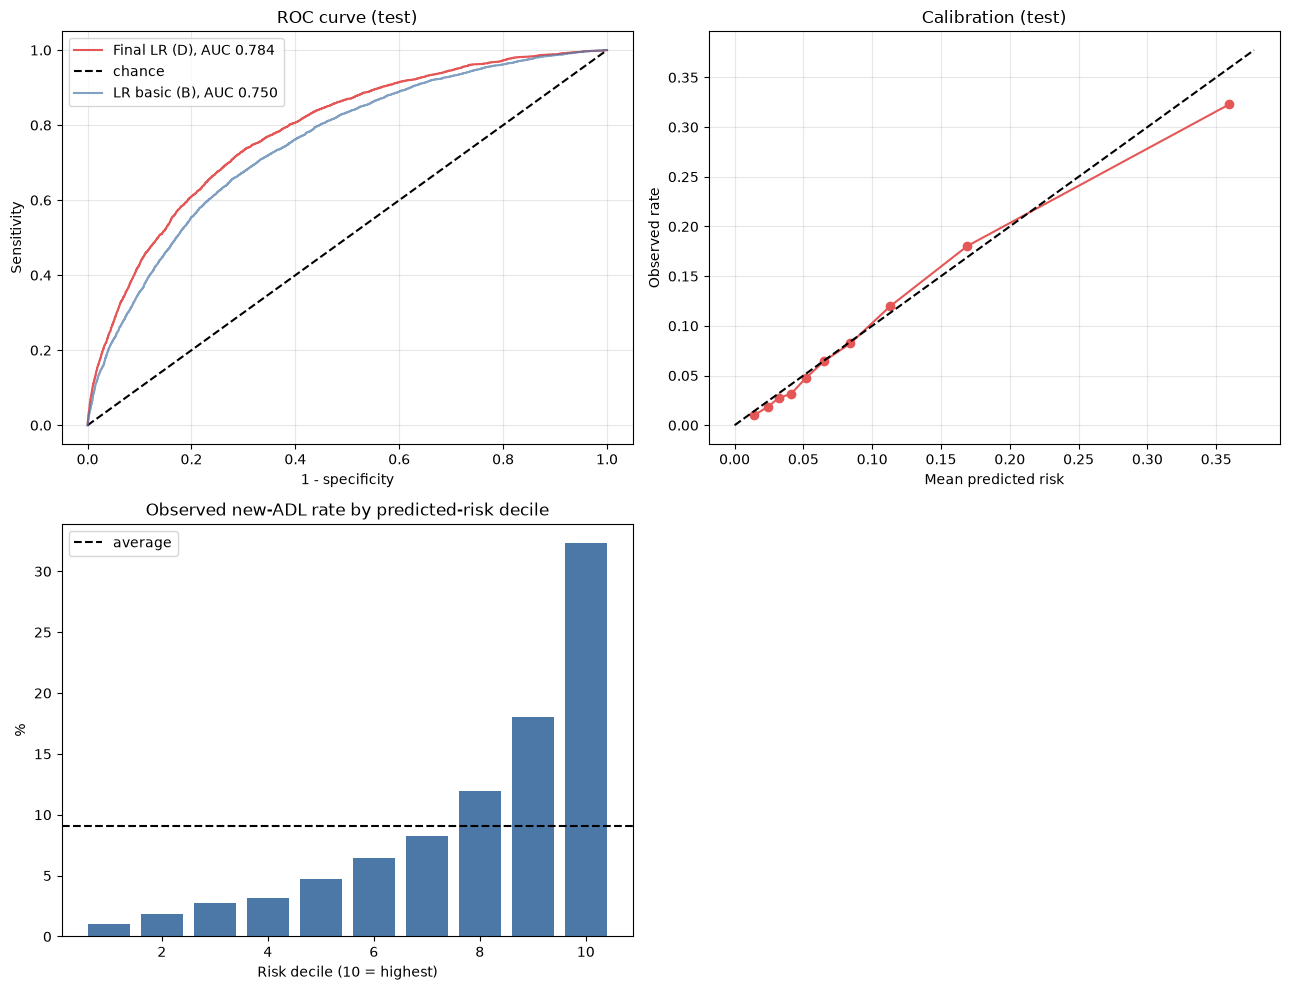

Saved to easyshare_outputs : final_model_performance.csv, final_model_vs_others.csv, final_model_risk_deciles.csv, final_model_figures.png


In [41]:
FINAL = "10 LR + functional (D)"
fr = RESULTS[FINAL]; pf = fr["p_test"]; thr_f = fr["thr"]; predf = (pf >= thr_f).astype(int)

# (a) performance table with household-clustered bootstrap CIs
def boot_ci(fn, n=N_BOOT):
    """Household-clustered bootstrap 95 % confidence interval of a test metric of the final model.

    Whole households are resampled with replacement (spouses are not independent).
    Uses the global objects `bounds`, `order` (household structure of the test set), `y_test`, `pf` and `predf`.

    Args:
        fn (callable): Metric function fn(y, p, d) with true outcome y, probabilities p and 0/1 decisions d.
        n (int): Number of bootstrap replications.

    Returns:
        np.ndarray: [2.5th, 97.5th] percentile of the metric.
    """
    r_ = np.random.default_rng(1); out = []
    for _ in range(n):
        g = r_.integers(0, len(bounds) - 1, len(bounds) - 1)
        idx = np.concatenate([order[bounds[i]:bounds[i + 1]] for i in g]); out.append(fn(y_test[idx], pf[idx], predf[idx]))
    return np.percentile(out, [2.5, 97.5])
def sens(y, p, d): 
    """Sensitivity (recall): share of people with a new limitation who are flagged.

    Args:
        y (np.ndarray): True outcome (0/1).
        p (np.ndarray): Predicted probabilities (unused; common signature).
        d (np.ndarray): Decisions (1 = flagged).

    Returns:
        float: Sensitivity.
    """
    return d[y == 1].mean()
def spec(y, p, d): 
    """Specificity: share of people without a new limitation who are not flagged.

    Args:
        y (np.ndarray): True outcome (0/1).
        p (np.ndarray): Predicted probabilities (unused).
        d (np.ndarray): Decisions (1 = flagged).

    Returns:
        float: Specificity.
    """
    return 1 - d[y == 0].mean()
def ppv(y, p, d): 
    """Positive predictive value (precision): share of flagged people who develop a limitation.

    Args:
        y (np.ndarray): True outcome (0/1).
        p (np.ndarray): Predicted probabilities (unused).
        d (np.ndarray): Decisions (1 = flagged).

    Returns:
        float: PPV, NaN if nobody is flagged.
    """
    return y[d == 1].mean() if d.sum() else np.nan
def npv(y, p, d): 
    """Negative predictive value: share of non-flagged people who stay free of a new limitation.

    Args:
        y (np.ndarray): True outcome (0/1).
        p (np.ndarray): Predicted probabilities (unused).
        d (np.ndarray): Decisions (1 = flagged).

    Returns:
        float: NPV.
    """
    return 1 - y[d == 0].mean()
perf = []
for nm_, fn in [("AUC", lambda y, p, d: roc_auc_score(y, p)), ("PR-AUC", lambda y, p, d: average_precision_score(y, p)),
                ("Brier score", lambda y, p, d: brier_score_loss(y, p)), ("Sensitivity (recall)", sens), ("Specificity", spec),
                ("PPV (precision)", ppv), ("NPV", npv)]:
    pt_ = fn(y_test, pf, predf); lo, hi = boot_ci(fn)
    perf.append({"metric": nm_, "estimate": round(pt_, 3), "95% CI": f"{lo:.3f} - {hi:.3f}"})
p20_, r20_, l20_ = topk(y_test, pf, 0.20)
perf += [{"metric": "Precision in the 20% highest-risk", "estimate": round(p20_, 3), "95% CI": ""},
         {"metric": "Share of all new cases captured in top 20%", "estimate": round(r20_, 3), "95% CI": ""},
         {"metric": "Lift in top 20%", "estimate": round(l20_, 2), "95% CI": ""},
         {"metric": "Threshold (max F1 on validation)", "estimate": round(thr_f, 3), "95% CI": ""},
         {"metric": "Test prevalence", "estimate": round(y_test.mean(), 3), "95% CI": ""}]
perf = pd.DataFrame(perf); print(perf.to_string(index=False)); perf.to_csv(f"{OUT}/final_model_performance.csv", index=False)

# (b) comparison with other models (one row each)
cmp_ = results_table.loc[[n for n in [FINAL, "3 LR (B)", "5 Random forest tuned (B)", "6 LR extended (C)", "13 LR + trend (D+T)"]
                          if n in results_table.index], ["test_AUC", "AUC_95CI", "PR_AUC", "Brier", "recall@top20%", "lift@top20%"]]
print("\n", cmp_.round(3).to_string()); cmp_.round(4).to_csv(f"{OUT}/final_model_vs_others.csv")

# (c) risk deciles: observed new-ADL rate by predicted-risk group
dec = pd.qcut(pd.Series(pf).rank(method="first"), 10, labels=range(1, 11))
dtab = pd.DataFrame({"decile": dec, "y": y_test, "p": pf}).groupby("decile", observed=True).agg(n=("y", "size"), predicted_risk=("p", "mean"), observed_rate=("y", "mean"))
dtab["share_of_all_cases_%"] = dtab["observed_rate"] * dtab["n"] / y_test.sum() * 100
print("\nRisk deciles (1 = lowest predicted risk, 10 = highest)\n", dtab.round(3).to_string()); dtab.round(4).to_csv(f"{OUT}/final_model_risk_deciles.csv")

# (d) figures: ROC + calibration + deciles + odds-ratio forest plot
fig, ax = plt.subplots(2, 2, figsize=(13, 10))
fpr, tpr, _ = roc_curve(y_test, pf); ax[0, 0].plot(fpr, tpr, color="#E45756"); ax[0, 0].plot([0, 1], [0, 1], "k--")
fpr2, tpr2, _ = roc_curve(y_test, RESULTS["3 LR (B)"]["p_test"]); ax[0, 0].plot(fpr2, tpr2, color="#4C78A8", alpha=.7)
ax[0, 0].legend([f"Final LR (D), AUC {roc_auc_score(y_test, pf):.3f}", "chance", f"LR basic (B), AUC {roc_auc_score(y_test, RESULTS['3 LR (B)']['p_test']):.3f}"])
ax[0, 0].set(title="ROC curve (test)", xlabel="1 - specificity", ylabel="Sensitivity"); ax[0, 0].grid(alpha=.3)
fp_, mp_ = calibration_curve(y_test, pf, n_bins=10, strategy="quantile"); mx = max(mp_.max(), fp_.max()) * 1.05
ax[0, 1].plot(mp_, fp_, marker="o", color="#E45756"); ax[0, 1].plot([0, mx], [0, mx], "k--")
ax[0, 1].set(title="Calibration (test)", xlabel="Mean predicted risk", ylabel="Observed rate"); ax[0, 1].grid(alpha=.3)
ax[1, 0].bar(dtab.index.astype(int), dtab["observed_rate"] * 100, color="#4C78A8"); ax[1, 0].axhline(y_test.mean() * 100, color="k", ls="--", label="average")
ax[1, 0].set(title="Observed new-ADL rate by predicted-risk decile", xlabel="Risk decile (10 = highest)", ylabel="%"); ax[1, 0].legend()
try:
    t_ = or_D.copy().sort_values("OR")
    yy = np.arange(len(t_)); ax[1, 1].errorbar(t_["OR"], yy, xerr=[t_["OR"] - t_["CI_low"], t_["CI_high"] - t_["OR"]], fmt="o", color="#E45756", ecolor="#999")
    ax[1, 1].axvline(1, color="k", ls="--"); ax[1, 1].set_yticks(yy); ax[1, 1].set_yticklabels(t_.index, fontsize=7); ax[1, 1].set_xscale("log")
    ax[1, 1].set(title="Odds ratios (95% CI), model D", xlabel="OR (log scale)")
except NameError:
    ax[1, 1].axis("off")
plt.tight_layout(); plt.savefig(f"{OUT}/final_model_figures.png", dpi=200); plt.show()
print("Saved to", OUT, ": final_model_performance.csv, final_model_vs_others.csv, final_model_risk_deciles.csv, final_model_figures.png")

**Result:**
1. **Discrimination.** The final logistic regression with functional indicators reaches an AUC of 0.784 (95 % CI 0.777–0.790; random model 0.5) and a PR-AUC of 0.295 (random model: prevalence 0.090). It clearly outperforms the basic model LR (B) (0.750), while adding trend variables (LR D+T, 0.790) raises the AUC by only 0.006 with overlapping confidence intervals.
2. **Calibration and risk groups.** Predicted and observed risks agree well across the ten risk deciles. The observed new-limitation rate rises from 1.0 % in the lowest to 32.3 % in the highest decile (slight over-prediction in the top decile: 35.9 % predicted). The 20 % highest-risk people contain 55.6 % of all new cases (lift 2.78), and the top three deciles contain about 69 %.
3. **Decision threshold.** At the threshold 0.183 (maximum F1 on the validation period) the model has a sensitivity of 43.1 %, a specificity of 89.9 %, a PPV of 29.9 % and an NPV of 94.1 %. Roughly 70 % of the flagged people are false alarms and 57 % of the new cases are missed.
4. **Use.** The model is useful for risk ranking and for targeting population screening or prevention at the highest-risk groups, but its limited sensitivity and PPV mean that it should not be used alone for individual-level decisions.

### Choice of the probability threshold for the final model

**Aim:** Show how the share of people flagged, precision, recall and F1 change with the probability threshold, and check that the threshold chosen on the validation period (0.183) also works in the test period.

**Why:** The model outputs probabilities. To flag people, a threshold is needed: a low threshold finds more cases but produces many false alarms, a high threshold flags few people with high precision but misses most cases.

**Method:** For thresholds from 0.05 to 0.50 (plus the chosen 0.183), flag everybody whose predicted risk is at least the threshold and compute, separately for the validation and the test period, the share flagged, precision (PPV), recall (sensitivity) and F1. The threshold with the highest validation F1 was chosen; the figure shows the three validation curves.

**Input:** Predicted risks of the final model for the validation and test period, true outcomes, chosen threshold.

**Decision rule:** The threshold with the highest F1 on the validation period is chosen; its behaviour on the test period shows whether it transfers.

 threshold                  chosen  flagged_% (val)  precision (val)  recall (val)  F1 (val)  flagged_% (test)  precision (test)  recall (test)  F1 (test)
     0.050                                   57.901            0.146         0.904     0.251            56.171             0.143          0.885      0.246
     0.100                                   31.429            0.216         0.727     0.333            28.670             0.212          0.673      0.323
     0.150                                   19.760            0.270         0.572     0.367            17.311             0.266          0.508      0.349
     0.183 <-- max F1 (validation)           15.247            0.302         0.494     0.375            13.019             0.299          0.430      0.352
     0.200                                   13.408            0.314         0.451     0.370            11.402             0.311          0.391      0.346
     0.250                                    9.422            0.357  

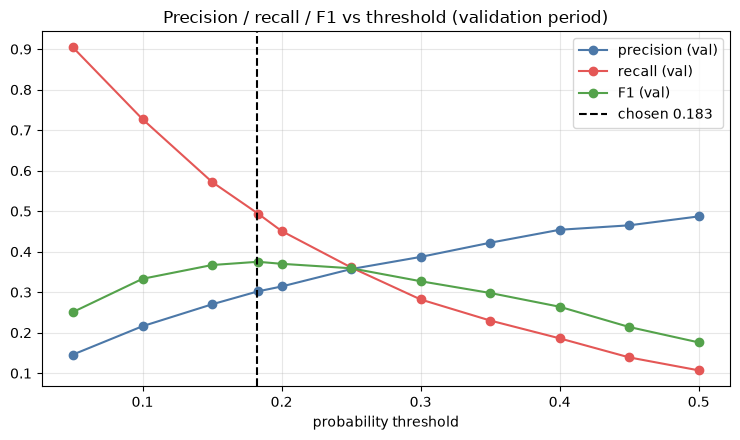

In [42]:
yv = val["y"].values; pv_f = fr["p_val"]
grid = sorted(set(list(np.round(np.arange(0.05, 0.55, 0.05), 3)) + [round(thr_f, 3)]))
rows = []
for t in grid:
    row = {"threshold": t, "chosen": "<-- max F1 (validation)" if abs(t - round(thr_f, 3)) < 1e-9 else ""}
    for tag, yy, pp in [("val", yv, pv_f), ("test", y_test, pf)]:
        d_ = pp >= t
        prec = yy[d_].mean() if d_.sum() else np.nan; rec = yy[d_].sum() / yy.sum()
        row.update({f"flagged_% ({tag})": d_.mean() * 100, f"precision ({tag})": prec, f"recall ({tag})": rec,
                    f"F1 ({tag})": 2 * prec * rec / (prec + rec) if d_.sum() and (prec + rec) > 0 else np.nan})
    rows.append(row)
thr_tab = pd.DataFrame(rows).round(3); print(thr_tab.to_string(index=False)); thr_tab.to_csv(f"{OUT}/threshold_table_final_model.csv", index=False)
fig, ax = plt.subplots(figsize=(7.5, 4.5))
for c_, col in [("precision (val)", "#4C78A8"), ("recall (val)", "#E45756"), ("F1 (val)", "#54A24B")]:
    ax.plot(thr_tab["threshold"], thr_tab[c_], marker="o", label=c_, color=col)
ax.axvline(thr_f, color="k", ls="--", label=f"chosen {thr_f:.3f}"); ax.set(xlabel="probability threshold", title="Precision / recall / F1 vs threshold (validation period)")
ax.grid(alpha=.3); ax.legend(); savefig("final_model_threshold_curve")

**Result:**

1. The threshold 0.183 maximises the F1 score on the validation period (0.375). In the test period F1 is 0.352; precision is stable (0.302 vs 0.299), recall is lower (0.494 vs 0.430) because fewer people reach the threshold in the test period (13.0 % vs 15.2 % flagged).
2. The F1 curve is flat between thresholds of 0.15 and 0.20 (validation F1 0.367–0.375, test F1 0.346–0.352), so the exact value is not critical.
3. The threshold determines the trade-off: at 0.10, 29 % of people are flagged and 67 % of the new cases are found, but only 21 % of the flagged develop a limitation; at 0.30, 6 % are flagged, 23 % of the cases are found and the precision is 38 %. F1 weights precision and recall equally and ignores the costs of false alarms and missed cases, so in practice the threshold should be set according to the capacity and costs of follow-up (see the decision curve analysis).

### One baseline per person in the training data
**Aim:** Check whether the model depends on persons who contribute several baseline -> follow-up pairs (several waves) to the training data.

**Why:** Pairs of the same person are not independent, and persons with many waves count several times in the fit. If the results were driven by these repeated observations, the model would learn the habits of frequently observed persons rather than general patterns.

**Method:** Repeat 10 times: shuffle the training pairs, keep one randomly chosen pair per person (39,561 of 70,812 rows), refit the model with the hyper-parameters of the main analysis and compute the AUC in the unchanged test period. The mean, SD, minimum and maximum of the 10 AUC values are compared with the main result for four models.

**Input:** Training pairs, test pairs, stored settings of models 3, 10, 13 and 14.

**Decision rule:** If the AUC hardly changes, repeated observations do not drive the result.

In [43]:
def one_per_person_auc(name, reps=3 if FAST else 10):
    """Test AUC of a model refitted on one randomly chosen baseline pair per person.

    Repeats the random selection `reps` times, refits the model with the hyper-parameters of the main analysis on the
    selected pairs and evaluates it on the unchanged test period. Uses the global objects `RESULTS`, `trv` and `test`.

    Args:
        name (str): Model name (key in `RESULTS`).
        reps (int): Number of random draws (3 in the fast run, otherwise 10).

    Returns:
        tuple: (training rows per draw, mean test AUC, SD, minimum, maximum over the draws).
    """
    r = RESULTS[name]; feats = r["feats"]; out = []
    for k in range(reps):
        sub = trv.sample(frac=1, random_state=100 + k).drop_duplicates("mergeid")        # random pair per person
        m = fit_model(r["build"](), sub[feats], sub["y"])
        out.append(roc_auc_score(test["y"], m.predict_proba(test[feats])[:, 1]))
    return len(sub), np.mean(out), np.std(out), np.min(out), np.max(out)

rows17 = []
for nm_ in [n for n in ["3 LR (B)", "10 LR + functional (D)", "13 LR + trend (D+T)"] if n in RESULTS]:
    n_sub, mu, sd, lo, hi = one_per_person_auc(nm_)
    rows17.append({"model": nm_, "main test AUC (all pairs)": round(roc_auc_score(test["y"], RESULTS[nm_]["p_test"]), 4),
                   "one pair per person: mean AUC": round(mu, 4), "sd": round(sd, 4), "min-max": f"{lo:.4f}-{hi:.4f}",
                   "training rows": f"{n_sub:,} (vs {len(trv):,})"})
t17 = pd.DataFrame(rows17); print(t17.to_string(index=False)); t17.to_csv(f"{OUT}/sensitivity_one_pair_per_person.csv", index=False)

                 model  main test AUC (all pairs)  one pair per person: mean AUC     sd       min-max      training rows
              3 LR (B)                     0.7504                         0.7499 0.0003 0.7495-0.7505 39,561 (vs 70,812)
10 LR + functional (D)                     0.7837                         0.7826 0.0004 0.7820-0.7832 39,561 (vs 70,812)
   13 LR + trend (D+T)                     0.7898                         0.7881 0.0003 0.7876-0.7886 39,561 (vs 70,812)


**Result:**
1. Keeping one randomly chosen baseline per person reduces the training data from 70,812 to 39,561 rows. The test AUC of the logistic regressions hardly changes (LR (B) 0.7504 → 0.7499, LR (D) 0.7837 → 0.7826, LR (D+T) 0.7898 → 0.7881) and is very stable across the 10 random draws (SD about 0.0003). The advantage of the functional indicators over the basic model remains (+0.033 AUC).
2. Repeated observations of the same person therefore do not drive the results, which supports LR (D) as a robust and interpretable primary model.


### Rolling-origin validation: does performance hold up over time?
**Aim.** Check whether the model's performance is stable over successive time periods and not only in the single test period of the main analysis.

**Why.** The main analysis uses one split in time. Performance could depend on that particular split, and the later waves differ (wave 7 contains SHARELIFE respondents, wave 8 -> 9 spans COVID-19).

**Method.** For each test wave pair (baseline 5, 6, 7, 8) train the model on all earlier baseline waves only (expanding window) and evaluate it on that wave pair. The 95 % confidence interval of the AUC comes from 200 household-clustered bootstrap samples of the test pair. Besides the AUC, the mean predicted risk is compared with the observed event rate (calibration-in-the-large).

**Input.** All baseline -> follow-up pairs; three models (LR B, LR D, LR D+T) with the hyper-parameters of the main analysis.

**Decision rule.** A model is stable if the AUC stays similar across the wave pairs and the ranking of the models does not change.

test pairs               5->6   6->7   7->8   8->9
model                                             
10 LR + functional (D)  0.781  0.799  0.778  0.793
13 LR + trend (D+T)     0.786  0.804  0.785  0.799
3 LR (B)                0.761  0.763  0.743  0.759

Calibration-in-the-large (mean predicted vs observed event rate):
test pairs               5->6   6->7   7->8   8->9
model                                             
10 LR + functional (D)  0.108  0.104  0.096  0.094
13 LR + trend (D+T)     0.108  0.104  0.094  0.093
3 LR (B)                0.107  0.107  0.099  0.101
test pairs
5->6    0.102
6->7    0.093
7->8    0.101
8->9    0.080


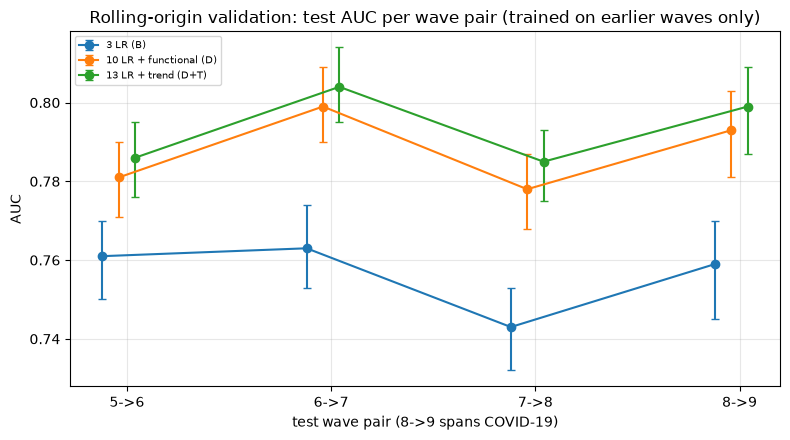

In [44]:
ROLL_MODELS = [n for n in ["3 LR (B)", "10 LR + functional (D)", "13 LR + trend (D+T)"] if n in RESULTS]
roll_rows = []
for tw in [int(w) for w in sorted(pairs["baseline_wave"].unique()) if w >= 5]:
    tr_ = pairs[pairs["baseline_wave"] < tw]; te_ = pairs[pairs["baseline_wave"] == tw]
    if te_["y"].nunique() < 2 or len(tr_) < 1000:
        continue
    g_ = pd.factorize(te_["hh_key"])[0]; o_ = np.argsort(g_, kind="stable"); b_ = np.r_[0, np.cumsum(np.bincount(g_))]
    yt = te_["y"].values
    for nm_ in ROLL_MODELS:
        r = RESULTS[nm_]; m = fit_model(r["build"](), tr_[r["feats"]], tr_["y"]); pp = m.predict_proba(te_[r["feats"]])[:, 1]
        rg = np.random.default_rng(7); bs = []
        for _ in range(N_BOOT):
            gg = rg.integers(0, len(b_) - 1, len(b_) - 1); ix = np.concatenate([o_[b_[i]:b_[i + 1]] for i in gg])
            bs.append(roc_auc_score(yt[ix], pp[ix]))
        roll_rows.append({"test pairs": f"{tw}->{tw + 1}", "train baselines": f"<{tw}", "model": nm_, "n_train": len(tr_), "n_test": len(te_),
                          "event rate": round(yt.mean(), 3), "AUC": round(roc_auc_score(yt, pp), 3),
                          "AUC 95% CI": f"{np.percentile(bs, 2.5):.3f}-{np.percentile(bs, 97.5):.3f}",
                          "PR-AUC": round(average_precision_score(yt, pp), 3), "Brier": round(brier_score_loss(yt, pp), 4),
                          "mean predicted": round(pp.mean(), 3)})
roll = pd.DataFrame(roll_rows)
print(roll.pivot(index="model", columns="test pairs", values="AUC").to_string())
print("\nCalibration-in-the-large (mean predicted vs observed event rate):")
print(roll.pivot(index="model", columns="test pairs", values="mean predicted").to_string()); print(roll.groupby("test pairs")["event rate"].first().to_string())
roll.to_csv(f"{OUT}/rolling_origin_validation.csv", index=False)
fig, ax = plt.subplots(figsize=(8, 4.5))
for k_, nm_ in enumerate(ROLL_MODELS):
    d_ = roll[roll["model"] == nm_]; lo_ = d_["AUC 95% CI"].str.split("-").str[0].astype(float); hi_ = d_["AUC 95% CI"].str.split("-").str[1].astype(float)
    xs = np.arange(len(d_)) + (k_ - len(ROLL_MODELS) / 2) * 0.08
    ax.errorbar(xs, d_["AUC"], yerr=[d_["AUC"] - lo_, hi_ - d_["AUC"]], marker="o", capsize=3, label=nm_)
ax.set_xticks(range(roll["test pairs"].nunique())); ax.set_xticklabels(sorted(roll["test pairs"].unique()))
ax.set(title="Rolling-origin validation: test AUC per wave pair (trained on earlier waves only)", ylabel="AUC", xlabel="test wave pair (8->9 spans COVID-19)")
ax.grid(alpha=.3); ax.legend(fontsize=7); savefig("rolling_origin_auc")

**Result:**
1. LR (D) outperforms LR (B) in every wave pair (AUC 0.781 vs 0.761, 0.799 vs 0.763, 0.778 vs 0.743 and 0.793 vs 0.759), so the value of the functional indicators does not depend on the chosen test period. Adding trend variables raises the AUC by only 0.005–0.007 in each period.
2. Performance is stable over time. All models lose about 0.02 AUC in the pair 7 -> 8, which is probably linked to the SHARELIFE respondents of wave 7, and recover in 8 -> 9; the COVID-19 pair is therefore not worse (LR (D): 0.793).
3. LR (D) predicts event rates within about 1.4 percentage points of the observed rates (largest deviation in 8 -> 9: 9.4 % predicted vs 8.0 % observed).
4. These findings support logistic regression with functional indicators as the primary model: its discrimination and its absolute risks are stable across time periods.

*Note:* hyper-parameters come from the main analysis (selected on the validation period), so the estimates for 5 -> 6 and 6 -> 7 are slightly optimistic.


### Decision curve analysis: is the model useful for deciding whom to follow up?

**Aim:** Show whether using the final model to decide whom to flag does more good than harm compared with the two default strategies "flag everyone" and "flag nobody", over a range of decision thresholds.

**Why:** AUC and calibration do not say whether acting on the predictions is worthwhile. The answer depends on how many false alarms one is willing to accept per case found; this willingness is expressed by the risk threshold pt.

**Method:** For every threshold pt from 5 % to 40 % people with a predicted risk of at least pt are flagged and the net benefit is computed: net benefit = true positives / n - false positives / n x pt / (1 - pt). A threshold pt means that one true case is worth (1 - pt) / pt false alarms (pt = 0.10: nine false alarms, pt = 0.20: four, pt = 0.30: about 2.3). The net benefit of the final model is compared with "flag everyone", "flag nobody" and two other models; the 95 % confidence band of the final model comes from 200 household-clustered bootstrap samples. For selected thresholds the gain over "flag everyone" is also expressed as avoided unnecessary follow-ups per 100 people.

**Input:** Test-period predictions of models 10, 3 and 14 and the observed outcomes.

**Decision rule:** A model is useful at a threshold if its net benefit is above both "flag everyone" and zero ("flag nobody").

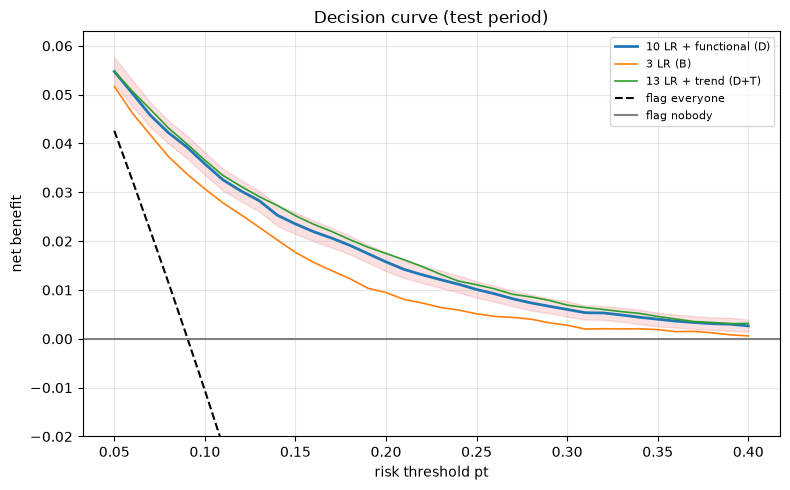

 threshold  NB final model  NB flag everyone  share flagged  gain vs flag-everyone  avoided false alarms per 100
      0.10          0.0358           -0.0106         0.2867                 0.0464                       41.7653
      0.15          0.0235           -0.0700         0.1731                 0.0936                       53.0117
      0.20          0.0158           -0.1369         0.1140                 0.1527                       61.0626
      0.25          0.0101           -0.2127         0.0787                 0.2228                       66.8403
      0.30          0.0060           -0.2993         0.0556                 0.3053                       71.2454
Thresholds (5%-40%) where the final model beats both default strategies: 0.05 to 0.4 (36 of 36 grid points)


In [45]:
def net_benefit(y, p, pt):
    """Net benefit of flagging people whose predicted risk is at least `pt` (decision curve analysis).

    Net benefit = true positives / n - false positives / n * pt / (1 - pt). The factor pt / (1 - pt) is the
    weight of a false alarm relative to a correctly flagged case.

    Args:
        y (np.ndarray): True outcome (0/1).
        p (np.ndarray): Predicted probabilities.
        pt (float): Risk threshold, between 0 and 1.

    Returns:
        float: Net benefit per person.
    """
    n = len(y); flag = p >= pt
    return (np.sum(flag & (y == 1)) - np.sum(flag & (y == 0)) * pt / (1 - pt)) / n

pts = np.arange(0.05, 0.401, 0.01)
DCA_MODELS = [n for n in ["10 LR + functional (D)", "3 LR (B)", "13 LR + trend (D+T)"] if n in RESULTS]
nb = {n: np.array([net_benefit(y_test, RESULTS[n]["p_test"], t) for t in pts]) for n in DCA_MODELS}
prev = y_test.mean(); nb_all = np.array([prev - (1 - prev) * t / (1 - t) for t in pts])
rg = np.random.default_rng(11); bs = []
for _ in range(N_BOOT):
    gg = rg.integers(0, len(bounds) - 1, len(bounds) - 1); ix = np.concatenate([order[bounds[i]:bounds[i + 1]] for i in gg])
    bs.append([net_benefit(y_test[ix], pf[ix], t) for t in pts])
lo_b, hi_b = np.percentile(bs, [2.5, 97.5], axis=0)

fig, ax = plt.subplots(figsize=(8, 5))
ax.fill_between(pts, lo_b, hi_b, color="#E45756", alpha=.18)
for n in DCA_MODELS: ax.plot(pts, nb[n], label=n, lw=2 if n == FINAL else 1.2)
ax.plot(pts, nb_all, "k--", label="flag everyone"); ax.axhline(0, color="grey", label="flag nobody")
ax.set(ylim=(-0.02, max(nb_all.max(), nb[FINAL].max()) * 1.15), xlabel="risk threshold pt", ylabel="net benefit",
       title="Decision curve (test period)"); ax.grid(alpha=.3); ax.legend(fontsize=8); savefig("decision_curve")

sel = [0.10, 0.15, 0.20, 0.25, 0.30]
dca = pd.DataFrame({"threshold": sel,
                    "NB final model": [net_benefit(y_test, pf, t) for t in sel],
                    "NB flag everyone": [prev - (1 - prev) * t / (1 - t) for t in sel],
                    "share flagged": [(pf >= t).mean() for t in sel]})
dca["gain vs flag-everyone"] = dca["NB final model"] - dca["NB flag everyone"]
# net reduction in unnecessary follow-ups per 100 people at equal sensitivity to "flag everyone":  (NB_model - NB_all) / (pt/(1-pt)) * 100
dca["avoided false alarms per 100"] = dca["gain vs flag-everyone"] / (dca["threshold"] / (1 - dca["threshold"])) * 100
print(dca.round(4).to_string(index=False)); dca.round(4).to_csv(f"{OUT}/decision_curve_table.csv", index=False)
better = [round(float(t), 2) for t, a_, b_ in zip(pts, nb[FINAL], nb_all) if a_ > max(b_, 0)]
print("Thresholds (5%-40%) where the final model beats both default strategies:",
      f"{min(better)} to {max(better)} ({len(better)} of {len(pts)} grid points)" if better else "none")

**Result:**
1. The final model (LR D) has a higher net benefit than both "flag everyone" and "flag nobody" at every threshold of the examined range (5-40 %, 36 of 36 grid points), and a higher net benefit than the basic model LR (B) throughout. Adding the trend variables (LR D+T) is not clearly better than LR (D).
2. For thresholds of 10-30 %, which correspond to accepting about nine to two false alarms per correctly flagged case, the net benefit is 0.036 at 10 %, 0.016 at 20 % and 0.006 at 30 % (a perfect model would reach the prevalence, 0.090). At the 10 % threshold, 28.7 % of people are flagged, and the gain over flagging everyone corresponds to about 42 avoided unnecessary follow-ups per 100 people.
3. The net benefit decreases with the threshold because fewer people, and fewer cases, are flagged; the growing advantage over "flag everyone" at high thresholds reflects the poor performance of that strategy, not a better model.
4. The model is therefore most useful for risk screening when missing a case is costly and follow-up is cheap, i.e. at lower thresholds. The appropriate threshold must be chosen by the users of the model according to the costs of the intervention; the curve assumes calibrated probabilities.

## Main findings and limitations

**Main findings**
1. **Data Cleaning**: The data contained a serious coding problem, the easySHARE special missing codes (-3 ... -16) had been used as real numbers. Cleaning them alone improves the original model from AUC 0.734 to 0.749.
2. Among the nine original variables a logistic regression reaches AUC 0.750 (test period 2017-2022); adding social, cognitive and lifestyle variables gives 0.763.
3. **adding new factors:** The largest gain comes from new information **baseline functional indicators** (mobility, large-muscle, IADL difficulties) raise the AUC to **0.784** (+0.033, 95 % CI 0.029-0.037). Trend features add only about 0.007.
4. **Algorithms matter little**: logistic regression, elastic net and random forest perform almost identically once they get the same information (feature set B: 0.750 vs 0.751 for the random forest; set D: 0.784 for LR and elastic net). PCA gives no benefit (best number of components = all 8).
5. Strongest predictors: self-rated health, age, large-muscle and mobility difficulties, IADL difficulty, sex (women lower risk), grip strength, having received help, activity level. Chronic diseases and income **lose their effect once functional indicators are included.**
6. The final logistic model ranks people well and is well calibrated.
7. The result is robust to the outcome definition.

**Limitations**
- Only people who are interviewed again enter the data (retention 56-79 %);
- The follow-up is the *next interview* (mostly 2 years), not a fixed time window.
- The model supports ranking and screening, not individual diagnosis.
- Associations are not causal effects; `received_help` includes personal-care help and is a marker of vulnerability.
- Country differences are large; the 2020-2022 follow-ups are affected by COVID-19; ADL is self-reported.

**Best model for the report.** Logistic regression with feature set D (odds ratios available, AUC 0.784); LR with trend features (AUC 0.790) as a comparison that shows little additional gain.